In [2]:
import sys
import pandas as pd

print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)

Python executable: d:\STUDY\TY\DWM\dwml_project\.venv\Scripts\python.exe
Pandas version: 3.1.0


In [3]:
from pathlib import Path
import pandas as pd

DATASET_PATH = Path("LAPD_NIBRS_Offenses_Dataset_20261022.csv")

print("Dataset exists:", DATASET_PATH.exists())
print("Dataset size:", round(DATASET_PATH.stat().st_size / (1024**2), 2), "MB")

df = pd.read_csv(DATASET_PATH, low_memory=False)

print("\nDataset shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)

Dataset exists: True
Dataset size: 173.48 MB

Dataset shape: (498741, 31)

Column data types:
CaseNo                         str
UniqueNIBRNo                   str
Date Rptd                      str
Date OCC                       str
Time OCC                     int64
AREA                         int64
AREA NAME                      str
RPT Dist No                  int64
TotalOffenseCount            int64
Group                          str
NIBR Code                      str
NIBR Description               str
Crime Against                  str
Premise Cd                     str
Premise Desc                   str
Weapon Used Cd                 str
Weapon Desc                    str
Status                     float64
Status Desc                    str
TotalVictimCount             int64
Victim Shot                    str
Domestic Violence Crime        str
Hate Crime                     str
Gang-related Crime             str
Transit-related Crime          str
Homeless-Victim Crime          

In [4]:
# Count missing values in each column
missing = df.isna().sum()

missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_report[missing_report["Missing Count"] > 0])

,Missing Count,Missing Percentage
Weapon Used Cd,352298,70.64
Weapon Desc,352298,70.64
Premise Cd,23051,4.62
Group,15840,3.18
Date Rptd,7940,1.59
Crime Against,2388,0.48
NIBR Code,1236,0.25
Status,1132,0.23
Status Desc,1130,0.23
LAT,131,0.03


In [5]:
# Count empty or whitespace-only strings in each column
empty_counts = {}

for col in df.select_dtypes(include=["str", "object"]).columns:
    empty_mask = df[col].str.strip().eq("")
    empty_counts[col] = empty_mask.sum()

empty_report = pd.Series(empty_counts, name="Empty/Whitespace Count")
empty_report = empty_report[empty_report > 0].sort_values(ascending=False)

display(empty_report.to_frame())

,Empty/Whitespace Count


In [6]:
# Parse offense dates using the format observed in the dataset
df["Date OCC"] = pd.to_datetime(
    df["Date OCC"],
    format="%Y %b %d %I:%M:%S %p",
    errors="coerce"
)

print("Total records:", len(df))
print("Valid offense dates:", df["Date OCC"].notna().sum())
print("Missing or invalid dates:", df["Date OCC"].isna().sum())

print("\nEarliest offense date:", df["Date OCC"].min())
print("Latest offense date:", df["Date OCC"].max())

print("\nRecords by year:")
print(df["Date OCC"].dt.year.value_counts().sort_index())

Total records: 498741
Valid offense dates: 498741
Missing or invalid dates: 0

Earliest offense date: 1800-01-06 00:00:00
Latest offense date: 2026-10-03 00:00:00

Records by year:
Date OCC
1800         2
1826         1
1900         1
1920         1
1925         1
         ...  
2022      1054
2023      2158
2024    103051
2025    223399
2026    165309
Name: count, Length: 65, dtype: int64


In [7]:
# Keep offense records from 2024 onward
start_date = pd.Timestamp("2024-01-01")
end_date = pd.Timestamp("2026-12-31 23:59:59")

df_filtered = df[
    df["Date OCC"].between(start_date, end_date)
].copy()

print("Original records:", len(df))
print("Records retained:", len(df_filtered))
print("Records excluded:", len(df) - len(df_filtered))

print("\nRecords by year:")
print(df_filtered["Date OCC"].dt.year.value_counts().sort_index())

Original records: 498741
Records retained: 491759
Records excluded: 6982

Records by year:
Date OCC
2024    103051
2025    223399
2026    165309
Name: count, dtype: int64


In [8]:
# Inspect coordinate quality in our filtered dataset

print("Missing latitude:", df_filtered["LAT"].isna().sum())
print("Missing longitude:", df_filtered["LON"].isna().sum())

print("\nLatitude summary:")
display(df_filtered["LAT"].describe())

print("\nLongitude summary:")
display(df_filtered["LON"].describe())

# Check coordinates outside a broad Los Angeles bounding box
invalid_coordinates = (
    ~df_filtered["LAT"].between(33.0, 35.0)
    | ~df_filtered["LON"].between(-119.0, -117.0)
)

print("\nRecords outside the broad LA bounding box:", invalid_coordinates.sum())

Missing latitude: 126
Missing longitude: 126

Latitude summary:


count    491633.000000
mean         34.038867
std           1.141235
min           0.000000
25%          34.021300
50%          34.060100
75%          34.166600
max          34.760900
Name: LAT, dtype: float64


Longitude summary:


count    491633.000000
mean       -118.219819
std           3.946929
min        -118.827600
25%        -118.427100
50%        -118.313800
75%        -118.272200
max           0.000000
Name: LON, dtype: float64


Records outside the broad LA bounding box: 673


In [9]:
# Inspect records with suspicious coordinates
invalid_coordinates = (
    df_filtered["LAT"].isna()
    | df_filtered["LON"].isna()
    | (df_filtered["LAT"] == 0)
    | (df_filtered["LON"] == 0)
    | ~df_filtered["LAT"].between(33.0, 35.0)
    | ~df_filtered["LON"].between(-119.0, -117.0)
)

print("Suspicious coordinate records:", invalid_coordinates.sum())

display(
    df_filtered.loc[
        invalid_coordinates,
        ["CaseNo", "Date OCC", "LOCATION", "LAT", "LON"]
    ].head(20)
)

Suspicious coordinate records: 673


,CaseNo,Date OCC,LOCATION,LAT,LON
2207,25161740,2025-08-29 13:35:00,E I-10 Fwy & Mateo St,0.0,0.0
3006,25163405,2025-08-23 15:30:00,882,NaN,NaN
3457,25160964,2025-08-28 12:40:00,6th Ave & W 48th St,0.0,0.0
6935,25156101,2025-08-21 06:05:00,W I-10 Fwy & S Western Ave,0.0,0.0
12094,25223624,2025-11-29 18:11:08,567,NaN,NaN
12405,25200169,2025-10-23 23:54:00,N I-5 Fwy & N I-110 Fwy,0.0,0.0
18040,25222954,2025-11-26 21:30:00,16th & San Pedro,0.0,0.0
21743,25188482,2025-10-04 19:07:00,10,NaN,NaN
24426,25221771,2025-11-24 12:30:00,10200 Constellation Blvd,0.0,0.0
27884,25184376,2025-10-01 05:30:00,9th & San Pedro,0.0,0.0


In [10]:
import numpy as np

lat = df_filtered["LAT"]
lon = df_filtered["LON"]

missing_coords = lat.isna() | lon.isna()

zero_coords = (
    lat.eq(0) | lon.eq(0)
) & ~missing_coords

outside_la = (
    ~lat.between(33.0, 35.0)
    | ~lon.between(-119.0, -117.0)
).fillna(False) & ~missing_coords & ~zero_coords

print("Total records:", len(df_filtered))
print("Missing coordinates:", missing_coords.sum())
print("Zero coordinates:", zero_coords.sum())
print("Outside broad LA bounds:", outside_la.sum())

print("\nCoordinate issue overlap:")
print("Missing + zero:", (missing_coords & zero_coords).sum())

Total records: 491759
Missing coordinates: 126
Zero coordinates: 547
Outside broad LA bounds: 0

Coordinate issue overlap:
Missing + zero: 0


In [11]:
# Create a working dataset with valid coordinates
valid_coordinates = (
    df_filtered["LAT"].between(33.0, 35.0)
    & df_filtered["LON"].between(-119.0, -117.0)
    & df_filtered["LAT"].ne(0)
    & df_filtered["LON"].ne(0)
)

df_geo = df_filtered.loc[valid_coordinates].copy()

print("Records before coordinate filtering:", len(df_filtered))
print("Records retained for geographic analysis:", len(df_geo))
print("Records excluded from geographic analysis:", len(df_filtered) - len(df_geo))

print("\nRemaining missing coordinates:")
print(df_geo[["LAT", "LON"]].isna().sum())

print("\nCoordinate ranges:")
print("Latitude:", df_geo["LAT"].min(), "to", df_geo["LAT"].max())
print("Longitude:", df_geo["LON"].min(), "to", df_geo["LON"].max())

Records before coordinate filtering: 491759
Records retained for geographic analysis: 491086
Records excluded from geographic analysis: 673

Remaining missing coordinates:
LAT    0
LON    0
dtype: int64

Coordinate ranges:
Latitude: 33.3426 to 34.7609
Longitude: -118.8276 to -117.7167


In [12]:
# Inspect duplicate identifiers

print("Total geographic records:", len(df_geo))

print("\nCaseNo duplicates:")
print(df_geo["CaseNo"].duplicated().sum())

print("\nUniqueNIBRNo duplicates:")
print(df_geo["UniqueNIBRNo"].duplicated().sum())

print("\nExample repeated CaseNo values:")
repeated_cases = df_geo[
    df_geo["CaseNo"].duplicated(keep=False)
]

display(
    repeated_cases[
        ["CaseNo", "UniqueNIBRNo", "Date OCC", "NIBR Code"]
    ].head(10)
)

Total geographic records: 491086

CaseNo duplicates:
50256

UniqueNIBRNo duplicates:
0

Example repeated CaseNo values:


,CaseNo,UniqueNIBRNo,Date OCC,NIBR Code
15,25164452,25164452_23G_0,2025-09-01 01:05:00,23G
16,25164452,25164452_290_1,2025-09-01 01:05:00,290
17,25164453,25164453_13A_0,2025-09-02 17:12:00,13A
18,25164453,25164453_13C_1,2025-09-02 17:12:00,13C
23,25164463,25164463_290_1,2025-09-02 15:36:00,290
24,25164463,25164463_23F_0,2025-09-02 15:36:00,23F
35,25158840,25158840_290_1,2025-08-25 16:00:00,290
36,25158840,25158840_26A_0,2025-08-25 16:00:00,26A
38,25158845,25158845_290_0,2025-08-25 17:40:00,290
39,25158845,25158845_23H_1,2025-08-25 17:40:00,23H


In [13]:
# Check missing values in key analytical fields

key_columns = [
    "UniqueNIBRNo",
    "Date OCC",
    "NIBR Code",
    "NIBR Description",
    "LOCATION",
    "LAT",
    "LON",
]

missing_key_fields = df_geo[key_columns].isna().sum()

print("Missing values in key fields:")
display(missing_key_fields.to_frame(name="Missing Count"))

print("\nDuplicate UniqueNIBRNo values:", df_geo["UniqueNIBRNo"].duplicated().sum())

Missing values in key fields:


,Missing Count
UniqueNIBRNo,0
Date OCC,0
NIBR Code,349
NIBR Description,0
LOCATION,0
LAT,0
LON,0



Duplicate UniqueNIBRNo values: 0


In [14]:
# Investigate records with missing NIBR codes

missing_codes = df_geo["NIBR Code"].isna()

print("Records with missing NIBR codes:", missing_codes.sum())

display(
    df_geo.loc[
        missing_codes,
        ["UniqueNIBRNo", "NIBR Description", "Crime Against", "Group"]
    ].head(20)
)

print("\nCrime Against distribution for missing codes:")
display(df_geo.loc[missing_codes, "Crime Against"].value_counts(dropna=False))

print("\nGroup distribution for missing codes:")
display(df_geo.loc[missing_codes, "Group"].value_counts(dropna=False))

Records with missing NIBR codes: 349


,UniqueNIBRNo,NIBR Description,Crime Against,Group
1843,251604056__0,998 - PROPERTY - EVIDENCE/NON-EVIDENCE,NaN,NaN
1844,251604057__0,998 - PROPERTY - EVIDENCE/NON-EVIDENCE,NaN,NaN
1845,251604057__1,999 - NON-CRIME,NaN,NaN
7983,25155763__0,16028(A) - VC - I - FAIL PROVE FIN RSP:PO REQ -,NaN,NaN
16679,25195512__2,529.5(A) - PC - M - Manufacture/Etc Deceptive ...,NaN,NaN
24765,240206881__0,521 - VEHICLE - RECOVERED,NaN,NaN
25175,240205025__0,110 - CRIMINAL HOMICIDE,NaN,NaN
25198,240208122__0,510 - VEHICLE - STOLEN,NaN,NaN
29275,25219783__8,21453(A) - VC - I - FAIL STOP LINE/ETC AT RED -,NaN,NaN
32395,251804159__0,521A - IMPOUNDED VEHICLE,NaN,NaN



Crime Against distribution for missing codes:


Crime Against
NaN         344
Property      3
Person        2
Name: count, dtype: int64


Group distribution for missing codes:


Group
NaN    344
A        5
Name: count, dtype: int64

In [15]:
# Inspect administrative and non-crime records

description_counts = (
    df_geo["NIBR Description"]
    .value_counts(dropna=False)
)

print("Descriptions containing NON-CRIME:")
display(description_counts[
    description_counts.index.astype(str).str.contains(
        "NON-CRIME", case=False, na=False
    )
])

print("\nDescriptions containing EVIDENCE:")
display(description_counts[
    description_counts.index.astype(str).str.contains(
        "EVIDENCE", case=False, na=False
    )
])

print("\nDescriptions containing RECOVERED or IMPOUNDED:")
display(description_counts[
    description_counts.index.astype(str).str.contains(
        "RECOVERED|IMPOUNDED", case=False, na=False
    )
])

Descriptions containing NON-CRIME:


NIBR Description
999  - NON-CRIME    2
Name: count, dtype: int64


Descriptions containing EVIDENCE:


NIBR Description
998  - PROPERTY - EVIDENCE/NON-EVIDENCE                                   33
135 - PC - M - Destroy/Conceal Evidence - 90Z                              5
135.5 - PC - M - Alter/Etc Evidence - Harm Public Safety Officer - 90Z     1
134 - PC - F - Prepare False Evidence - 26A                                1
132 - PC - F - Offer False Evidence - 90Z                                  1
Name: count, dtype: int64


Descriptions containing RECOVERED or IMPOUNDED:


NIBR Description
521A - IMPOUNDED VEHICLE      26
521  - VEHICLE - RECOVERED    25
Name: count, dtype: int64

In [16]:
# Inspect existing offense groups

print("Group distribution:")
display(df_geo["Group"].value_counts(dropna=False))

print("\nCrime Against distribution:")
display(df_geo["Crime Against"].value_counts(dropna=False))

print("\nNIBR codes for non-crime records:")
display(
    df_geo.loc[
        df_geo["NIBR Description"].str.contains(
            "999 - NON-CRIME", case=False, na=False
        ),
        ["NIBR Code", "NIBR Description", "Group", "Crime Against"]
    ]
)

Group distribution:


Group
A      422015
B       56141
NaN     12930
Name: count, dtype: int64


Crime Against distribution:


Crime Against
Property                     261305
Person                       144527
Society                       49338
Person, Property, Society     34423
NaN                            1493
Name: count, dtype: int64


NIBR codes for non-crime records:


,NIBR Code,NIBR Description,Group,Crime Against


In [17]:
# Inspect records with code 999 or descriptions containing NON-CRIME

non_crime_mask = (
    df_geo["NIBR Code"].astype("string").str.strip().eq("999")
    | df_geo["NIBR Description"].astype("string").str.contains(
        "NON-CRIME", case=False, na=False
    )
)

print("Matching records:", non_crime_mask.sum())

display(
    df_geo.loc[
        non_crime_mask,
        ["UniqueNIBRNo", "NIBR Code", "NIBR Description",
         "Group", "Crime Against"]
    ].head(20)
)

Matching records: 2


,UniqueNIBRNo,NIBR Code,NIBR Description,Group,Crime Against
1845,251604057__1,NaN,999 - NON-CRIME,NaN,NaN
182318,250704243__0,NaN,999 - NON-CRIME,NaN,NaN


In [18]:
# Exclude explicitly identified non-crime records
non_crime_mask = (
    df_geo["NIBR Description"]
    .astype("string")
    .str.contains(r"\b999\s*-\s*NON-CRIME\b", case=False, na=False)
)

df_crime = df_geo.loc[~non_crime_mask].copy()

print("Geographic records:", len(df_geo))
print("Explicit non-crime records excluded:", non_crime_mask.sum())
print("Records retained for crime analysis:", len(df_crime))

print("\nRemaining non-crime records:")
print(
    df_crime["NIBR Description"]
    .astype("string")
    .str.contains(r"\b999\s*-\s*NON-CRIME\b", case=False, na=False)
    .sum()
)

Geographic records: 491086
Explicit non-crime records excluded: 2
Records retained for crime analysis: 491084

Remaining non-crime records:
0


In [19]:
# Inspect monthly data coverage

df_crime["YearMonth"] = df_crime["Date OCC"].dt.to_period("M")

monthly_counts = df_crime["YearMonth"].value_counts().sort_index()

print("Earliest offense date:", df_crime["Date OCC"].min())
print("Latest offense date:", df_crime["Date OCC"].max())

print("\nRecords by year:")
display(df_crime["Date OCC"].dt.year.value_counts().sort_index())

print("\nFirst 5 months:")
display(monthly_counts.head())

print("\nLast 5 months:")
display(monthly_counts.tail())

print("\nMonths with zero records are not displayed above.")
print("Number of months containing records:", len(monthly_counts))

Earliest offense date: 2024-01-01 00:00:00
Latest offense date: 2026-10-03 00:00:00

Records by year:


Date OCC
2024    102966
2025    222834
2026    165284
Name: count, dtype: int64


First 5 months:


YearMonth
2024-01     670
2024-02     484
2024-03    2726
2024-04    5448
2024-05    9982
Freq: M, Name: count, dtype: int64


Last 5 months:


YearMonth
2026-06    18384
2026-07    19371
2026-08    18454
2026-09    17217
2026-10     1107
Freq: M, Name: count, dtype: int64


Months with zero records are not displayed above.
Number of months containing records: 34


In [20]:
# Check monthly coverage from January 2024 to December 2026

expected_months = pd.period_range(
    start="2024-01",
    end="2026-12",
    freq="M"
)

coverage = pd.DataFrame(index=expected_months)
coverage.index.name = "YearMonth"

coverage["RecordCount"] = (
    df_crime["Date OCC"]
    .dt.to_period("M")
    .value_counts()
    .reindex(expected_months, fill_value=0)
)

coverage["Status"] = "Available"

coverage.loc[coverage["RecordCount"] == 0, "Status"] = "No records"

coverage.loc[
    coverage.index == pd.Period("2026-10", freq="M"),
    "Status"
] = "Incomplete month"

coverage.loc[
    coverage.index > pd.Period("2026-10", freq="M"),
    "Status"
] = "Future month"

display(coverage)

print("\nTotal expected months:", len(expected_months))
print("Months with records:", (coverage["RecordCount"] > 0).sum())
print("Months without records:", (coverage["RecordCount"] == 0).sum())

,RecordCount,Status
YearMonth,,
2024-01,670,Available
2024-02,484,Available
2024-03,2726,Available
2024-04,5448,Available
2024-05,9982,Available
2024-06,11632,Available
2024-07,11936,Available
2024-08,12028,Available
2024-09,11546,Available



Total expected months: 36
Months with records: 34
Months without records: 2


In [21]:
# Inspect the 30 most common offense descriptions

top_offenses = (
    df_crime["NIBR Description"]
    .value_counts(dropna=False)
    .head(30)
)

display(top_offenses.to_frame(name="Record Count"))

,Record Count
NIBR Description,
487(D)(1) - PC - F - Grand Theft Auto - GTA - 240,31489
594(B)(1) - PC - F - Vandalism ($400 Or More) - Felony - 290,30466
243(A) - PC - M - Battery On Person - Simple - 13B,26477
459 - PC - F - BFMV- Burglary From Motor Vehicle - 23F,19245
484(A) - PC - M - Petty Theft - All Other Larceny - 23H,19203
211 - PC - F - Robbery - 120,15621
459.5(A) - PC - M - Petty Theft - Shoplifting - 23C,14872
487(A) - PC - F - Grand Theft - 23H,13629
273.5(A) - PC - F - IPV w/ Injury - Simple Assault - 13B,12566


In [22]:
# Inspect unique offense codes and their descriptions

offense_mapping_candidates = (
    df_crime.groupby(
        ["NIBR Code", "NIBR Description"],
        dropna=False
    )
    .size()
    .reset_index(name="Record Count")
    .sort_values("Record Count", ascending=False)
)

print("Unique code-description combinations:", len(offense_mapping_candidates))
print("Unique NIBR codes:", df_crime["NIBR Code"].nunique(dropna=True))
print("Records with missing NIBR codes:", df_crime["NIBR Code"].isna().sum())

display(offense_mapping_candidates.head(50))

Unique code-description combinations: 2352
Unique NIBR codes: 57
Records with missing NIBR codes: 347


,NIBR Code,NIBR Description,Record Count
853,240,487(D)(1) - PC - F - Grand Theft Auto - GTA -...,31489
1298,290,594(B)(1) - PC - F - Vandalism ($400 Or More) ...,30465
417,13B,243(A) - PC - M - Battery On Person - Simple -...,26477
692,23F,459 - PC - F - BFMV- Burglary From Motor Vehic...,19245
775,23H,484(A) - PC - M - Petty Theft - All Other Larc...,19203
238,120,211 - PC - F - Robbery - 120,15621
616,23C,459.5(A) - PC - M - Petty Theft - Shoplifting ...,14872
787,23H,487(A) - PC - F - Grand Theft - 23H,13629
438,13B,273.5(A) - PC - F - IPV w/ Injury - Simple Ass...,12566
1172,26F,530.5(A) - PC - F - Identity Theft - 26F,12507


In [23]:
# Analyze crime type distribution

print("Unique NIBR codes:", df_crime["NIBR Code"].nunique())
print("Unique crime descriptions:", df_crime["NIBR Description"].nunique())

print("\nRecords with missing NIBR codes:",
      df_crime["NIBR Code"].isna().sum())

print("\nTop 20 NIBR codes by record count:")

display(
    df_crime["NIBR Code"]
    .value_counts()
    .head(20)
    .rename_axis("NIBR Code")
    .reset_index(name="Record Count")
)

print("\nTop 20 most frequent crime descriptions:")

display(
    df_crime["NIBR Description"]
    .value_counts()
    .head(20)
    .rename_axis("Crime Description")
    .reset_index(name="Record Count")
)

Unique NIBR codes: 57
Unique crime descriptions: 2338

Records with missing NIBR codes: 347

Top 20 NIBR codes by record count:


,NIBR Code,Record Count
0,13B,73615
1,290,55418
2,13A,38372
3,23H,38230
4,23F,36593
5,90Z,34465
6,240,33654
7,220,27806
8,23C,19491
9,120,18266



Top 20 most frequent crime descriptions:


,Crime Description,Record Count
0,487(D)(1) - PC - F - Grand Theft Auto - GTA -...,31489
1,594(B)(1) - PC - F - Vandalism ($400 Or More) ...,30466
2,243(A) - PC - M - Battery On Person - Simple -...,26477
3,459 - PC - F - BFMV- Burglary From Motor Vehic...,19245
4,484(A) - PC - M - Petty Theft - All Other Larc...,19203
5,211 - PC - F - Robbery - 120,15621
6,459.5(A) - PC - M - Petty Theft - Shoplifting ...,14872
7,487(A) - PC - F - Grand Theft - 23H,13629
8,273.5(A) - PC - F - IPV w/ Injury - Simple Ass...,12566
9,530.5(A) - PC - F - Identity Theft - 26F,12507


In [24]:
# Inspect the most frequent crime descriptions
crime_counts = (
    df_filtered["NIBR Description"]
    .value_counts()
    .head(50)
)

display(crime_counts.to_frame(name="Record Count"))

,Record Count
NIBR Description,
487(D)(1) - PC - F - Grand Theft Auto - GTA - 240,31499
594(B)(1) - PC - F - Vandalism ($400 Or More) - Felony - 290,30535
243(A) - PC - M - Battery On Person - Simple - 13B,26482
459 - PC - F - BFMV- Burglary From Motor Vehicle - 23F,19422
484(A) - PC - M - Petty Theft - All Other Larceny - 23H,19277
211 - PC - F - Robbery - 120,15623
459.5(A) - PC - M - Petty Theft - Shoplifting - 23C,14888
487(A) - PC - F - Grand Theft - 23H,13691
273.5(A) - PC - F - IPV w/ Injury - Simple Assault - 13B,12567


In [25]:
# Inspect the crime categories we currently have
print("Unique NIBR descriptions:", df_filtered["NIBR Description"].nunique())

print("\nCrime Against categories:")
display(df_filtered["Crime Against"].value_counts(dropna=False))

print("\nCrime Groups:")
display(df_filtered["Group"].value_counts(dropna=False))

Unique NIBR descriptions: 2339

Crime Against categories:


Crime Against
Property                     261892
Person                       144565
Society                       49368
Person, Property, Society     34441
NaN                            1493
Name: count, dtype: int64


Crime Groups:


Group
A      422648
B       56163
NaN     12948
Name: count, dtype: int64

In [26]:
# Inspect the most frequent crime descriptions
crime_descriptions = (
    df_filtered.groupby(
        ["NIBR Code", "NIBR Description"],
        dropna=False
    )
    .size()
    .reset_index(name="Record Count")
    .sort_values("Record Count", ascending=False)
)

display(crime_descriptions.head(100))

,NIBR Code,NIBR Description,Record Count
853,240,487(D)(1) - PC - F - Grand Theft Auto - GTA -...,31499
1298,290,594(B)(1) - PC - F - Vandalism ($400 Or More) ...,30534
417,13B,243(A) - PC - M - Battery On Person - Simple -...,26482
692,23F,459 - PC - F - BFMV- Burglary From Motor Vehic...,19422
775,23H,484(A) - PC - M - Petty Theft - All Other Larc...,19277
...,...,...,...
1527,520,246.3(A) - PC - M - Willfully Discharge Firear...,558
1939,90Z,20002(A) - VC - M - Hit And Run - Prop Damage ...,557
363,13A,417(A)(2)(B) - PC - M - Criminal Threats - Bra...,556
591,23A,484(A) - PC - M - Theft Of Personal Property -...,554


In [27]:
# Inspect all unique crime descriptions
# so we can design reliable classification rules

descriptions = (
    df_filtered["NIBR Description"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

print("Total unique descriptions:", len(descriptions))

for i, description in enumerate(sorted(descriptions), start=1):
    if i <= 100:
        print(f"{i}. {description}")

Total unique descriptions: 2339
1. 10 886 - US - F - Absence Without Leave - Absent From Place Of Duty - 90Z
2. 10153.1 - BP - M - Identity Fraud - Examination/Application - 26A
3. 10153.1 - BP - M - Identity Fraud - Examination/Application - Identity Theft - 26F
4. 10153.1 - BP - M - Identity Fraud - Examination/Application - Impersonation - 26C
5. 10167.11(A) - BP - M - False Advertisement/Etc Rental Listings - 26A
6. 103780 - HS - M - Alter/Etc Vital/Health Statistics Certificate/Etc - 250
7. 10500(A) - VC - I - Fl Rpt Doj Stln Veh/Pltes - 90Z
8. 10552 - VC - I - False Rep Theft To Deceiv - 90Z
9. 10751(A) - VC - M - Buy/Sell/Possess Vehicle With Altered Number - 90Z
10. 10801 - VC - F - Own/Etc Chop Shop - 90Z
11. 10801 - VC - M - Own/Etc Chop Shop - 280
12. 10802 - VC - F - Alter/Etc Vehicle Id Number For Sale/Etc - 250
13. 10851(A) - VC - F - Driving Vehicle W/out Owner's Consent  - 240
14. 10851(A) - VC - F - Take Vehicle Without Owner's Consent/Vehicle Theft - 240
15. 10851(A) 

In [28]:
import re

def categorize_crime(description):
    if pd.isna(description):
        return "Uncategorized"

    desc = str(description).upper()

    # 1. Homicide
    if any(x in desc for x in [
        "HOMICIDE", "MURDER", "MANSLAUGHTER"
    ]):
        return "Homicide"

    # 2. Sexual offenses
    if any(x in desc for x in [
        "RAPE", "SEXUAL BATTERY", "SEX OFFENSE",
        "SEXUAL ASSAULT", "SODOMY", "LEWD ACT"
    ]):
        return "Sexual Offenses"

    # 3. Vehicle theft
    if any(x in desc for x in [
        "GRAND THEFT AUTO", "VEHICLE THEFT",
        "STOLEN VEHICLE", "TAKE VEHICLE",
        "TAKE VEH WITHOUT", "MOTOR VEHICLE PARTS",
        "VEHICLE W/OUT OWNER", "VEHICLE WITHOUT OWNER"
    ]):
        return "Vehicle Theft"

    # 4. Drug and substance offenses
    if any(x in desc for x in [
        "CONTROLLED SUBSTANCE", "NARCOTIC",
        "MARIJUANA", "DRUG PARAPHERNALIA",
        "COCAINE", "METHAMPHETAMINE",
        "POSS UNLAWFUL PARAPHERNALIA"
    ]):
        return "Drug & Substance Offenses"

    # 5. Fraud and identity theft
    if any(x in desc for x in [
        "FRAUD", "IDENTITY THEFT", "IDENTITY FRAUD",
        "FALSE PRETENSE", "FORGERY", "COUNTERFEIT",
        "EMBEZZLEMENT", "FALSE ADVERTISEMENT"
    ]):
        return "Fraud & Identity Theft"

    # 6. Vandalism and property damage
    if any(x in desc for x in [
        "VANDALISM", "MALICIOUS MISCHIEF",
        "DAMAGE PROPERTY", "GRAFFITI",
        "DEFACE PROPERTY"
    ]):
        return "Vandalism & Property Damage"

    # 7. Burglary
    if any(x in desc for x in [
        "BURGLARY", "BREAKING AND ENTERING"
    ]):
        return "Burglary"

    # 8. Robbery
    if "ROBBERY" in desc:
        return "Robbery"

    # 9. Weapons offenses
    if any(x in desc for x in [
        "FIREARM", "WEAPON", "GUN",
        "BRANDISH", "AMMUNITION",
        "SHOOTING AT", "WILLFULLY DISCHARGE"
    ]):
        return "Weapons Offenses"

    # 10. Assault, battery and abuse
    if any(x in desc for x in [
        "ASSAULT", "BATTERY", "MAYHEM",
        "CHILD ABUSE", "CHILD NEGLECT",
        "ELDER ABUSE", "CRUELTY TO CHILD"
    ]):
        return "Assault & Battery"

    # 11. Theft and larceny
    if any(x in desc for x in [
        "THEFT", "LARCENY", "SHOPLIFTING",
        "PICKPOCKET", "STOLEN PROPERTY"
    ]):
        return "Theft & Larceny"

    # 12. Threats, harassment and domestic violence
    if any(x in desc for x in [
        "THREAT", "HARASSMENT", "DOMESTIC VIOLENCE",
        "INTIMATE PARTNER", "STALKING"
    ]):
        return "Threats, Harassment & Domestic Violence"

    # 13. Other crimes
    return "Other Crimes"


# Test the categorizer without changing df_filtered
sample = pd.DataFrame({
    "NIBR Description": descriptions[:30]
})

sample["Crime Category"] = sample["NIBR Description"].apply(
    categorize_crime
)

display(sample)

,NIBR Description,Crime Category
0,459.5(A) - PC - M - Petty Theft - Shoplifting ...,Theft & Larceny
1,3455(A) - PC - F - Prcs Violation - 90Z,Other Crimes
2,369I(B)(1) - PC - M - Trespass Rail Transit Pr...,Other Crimes
3,10851(A) - VC - F - Take Vehicle Without Owner...,Vehicle Theft
4,487(D)(1) - PC - F - Grand Theft Auto - GTA -...,Vehicle Theft
5,245(A)(1) - PC - F - ADW w/Deadly Weapon - (Ag...,Weapons Offenses
6,273.5(A) - PC - F - IPV w/ Injury - Simple Ass...,Assault & Battery
7,602(O) - PC - M - Trespass - Refuse To Leave P...,Other Crimes
8,417(A)(2)(B) - PC - M - Brandishing (Firearm)-...,Weapons Offenses
9,487(C) - PC - M - Grand Theft From Person - Pu...,Theft & Larceny


In [29]:
print("DataFrame columns:")
print(df.columns.tolist())

DataFrame columns:
['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'TotalVictimCount', 'Victim Shot', 'Domestic Violence Crime', 'Hate Crime', 'Gang-related Crime', 'Transit-related Crime', 'Homeless-Victim Crime', 'Homeless-Suspect Crime', 'Homeless-Arrestee Crime', 'LOCATION', 'LAT', 'LON']


In [30]:
# Find dataframes that might contain our category mapping
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if "Crime Category" in obj.columns:
            print(f"{name}: {obj.shape}")
            print(obj.head())

sample: (30, 2)
                                    NIBR Description   Crime Category
0  459.5(A) - PC - M - Petty Theft - Shoplifting ...  Theft & Larceny
1            3455(A) - PC - F - Prcs Violation - 90Z     Other Crimes
2  369I(B)(1) - PC - M - Trespass Rail Transit Pr...     Other Crimes
3  10851(A) - VC - F - Take Vehicle Without Owner...    Vehicle Theft
4  487(D)(1) - PC - F - Grand Theft Auto - GTA  -...    Vehicle Theft


In [31]:
print("Descriptions in main dataset:", df["NIBR Description"].nunique())

print("Descriptions in sample mapping:", sample["NIBR Description"].nunique())

print("\nCategories created:")
print(sample["Crime Category"].value_counts())

print("\nUnmapped descriptions in main dataset:",
      (~df["NIBR Description"].isin(sample["NIBR Description"])).sum())

Descriptions in main dataset: 2413
Descriptions in sample mapping: 30

Categories created:
Crime Category
Assault & Battery                          7
Other Crimes                               5
Vehicle Theft                              4
Weapons Offenses                           4
Theft & Larceny                            3
Vandalism & Property Damage                2
Fraud & Identity Theft                     2
Threats, Harassment & Domestic Violence    1
Burglary                                   1
Robbery                                    1
Name: count, dtype: int64

Unmapped descriptions in main dataset: 255629


In [32]:
print("Existing categories:")
print(sample["Crime Category"].unique().tolist())

print("\nNIBR code distribution:")
print(df["NIBR Code"].value_counts(dropna=False).head(20))

Existing categories:
['Theft & Larceny', 'Other Crimes', 'Vehicle Theft', 'Weapons Offenses', 'Assault & Battery', 'Threats, Harassment & Domestic Violence', 'Vandalism & Property Damage', 'Burglary', 'Fraud & Identity Theft', 'Robbery']

NIBR code distribution:
NIBR Code
13B    73972
290    55602
23H    38682
13A    38541
23F    36947
90Z    34770
240    33777
220    27934
23C    19523
120    18307
26F    15090
13C    12384
90J    11116
35A    11091
23G     8855
520     8168
90D     6206
26A     5483
90C     5003
35B     4228
Name: count, dtype: int64


In [33]:
# Inspect every NIBR code and its associated descriptions

code_description_map = (
    df.groupby("NIBR Code", dropna=False)["NIBR Description"]
    .agg(
        Description_Count="nunique",
        Examples=lambda x: list(x.dropna().unique()[:5])
    )
    .sort_values("Description_Count", ascending=False)
)

print("Unique NIBR codes:", df["NIBR Code"].nunique())
display(code_description_map)

Unique NIBR codes: 58


,Description_Count,Examples
NIBR Code,,
90Z,450,"[3455(A) - PC - F - Prcs Violation - 90Z, LOCA..."
26A,173,[532(A) - PC - M - Obtain Money/Etc By False P...
520,150,[29800(A)(1) - PC - F - Felon/Addict/Possess/E...
13A,143,[245(A)(1) - PC - F - ADW w/Deadly Weapon - (A...
NaN,113,"[998 - PROPERTY - EVIDENCE/NON-EVIDENCE, 999 ..."
23H,87,[484(A) - PC - M - Petty Theft - All Other Lar...
13C,81,"[422(A) - PC - F - Criminal Threats - 13C, 653..."
11B,73,[287(C)(2)(A) - PC - F - Oral Copulation - By ...
11A,72,[261(A)(2) - PC - F - Rape By Force/Fear/Etc ...


In [34]:
# Inspect descriptions that appear to involve major crime types

keywords = [
    "THEFT", "BURGLARY", "ROBBERY", "ASSAULT",
    "BATTERY", "FRAUD", "IDENTITY", "VANDALISM",
    "WEAPON", "FIREARM", "SEXUAL", "RAPE",
    "HOMICIDE", "MURDER", "DRUG", "NARCOTIC",
    "DOMESTIC", "THREAT", "HARASS", "VEHICLE",
    "ARSON", "TRESPASS", "STALKING", "KIDNAP"
]

descriptions = df["NIBR Description"].dropna().unique()

for keyword in keywords:
    matches = [d for d in descriptions if keyword in d.upper()]
    print(f"{keyword:12} : {len(matches)} descriptions")

THEFT        : 328 descriptions
BURGLARY     : 46 descriptions
ROBBERY      : 22 descriptions
ASSAULT      : 127 descriptions
BATTERY      : 66 descriptions
FRAUD        : 97 descriptions
IDENTITY     : 7 descriptions
VANDALISM    : 19 descriptions
WEAPON       : 56 descriptions
FIREARM      : 90 descriptions
SEXUAL       : 84 descriptions
RAPE         : 57 descriptions
HOMICIDE     : 6 descriptions
MURDER       : 19 descriptions
DRUG         : 36 descriptions
NARCOTIC     : 12 descriptions
DOMESTIC     : 7 descriptions
THREAT       : 52 descriptions
HARASS       : 6 descriptions
VEHICLE      : 166 descriptions
ARSON        : 14 descriptions
TRESPASS     : 43 descriptions
STALKING     : 6 descriptions
KIDNAP       : 17 descriptions


In [35]:
print("Mapping shape:", sample.shape)
print("Mapped descriptions:", sample["NIBR Description"].nunique())
print("\nCurrent categories:")
print(sample["Crime Category"].value_counts())

Mapping shape: (30, 2)
Mapped descriptions: 30

Current categories:
Crime Category
Assault & Battery                          7
Other Crimes                               5
Vehicle Theft                              4
Weapons Offenses                           4
Theft & Larceny                            3
Vandalism & Property Damage                2
Fraud & Identity Theft                     2
Threats, Harassment & Domestic Violence    1
Burglary                                   1
Robbery                                    1
Name: count, dtype: int64


In [36]:
mapped_descriptions = set(sample["NIBR Description"])

unmapped = df.loc[
    ~df["NIBR Description"].isin(mapped_descriptions),
    ["NIBR Description", "NIBR Code"]
].drop_duplicates()

print("Unmapped unique descriptions:", len(unmapped))
display(unmapped.head(50))

Unmapped unique descriptions: 2393


,NIBR Description,NIBR Code
46,602.5(A) - PC - M - Unauth Entr Of Dwelling - 90J,90J
50,978.5 - PC - M - Bench Warrant/Failure To Appe...,90Z
51,484(A) - PC - M - Petty Theft - Theft From Bu...,23D
53,594(A)(1) - PC - M - Vandalism - Deface Proper...,290
54,530.5(A) - PC - F - Identity Theft - 26F,26F
55,591 - PC - F - Damage Etc/Use Etc/Power Connec...,290
56,242 - PC - F - Battery - Simple Assault - 13B,13B
57,459 - PC - F - Burglary - Residential - 220,220
58,487(A) - PC - F - Grand Theft - 23H,23H
59,211 - PC - F - Robbery - 120,120


In [37]:
print("sample columns:", sample.columns.tolist())
print("\nMain dataset columns:", df.columns.tolist())

sample columns: ['NIBR Description', 'Crime Category']

Main dataset columns: ['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'TotalVictimCount', 'Victim Shot', 'Domestic Violence Crime', 'Hate Crime', 'Gang-related Crime', 'Transit-related Crime', 'Homeless-Victim Crime', 'Homeless-Suspect Crime', 'Homeless-Arrestee Crime', 'LOCATION', 'LAT', 'LON']


In [38]:
print("Total mapping rows:", len(sample))
print("Unique descriptions:", sample["NIBR Description"].nunique())
print("Missing descriptions:", sample["NIBR Description"].isna().sum())

print("\nCurrent categories:")
print(sample["Crime Category"].value_counts())

print("\nMissing categories:")
print(sample["Crime Category"].isna().sum())

Total mapping rows: 30
Unique descriptions: 30
Missing descriptions: 0

Current categories:
Crime Category
Assault & Battery                          7
Other Crimes                               5
Vehicle Theft                              4
Weapons Offenses                           4
Theft & Larceny                            3
Vandalism & Property Damage                2
Fraud & Identity Theft                     2
Threats, Harassment & Domestic Violence    1
Burglary                                   1
Robbery                                    1
Name: count, dtype: int64

Missing categories:
0


In [39]:
import re
import pandas as pd

def classify_crime(description, nibr_code=None):
    if pd.isna(description):
        return "Unclassified"

    desc = str(description).upper()
    code = str(nibr_code).strip().upper() if pd.notna(nibr_code) else ""

    # 1. Homicide
    if re.search(r'\bMURDER\b|\bMANSLAUGHTER\b|\bHOMICIDE\b', desc):
        return "Homicide"

    # 2. Sexual offenses
    if re.search(r'\bRAPE\b|\bSODOMY\b|\bSEXUAL BATTERY\b|'
                 r'\bSEXUAL PENETRATION\b|\bLEWD ACT\b|'
                 r'\bORAL COPULATION\b|\bSEX OFFENSE\b', desc):
        return "Sexual Offenses"

    # 3. Kidnapping and human trafficking
    if re.search(r'\bKIDNAP\b|\bHUMAN TRAFFICKING\b|\bCHILD STEALING\b', desc):
        return "Kidnapping & Human Trafficking"

    # 4. Robbery
    if re.search(r'\bROBBERY\b', desc):
        return "Robbery"

    # 5. Assault and battery
    if re.search(r'\bASSAULT\b|\bBATTERY\b|\bCHILD ABUSE\b|'
                 r'\bELDER.*CRUELTY\b', desc):
        return "Assault & Battery"

    # 6. Domestic violence
    if re.search(r'\bDOMESTIC VIOLENCE\b|\bINTIMATE PARTNER\b|'
                 r'\bPROTECTIVE ORDER\b', desc):
        return "Domestic Violence"

    # 7. Weapons offenses
    if re.search(r'\bFIREARM\b|\bWEAPON\b|\bGUN\b|'
                 r'\bBRANDISH\b|\bDISCHARGE.*FIREARM\b', desc):
        return "Weapons Offenses"

    # 8. Arson
    if re.search(r'\bARSON\b|\bINCENDIARY\b', desc):
        return "Arson"

    # 9. Burglary
    if re.search(r'\bBURGLARY\b|\bBFMV\b|\bUNAUTH ENTR\b', desc):
        return "Burglary"

    # 10. Vehicle theft
    if re.search(r'\bGRAND THEFT AUTO\b|\bVEHICLE THEFT\b|'
                 r'\bTAKE VEHICLE\b|\bTAKE VEH\b|'
                 r'\bMOTOR VEHICLE PARTS\b|\bTFMV\b|'
                 r'\bSTOLEN VEHICLE\b|\bCHOP SHOP\b', desc):
        return "Vehicle Theft"

    # 11. Fraud and identity theft
    if re.search(r'\bFRAUD\b|\bIDENTITY THEFT\b|\bFALSE PRETENSES\b|'
                 r'\bFORGERY\b|\bCOUNTERFEIT\b|\bEMBEZZLEMENT\b', desc):
        return "Fraud & Identity Theft"

    # 12. Theft and larceny
    if re.search(r'\bTHEFT\b|\bLARCENY\b|\bSHOPLIFTING\b|'
                 r'\bSTOLEN PROPERTY\b|\bGRAND THEFT\b|'
                 r'\bPETTY THEFT\b|\bPICKPOCKET\b', desc):
        return "Theft & Larceny"

    # 13. Vandalism and property damage
    if re.search(r'\bVANDALISM\b|\bDAMAGE PROPERTY\b|'
                 r'\bDEFACE PROPERTY\b|\bMALICIOUS MISCHIEF\b', desc):
        return "Vandalism & Property Damage"

    # 14. Drug-related offenses
    if re.search(r'\bCONTROLLED SUBSTANCE\b|\bNARCOTIC\b|'
                 r'\bMARIJUANA\b|\bCOCAINE\b|\bDRUG PARAPHERNALIA\b|'
                 r'\bDRUG\b.*\bPOSSESS\b', desc):
        return "Drug-Related Offenses"

    # 15. Threats and harassment
    if re.search(r'\bTHREAT\b|\bHARASS\b|\bSTALKING\b|'
                 r'\bANNOYING TELEPHONE\b', desc):
        return "Threats & Harassment"

    # 16. Trespassing
    if re.search(r'\bTRESPASS\b|\bREFUSE TO LEAVE\b|\bUNAUTH ENTR\b', desc):
        return "Trespassing"

    # 17. DUI and traffic offenses
    if re.search(r'\bDUI\b|\bHIT AND RUN\b|\bDRUNK DRIVING\b|'
                 r'\bEVADING.*OFFICER\b', desc):
        return "Traffic & DUI Offenses"

    # 18. Other offenses
    return "Other Crimes"

In [40]:
df["Crime Category"] = df.apply(
    lambda row: classify_crime(
        row["NIBR Description"],
        row["NIBR Code"]
    ),
    axis=1
)

print("Total records:", len(df))

print("\nCategory distribution:")
print(df["Crime Category"].value_counts())

print("\nMissing categories:", df["Crime Category"].isna().sum())

Total records: 498741

Category distribution:
Crime Category
Assault & Battery                 103589
Theft & Larceny                    65128
Other Crimes                       63561
Vehicle Theft                      58167
Vandalism & Property Damage        54585
Burglary                           50444
Fraud & Identity Theft             22944
Robbery                            17450
Weapons Offenses                   12182
Traffic & DUI Offenses              9702
Trespassing                         9674
Drug-Related Offenses               9573
Sexual Offenses                     7648
Domestic Violence                   6759
Threats & Harassment                3768
Homicide                            1943
Arson                               1199
Kidnapping & Human Trafficking       425
Name: count, dtype: int64

Missing categories: 0


In [41]:
print("Unique descriptions:", df["NIBR Description"].nunique())

print("\nDescriptions per category:")
print(
    df.groupby("Crime Category")["NIBR Description"]
      .nunique()
      .sort_values(ascending=False)
)

print("\nSample classifications:")
display(
    df[["NIBR Description", "NIBR Code", "Crime Category"]]
      .drop_duplicates()
      .sample(min(30, df["NIBR Description"].nunique()),
              random_state=42)
)

Unique descriptions: 2413

Descriptions per category:
Crime Category
Other Crimes                      1176
Theft & Larceny                    237
Sexual Offenses                    185
Fraud & Identity Theft             167
Assault & Battery                  164
Weapons Offenses                   106
Drug-Related Offenses               49
Vehicle Theft                       49
Burglary                            48
Traffic & DUI Offenses              43
Trespassing                         36
Homicide                            35
Threats & Harassment                34
Vandalism & Property Damage         23
Robbery                             21
Kidnapping & Human Trafficking      15
Arson                               13
Domestic Violence                   12
Name: NIBR Description, dtype: int64

Sample classifications:


,NIBR Description,NIBR Code,Crime Category
175254,18 500 - US - F - Fraud - Postal Money Order -...,26A,Fraud & Identity Theft
128055,531A - PC - M - Convey Property/Etc Fraudulent...,26A,Other Crimes
269072,519.1 - PC - F - Extortion By Threat - Injury ...,210,Threats & Harassment
275307,530.5(D)(2) - PC - F - Knowingly Use Personal ...,26F,Other Crimes
72174,210 - ROBBERY,NaN,Robbery
322,245(A)(4) - PC - F - ADW - Bodily Force - Aggr...,13A,Other Crimes
328953,10552 - VC - I - False Rep Theft To Deceiv - 90Z,90Z,Theft & Larceny
28962,314(1) - PC - F - Indecent Exposure Ill Ent Oc...,90C,Other Crimes
32450,594(B)(2)(A) - PC - M - Vandalism Less Than $4...,290,Vandalism & Property Damage
948,508 - PC - F - Embezzlement By Employee ($400 ...,270,Fraud & Identity Theft


In [42]:
# Inspect descriptions mapped to Other Crimes
# that contain keywords for specific crime categories

keywords = [
    "ASSAULT", "BATTERY", "FRAUD", "IDENTITY", "SEXUAL",
    "RAPE", "MURDER", "HOMICIDE", "WEAPON", "FIREARM",
    "THEFT", "BURGLARY", "ROBBERY", "VANDALISM",
    "DRUG", "NARCOTIC", "THREAT", "HARASS", "STALKING",
    "KIDNAP", "ARSON", "TRESPASS"
]

other_crimes = df[
    df["Crime Category"] == "Other Crimes"
]

for keyword in keywords:
    matches = other_crimes[
        other_crimes["NIBR Description"].str.contains(
            keyword, case=False, na=False
        )
    ]

    if not matches.empty:
        print(f"\n{keyword}: {len(matches)} records")
        print(
            matches["NIBR Description"]
            .drop_duplicates()
            .head(5)
            .to_string(index=False)
        )


FRAUD: 696 records
502(C)(1)(A) - PC - M - Access Computer/Alter/E...
532A(1) - PC - F - Fraudulant Credit Applicatio...
537(A) - PC - M - Defraud Innkeeper (Under $950...
502.6(A) - PC - M - Fraudulent Possess/Use Scan...
530.5(C)(2) - PC - F - Acquire/Possess Personal...

SEXUAL: 1025 records
261.5(B) - PC - M - Unlawful Sexual W/Minor - 3...
243.4(A) - PC - F - Felony Sexual Batt By Restr...
261.5(C) - PC - F - Unlawful Sexual Intercourse...
261.5(D) - PC - M - Unlawful Sexual Intercourse...
311.11(A) - PC - F - Possess/Etc Obscene Matter...

WEAPON: 1 records
756  - WEAPONS POSSESSION/BOMBING

FIREARM: 14 records
             753  - DISCHARGE FIREARMS/SHOTS FIRED
18 922(A) - US - F - Unlawful Import/Manufactur...

DRUG: 301 records
21200.5 - VC - M - Riding Bicycle Under Influen...
222 - PC - F - Give Drugs To Aid In Felony - Ag...
11532(A) - HS - M - In Public Place For Illegal...
4573.8 - PC - F - Possess Drugs/Paraphernalia I...
647(F) - PC - M - Disorderly Conduct - Intox Dr..

In [43]:
# Inspect unique descriptions currently classified as Other Crimes

other_crimes = df[
    df["Crime Category"] == "Other Crimes"
]

for keyword in ["FRAUD", "SEXUAL", "THREAT", "KIDNAP", "TRESPASS"]:
    matches = (
        other_crimes.loc[
            other_crimes["NIBR Description"].str.contains(
                keyword, case=False, na=False
            ),
            "NIBR Description"
        ]
        .drop_duplicates()
    )

    print(f"\n{'=' * 60}")
    print(f"{keyword}: {len(matches)} unique descriptions")

    print(matches.head(10).to_string(index=False))


FRAUD: 42 unique descriptions
502(C)(1)(A) - PC - M - Access Computer/Alter/E...
532A(1) - PC - F - Fraudulant Credit Applicatio...
537(A) - PC - M - Defraud Innkeeper (Under $950...
502.6(A) - PC - M - Fraudulent Possess/Use Scan...
530.5(C)(2) - PC - F - Acquire/Possess Personal...
530.5(C)(1) - PC - M - Possess Personal Identif...
475(C) - PC - F - Pass Completed Check/Etc - In...
182(A)(4) - PC - M - Consp -  Defraud Of Prop -...
530.5(C)(1) - PC - M - Possess Personal Identif...
182(A)(4) - PC - F - Consp -  Defraud Of Prop -...

SEXUAL: 23 unique descriptions
261.5(B) - PC - M - Unlawful Sexual W/Minor - 3...
243.4(A) - PC - F - Felony Sexual Batt By Restr...
261.5(C) - PC - F - Unlawful Sexual Intercourse...
261.5(D) - PC - M - Unlawful Sexual Intercourse...
311.11(A) - PC - F - Possess/Etc Obscene Matter...
261.5(D) - PC - F - Unlawful Sexual W/Minor - P...
243.4(A) - PC - M - Sexual Batt By Restraint - ...
311.11(A)(1) - PC - M - Possess/Etc Obscene Mat...
243.4(D) - PC - F -

In [44]:
# Second-pass mapping for currently misclassified descriptions

import numpy as np

description = df["NIBR Description"].fillna("").str.upper()

# Only reconsider records currently classified as Other Crimes
mask = df["Crime Category"].eq("Other Crimes")

rules = [
    (r"\bFRAUD\b|\bDEFRAUD\b|\bFORGERY\b|\bIDENTITY THEFT\b",
     "Fraud & Identity Theft"),

    (r"\bKIDNAPP(?:ING)?\b|\bKIDNAP\b",
     "Kidnapping & Human Trafficking"),

    (r"\bTRESPASS(?:ING)?\b",
     "Trespassing"),

    (r"\bCRIMINAL THREATS?\b|\bTHREATEN(?:S|ED|ING)?\b",
     "Threats & Harassment"),

    (r"\bSEXUAL ASSAULT\b|\bSEXUAL BATTERY\b|\bRAPE\b",
     "Sexual Offenses"),

    (r"\bUNLAWFUL SEXUAL\b|\bSEXUAL INTERCOURSE\b|\bSODOMY\b",
     "Sexual Offenses"),

    (r"\bDRUGS?\b|\bNARCOTIC\b|\bCONTROLLED SUBSTANCE\b",
     "Drug-Related Offenses"),

    (r"\bFIREARM\b|\bHANDGUN\b|\bGUN\b|\bWEAPON\b",
     "Weapons Offenses"),
]

for pattern, category in rules:
    matches = mask & description.str.contains(pattern, regex=True, na=False)
    df.loc[matches, "Crime Category"] = category

    # Update the mask so subsequent rules don't overwrite earlier assignments
    mask = df["Crime Category"].eq("Other Crimes")

print("Updated category distribution:")
print(df["Crime Category"].value_counts(dropna=False))

print("\nRemaining Other Crimes:")
print(
    df.loc[
        df["Crime Category"].eq("Other Crimes"),
        "NIBR Description"
    ].drop_duplicates().head(30).to_string(index=False)
)

Updated category distribution:
Crime Category
Assault & Battery                 103589
Theft & Larceny                    65128
Vehicle Theft                      58167
Vandalism & Property Damage        54585
Other Crimes                       50925
Burglary                           50444
Fraud & Identity Theft             23564
Robbery                            17450
Threats & Harassment               13874
Weapons Offenses                   12589
Trespassing                         9894
Drug-Related Offenses               9874
Traffic & DUI Offenses              9702
Sexual Offenses                     8054
Domestic Violence                   6759
Homicide                            1943
Arson                               1199
Kidnapping & Human Trafficking      1001
Name: count, dtype: int64

Remaining Other Crimes:
           3455(A) - PC - F - Prcs Violation - 90Z
LOCAL - ZZ - M - 41.27(C) - Drinking In Public ...
10851(A) - VC - F - Driving Vehicle W/out Owner...
11364(A) - H

In [45]:
# Refine categories using more specific crime-description patterns

description = df["NIBR Description"].fillna("").str.upper()

correction_rules = [
    (r"10851\(A\).*VEHICLE W/OUT OWNER|10851\(A\).*TAKE VEHICLE",
     "Vehicle Theft"),

    (r"\bSHOOT AT INHABITED DWELLING\b|\bDISCHARGE FIREARM\b"
     r"|\bCARRY.*FIREARM\b|\bPOSSESS.*HANDGUN\b"
     r"|\bBRANDISHING.*FIREARM\b",
     "Weapons Offenses"),

    (r"\bADW\b|\bASSAULT WITH DEADLY WEAPON\b"
     r"|\bASSAULT.*BODILY FORCE\b",
     "Assault & Battery"),

    (r"\bEXTORTION\b",
     "Threats & Harassment"),

    (r"\bPROSTITUTION\b|\bSOLICIT.*PROSTITUTION\b",
     "Other Crimes"),

    (r"\bDRUG PARAPHERNALIA\b|\bUNLAWFUL PARAPHERNALIA\b",
     "Drug-Related Offenses"),
]

for pattern, category in correction_rules:
    matches = description.str.contains(pattern, regex=True, na=False)
    df.loc[matches, "Crime Category"] = category

print("Updated category distribution:")
print(df["Crime Category"].value_counts(dropna=False))

print("\nTotal records:", len(df))
print("Missing categories:", df["Crime Category"].isna().sum())

Updated category distribution:
Crime Category
Assault & Battery                 104570
Theft & Larceny                    65128
Vehicle Theft                      58983
Vandalism & Property Damage        54585
Burglary                           50444
Other Crimes                       42333
Fraud & Identity Theft             23564
Robbery                            17450
Threats & Harassment               15257
Drug-Related Offenses              14043
Weapons Offenses                   13832
Trespassing                         9894
Traffic & DUI Offenses              9702
Sexual Offenses                     8054
Domestic Violence                   6759
Homicide                            1943
Arson                               1199
Kidnapping & Human Trafficking      1001
Name: count, dtype: int64

Total records: 498741
Missing categories: 0


In [46]:
other_crimes = df[
    df["Crime Category"] == "Other Crimes"
]

unique_other = (
    other_crimes["NIBR Description"]
    .dropna()
    .drop_duplicates()
)

print("Other Crimes records:", len(other_crimes))
print("Unique descriptions:", len(unique_other))

for desc in unique_other.head(50):
    print(desc)

Other Crimes records: 42333
Unique descriptions: 1089
3455(A) - PC - F - Prcs Violation - 90Z
LOCAL - ZZ - M - 41.27(C) - Drinking In Public - 90Z
978.5 - PC - M - Bench Warrant/Failure To Appear On Misdemeanor Charge - 90Z
591 - PC - F - Damage Etc/Use Etc/Power Connecting Lines  - 290
LOCAL - ZZ - M - 42.11 - Loiter At A Motel Against The Wishes Of The Owner/Manager - 90Z
2800.2(A) - VC - F - Evade Peace Officer With Wanton Disregard For Safety - 90Z
418 - PC - M - Forcible Entry And Detainer - 90J
69(A) - PC - F - Obstruct/Resist Officer - Aggravated - 13A
290.012(A) - PC - F - Sex Offender Fail Update Annual Registration - 90Z
166(A)(4) - PC - M - Contempt Of Court - Disobey Court Order/Etc - 90Z
978.5 - PC - F - Bench Warrant/Failure To Appear On Felony Charge - 90Z
148.5(C) - PC - M - False Report Of Crime To Law Enforcement Employee - 90Z
1551(A) - PC - F - Fugitive From Justice - Warrant Arrest - 90Z
272(A)(1) - PC - M - Contribute To The Delinquency Of A Minor - 90Z
32 - PC - 

In [47]:
import os

# Create output directory
os.makedirs("outputs", exist_ok=True)

# Save categorized dataset
output_path = "outputs/crime_data_categorized.csv"
df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File:", output_path)
print("Total records:", len(df))
print("Unique crime descriptions:", df["NIBR Description"].nunique())
print("Missing categories:", df["Crime Category"].isna().sum())

print("\nFinal category distribution:")
print(df["Crime Category"].value_counts())

Dataset saved successfully!
File: outputs/crime_data_categorized.csv
Total records: 498741
Unique crime descriptions: 2413
Missing categories: 0

Final category distribution:
Crime Category
Assault & Battery                 104570
Theft & Larceny                    65128
Vehicle Theft                      58983
Vandalism & Property Damage        54585
Burglary                           50444
Other Crimes                       42333
Fraud & Identity Theft             23564
Robbery                            17450
Threats & Harassment               15257
Drug-Related Offenses              14043
Weapons Offenses                   13832
Trespassing                         9894
Traffic & DUI Offenses              9702
Sexual Offenses                     8054
Domestic Violence                   6759
Homicide                            1943
Arson                               1199
Kidnapping & Human Trafficking      1001
Name: count, dtype: int64


In [48]:
# Inspect date columns
print("Date Rptd dtype:", df["Date Rptd"].dtype)
print("Date OCC dtype:", df["Date OCC"].dtype)

print("\nSample reported dates:")
print(df["Date Rptd"].head())

print("\nSample occurrence dates:")
print(df["Date OCC"].head())

print("\nDate ranges:")
print("Reported:", df["Date Rptd"].min(), "to", df["Date Rptd"].max())
print("Occurrence:", df["Date OCC"].min(), "to", df["Date OCC"].max())

Date Rptd dtype: str
Date OCC dtype: datetime64[us]

Sample reported dates:
0    2025 Sep 02 08:01:18 AM
1                        NaN
2    2025 Sep 02 08:45:33 AM
3    2025 Sep 02 08:26:00 AM
4    2025 Sep 02 09:23:55 AM
Name: Date Rptd, dtype: str

Sample occurrence dates:
0   2025-09-02 07:42:00
1   2025-09-02 08:50:00
2   2025-09-02 08:30:00
3   2025-09-02 08:25:00
4   2025-08-28 18:00:00
Name: Date OCC, dtype: datetime64[us]

Date ranges:
Reported: 1980 Jul 14 04:45:00 PM to 2026 Sep 30 12:59:58 AM
Occurrence: 1800-01-06 00:00:00 to 2026-10-03 00:00:00


In [49]:
# Convert reported dates to datetime
df["Date Rptd"] = pd.to_datetime(
    df["Date Rptd"],
    format="%Y %b %d %I:%M:%S %p",
    errors="coerce"
)

# Check date validity
print("Reported date missing:", df["Date Rptd"].isna().sum())
print("Occurrence date missing:", df["Date OCC"].isna().sum())

print("\nOccurrence years:")
print(df["Date OCC"].dt.year.value_counts().sort_index().head(15))

print("\nSuspicious occurrence dates:")
print((df["Date OCC"] < "1900-01-01").sum())

Reported date missing: 7940
Occurrence date missing: 0

Occurrence years:
Date OCC
1800    2
1826    1
1900    1
1920    1
1925    1
1930    1
1945    1
1950    1
1966    1
1968    1
1969    1
1971    2
1972    1
1973    1
1974    3
Name: count, dtype: int64

Suspicious occurrence dates:
3


In [50]:
# Ensure occurrence dates are datetime
df["Date OCC"] = pd.to_datetime(df["Date OCC"], errors="coerce")

# Keep records from January 1, 2024, onward
start_date = pd.Timestamp("2024-01-01")

df = df[df["Date OCC"] >= start_date].copy()

# Verify the filtered dataset
print("Total records:", len(df))
print("Date range:")
print("Start:", df["Date OCC"].min())
print("End:", df["Date OCC"].max())

print("\nMissing occurrence dates:", df["Date OCC"].isna().sum())
print("\nOccurrence year distribution:")
print(df["Date OCC"].dt.year.value_counts().sort_index())

Total records: 491759
Date range:
Start: 2024-01-01 00:00:00
End: 2026-10-03 00:00:00

Missing occurrence dates: 0

Occurrence year distribution:
Date OCC
2024    103051
2025    223399
2026    165309
Name: count, dtype: int64


In [51]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check dataset dimensions
print("\nDataset shape:", df.shape)

# Check data types
print("\nColumn data types:")
print(df.dtypes)

Missing values per column:
Weapon Used Cd    346732
Weapon Desc       346732
Premise Cd         22077
Group              12948
Date Rptd           7887
Crime Against       1493
NIBR Code            349
Status               307
Status Desc          305
LON                  126
LAT                  126
Premise Desc          19
RPT Dist No            0
AREA NAME              0
AREA                   0
dtype: int64

Duplicate rows: 0

Dataset shape: (491759, 32)

Column data types:
CaseNo                                str
UniqueNIBRNo                          str
Date Rptd                  datetime64[us]
Date OCC                   datetime64[us]
Time OCC                            int64
AREA                                int64
AREA NAME                             str
RPT Dist No                         int64
TotalOffenseCount                   int64
Group                                 str
NIBR Code                             str
NIBR Description                      str
Crime Against

In [52]:
# Check missing values in important analysis columns
important_columns = [
    "Crime Category",
    "Date OCC",
    "Time OCC",
    "AREA NAME",
    "LAT",
    "LON",
    "Premise Desc",
    "Weapon Desc",
    "Crime Against",
    "Status Desc",
    "Group"
]

for col in important_columns:
    missing = df[col].isna().sum()
    percentage = missing / len(df) * 100

    print(f"{col:20} | Missing: {missing:7} | {percentage:6.2f}%")

Crime Category       | Missing:       0 |   0.00%
Date OCC             | Missing:       0 |   0.00%
Time OCC             | Missing:       0 |   0.00%
AREA NAME            | Missing:       0 |   0.00%
LAT                  | Missing:     126 |   0.03%
LON                  | Missing:     126 |   0.03%
Premise Desc         | Missing:      19 |   0.00%
Weapon Desc          | Missing:  346732 |  70.51%
Crime Against        | Missing:    1493 |   0.30%
Status Desc          | Missing:     305 |   0.06%
Group                | Missing:   12948 |   2.63%


In [53]:
# Create a working copy
df_clean = df.copy()

# Fill missing categorical values
categorical_columns = [
    "Weapon Desc",
    "Weapon Used Cd",
    "Premise Desc",
    "Crime Against",
    "Status Desc",
    "Group"
]

for col in categorical_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Verify
print("Remaining missing values:")
print(df_clean[categorical_columns].isna().sum())

print("\nDataset shape:", df_clean.shape)
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

Remaining missing values:
Weapon Desc       0
Weapon Used Cd    0
Premise Desc      0
Crime Against     0
Status Desc       0
Group             0
dtype: int64

Dataset shape: (491759, 32)
Original records: 491759
Cleaned records: 491759


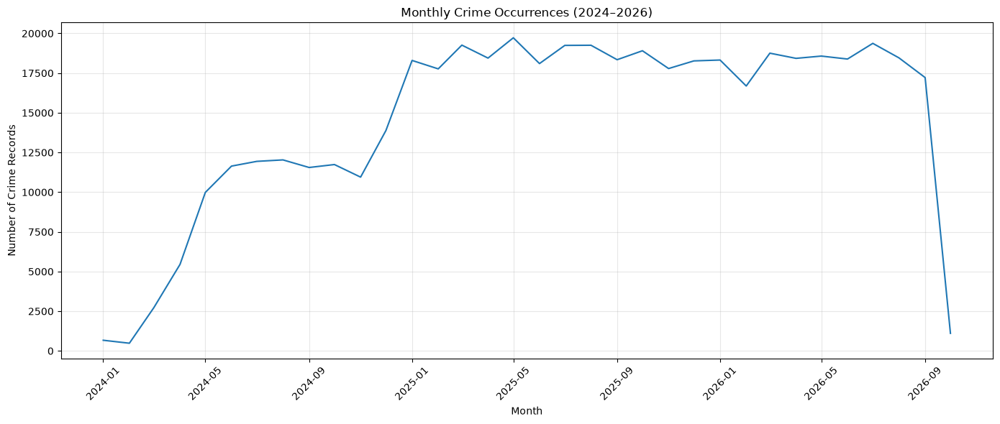

In [54]:
import matplotlib.pyplot as plt

# Extract year-month and count crimes
monthly_crimes = (
    df_clean
    .set_index("Date OCC")
    .resample("MS")
    .size()
)

# Plot monthly crime occurrences
plt.figure(figsize=(14, 6))
plt.plot(monthly_crimes.index, monthly_crimes.values)
plt.title("Monthly Crime Occurrences (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Number of Crime Records")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
# Check monthly record counts and date coverage
monthly_check = df_clean.groupby(
    df_clean["Date OCC"].dt.to_period("M")
).agg(
    Total_Records=("CaseNo", "count"),
    Unique_Days=("Date OCC", lambda x: x.dt.date.nunique()),
    First_Date=("Date OCC", "min"),
    Last_Date=("Date OCC", "max")
)

print(monthly_check.to_string())

          Total_Records  Unique_Days First_Date           Last_Date
Date OCC                                                           
2024-01             671           31 2024-01-01 2024-01-31 23:25:00
2024-02             484           29 2024-02-01 2024-02-29 21:10:00
2024-03            2727           31 2024-03-01 2024-03-31 23:50:00
2024-04            5450           30 2024-04-01 2024-04-30 23:25:00
2024-05            9984           31 2024-05-01 2024-05-31 23:50:00
2024-06           11641           30 2024-06-01 2024-06-30 23:59:00
2024-07           11940           31 2024-07-01 2024-07-31 23:40:00
2024-08           12032           31 2024-08-01 2024-08-31 23:55:00
2024-09           11554           30 2024-09-01 2024-09-30 23:40:00
2024-10           11739           31 2024-10-01 2024-10-31 23:55:00
2024-11           10947           30 2024-11-01 2024-11-30 23:59:00
2024-12           13882           31 2024-12-01 2024-12-31 23:59:00
2025-01           18297           31 2025-01-01 

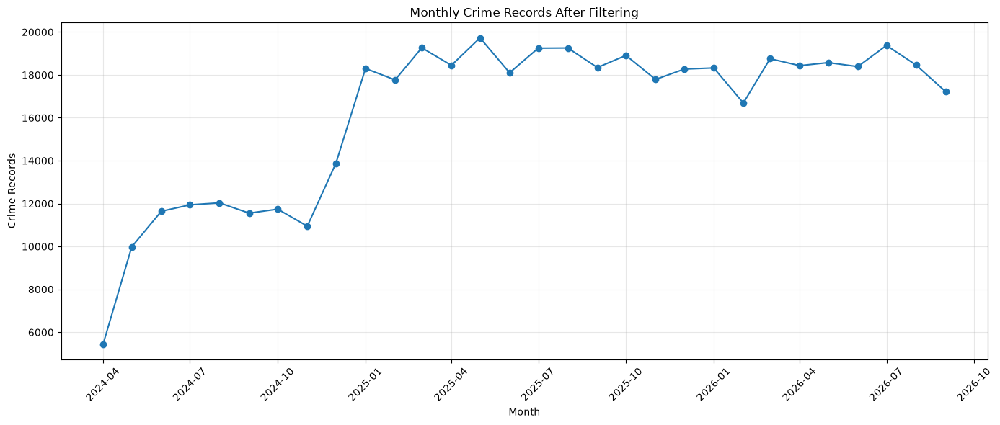

Months retained: 30
Records retained: 486770

Monthly counts:
Date OCC
2024-04-01     5450
2024-05-01     9984
2024-06-01    11641
2024-07-01    11940
2024-08-01    12032
2024-09-01    11554
2024-10-01    11739
2024-11-01    10947
2024-12-01    13882
2025-01-01    18297
2025-02-01    17766
2025-03-01    19262
2025-04-01    18445
2025-05-01    19724
2025-06-01    18100
2025-07-01    19245
2025-08-01    19254
2025-09-01    18343
2025-10-01    18907
2025-11-01    17787
2025-12-01    18269
2026-01-01    18323
2026-02-01    16687
2026-03-01    18755
2026-04-01    18429
2026-05-01    18572
2026-06-01    18386
2026-07-01    19373
2026-08-01    18459
2026-09-01    17218
Freq: MS, dtype: int64


In [56]:
import pandas as pd
import matplotlib.pyplot as plt

# Count records per month
monthly_counts = (
    df_clean.set_index("Date OCC")
    .resample("MS")
    .size()
)

# Keep months with at least 5,000 records
valid_months = monthly_counts[monthly_counts >= 5000].index

# Filter the dataset to those months
df_filtered = df_clean[
    df_clean["Date OCC"].dt.to_period("M").isin(
        valid_months.to_period("M")
    )
].copy()

# Recalculate monthly crime counts
monthly_crimes = (
    df_filtered.set_index("Date OCC")
    .resample("MS")
    .size()
)

# Keep only months that passed the threshold
monthly_crimes = monthly_crimes[monthly_crimes >= 5000]

# Plot
plt.figure(figsize=(14, 6))
plt.plot(monthly_crimes.index, monthly_crimes.values, marker="o")

plt.title("Monthly Crime Records After Filtering")
plt.xlabel("Month")
plt.ylabel("Crime Records")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Months retained:", len(monthly_crimes))
print("Records retained:", len(df_filtered))
print("\nMonthly counts:")
print(monthly_crimes)

MONTHLY CRIME DATA

Months retained: 30
Records represented: 486,770
First month: 2024-04
Last month: 2026-09

Monthly crime counts:
Date OCC
2024-04-01     5450
2024-05-01     9984
2024-06-01    11641
2024-07-01    11940
2024-08-01    12032
2024-09-01    11554
2024-10-01    11739
2024-11-01    10947
2024-12-01    13882
2025-01-01    18297
2025-02-01    17766
2025-03-01    19262
2025-04-01    18445
2025-05-01    19724
2025-06-01    18100
2025-07-01    19245
2025-08-01    19254
2025-09-01    18343
2025-10-01    18907
2025-11-01    17787
2025-12-01    18269
2026-01-01    18323
2026-02-01    16687
2026-03-01    18755
2026-04-01    18429
2026-05-01    18572
2026-06-01    18386
2026-07-01    19373
2026-08-01    18459
2026-09-01    17218
Freq: MS, dtype: int64

MODEL EVALUATION

Training months: 27
Testing months: 3

Mean Absolute Error (MAE): 749.68

Actual vs Predicted:
          Actual Crimes  Predicted Crimes
Date OCC                                 
2026-07           19373             1

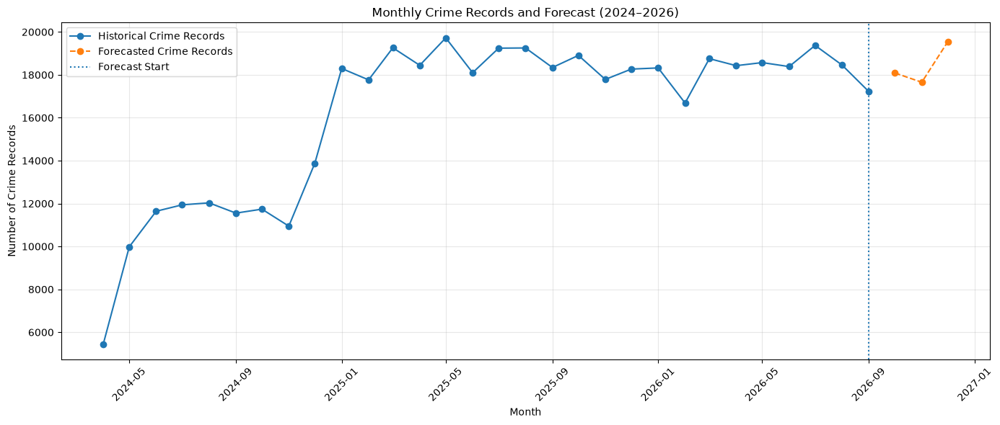

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error
import warnings

warnings.filterwarnings("ignore")

# ==========================================
# 1. PREPARE MONTHLY CRIME COUNTS
# ==========================================

# Use the cleaned dataset
df = pd.read_csv("outputs/crime_data_categorized.csv")

df["Date OCC"] = pd.to_datetime(df["Date OCC"], errors="coerce")

# Keep records from January 2024 onward
df = df[df["Date OCC"] >= "2024-01-01"].copy()

# Count crimes per month
monthly_counts = (
    df.set_index("Date OCC")
      .resample("MS")
      .size()
)

# Retain only months with at least 5,000 records
monthly_counts = monthly_counts[monthly_counts >= 5000]

# Ensure monthly frequency for the forecasting model
monthly_counts = monthly_counts.asfreq("MS")

# Remove any missing months, if present
monthly_counts = monthly_counts.dropna()

print("=" * 55)
print("MONTHLY CRIME DATA")
print("=" * 55)

print(f"\nMonths retained: {len(monthly_counts)}")
print(f"Records represented: {monthly_counts.sum():,}")
print(f"First month: {monthly_counts.index.min():%Y-%m}")
print(f"Last month: {monthly_counts.index.max():%Y-%m}")

print("\nMonthly crime counts:")
print(monthly_counts)


# ==========================================
# 2. TRAINING AND TESTING
# ==========================================

# Hold out the last 3 observed months for evaluation.
# Forecasting performance will be evaluated on these months.
train = monthly_counts.iloc[:-3]
test = monthly_counts.iloc[-3:]

print("\n" + "=" * 55)
print("MODEL EVALUATION")
print("=" * 55)

print(f"\nTraining months: {len(train)}")
print(f"Testing months: {len(test)}")

# Holt-Winters model with yearly seasonality
model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

fitted_model = model.fit(optimized=True)

# Predict the held-out months
test_predictions = fitted_model.forecast(len(test))

# Calculate evaluation metric
mae = mean_absolute_error(test, test_predictions)

print(f"\nMean Absolute Error (MAE): {mae:.2f}")

evaluation = pd.DataFrame({
    "Actual Crimes": test.values,
    "Predicted Crimes": test_predictions.values.round().astype(int)
}, index=test.index)

evaluation.index = evaluation.index.strftime("%Y-%m")

print("\nActual vs Predicted:")
print(evaluation)


# ==========================================
# 3. TRAIN FINAL MODEL ON ALL RETAINED DATA
# ==========================================

final_model = ExponentialSmoothing(
    monthly_counts,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

final_fitted_model = final_model.fit(optimized=True)

# Forecast October, November and December 2026
forecast = final_fitted_model.forecast(3)

# Display forecast
forecast_df = pd.DataFrame({
    "Month": forecast.index.strftime("%Y-%m"),
    "Predicted Crime Records": forecast.round().astype(int).values
})

print("\n" + "=" * 55)
print("CRIME FORECAST: OCTOBER–DECEMBER 2026")
print("=" * 55)

print(forecast_df.to_string(index=False))


# ==========================================
# 4. VISUALIZE HISTORICAL DATA AND FORECAST
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_counts.index,
    monthly_counts.values,
    marker="o",
    label="Historical Crime Records"
)

plt.plot(
    forecast.index,
    forecast.values,
    marker="o",
    linestyle="--",
    label="Forecasted Crime Records"
)

plt.axvline(
    monthly_counts.index.max(),
    linestyle=":",
    label="Forecast Start"
)

plt.title("Monthly Crime Records and Forecast (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Number of Crime Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Training period: 2024-04 to 2026-06
Testing period: 2026-07 to 2026-09

Actual vs Predicted:
            Actual  Holt-Winters  Seasonal Naive
Month                                           
2026-07-01   19373         19121           19245
2026-08-01   18459         19185           19254
2026-09-01   17218         18489           18343

MODEL PERFORMANCE COMPARISON
         Model        MAE
Seasonal Naive 682.666667
  Holt-Winters 749.680212

Winner: Seasonal Naive


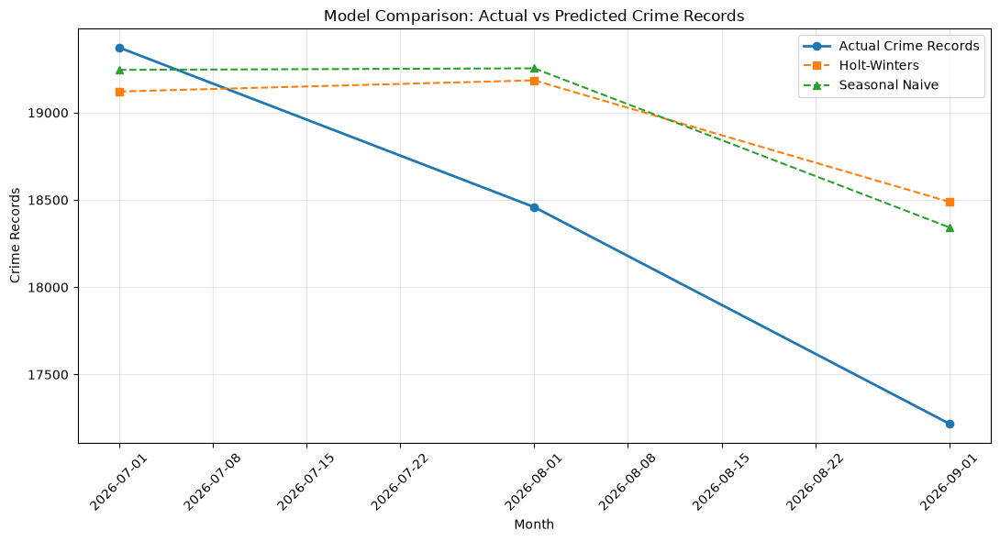

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# ==========================================
# 1. PREPARE DATA
# ==========================================

# Reuse monthly_counts from the previous cell
data = monthly_counts.copy().asfreq("MS")

# Last 3 months for testing
train = data.iloc[:-3]
test = data.iloc[-3:]

print("Training period:", train.index.min().strftime("%Y-%m"),
      "to", train.index.max().strftime("%Y-%m"))
print("Testing period:", test.index.min().strftime("%Y-%m"),
      "to", test.index.max().strftime("%Y-%m"))


# ==========================================
# 2. HOLT-WINTERS MODEL
# ==========================================

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hw_fitted = hw_model.fit(optimized=True)
hw_predictions = hw_fitted.forecast(3)


# ==========================================
# 3. SEASONAL NAIVE MODEL
# ==========================================

# Predict each test month using the same month last year
seasonal_naive_predictions = train.iloc[-12:-9].copy()

# Align predictions with the test months
seasonal_naive_predictions.index = test.index


# ==========================================
# 4. COMPARE PREDICTIONS
# ==========================================

results = pd.DataFrame({
    "Actual": test.values,
    "Holt-Winters": hw_predictions.values,
    "Seasonal Naive": seasonal_naive_predictions.values
}, index=test.index)

results.index.name = "Month"

results = results.round(0).astype(int)

print("\nActual vs Predicted:")
print(results)

# Calculate MAE
hw_mae = mean_absolute_error(
    test, hw_predictions
)

naive_mae = mean_absolute_error(
    test, seasonal_naive_predictions
)

comparison = pd.DataFrame({
    "Model": ["Holt-Winters", "Seasonal Naive"],
    "MAE": [hw_mae, naive_mae]
}).sort_values("MAE")

print("\n" + "=" * 45)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 45)

print(comparison.to_string(index=False))

if hw_mae < naive_mae:
    print("\nWinner: Holt-Winters")
else:
    print("\nWinner: Seasonal Naive")

# ==========================================
# 5. VISUALIZE THE COMPARISON
# ==========================================

plt.figure(figsize=(11, 6))

plt.plot(
    test.index, test.values,
    marker="o", linewidth=2,
    label="Actual Crime Records"
)

plt.plot(
    test.index, hw_predictions.values,
    marker="s", linestyle="--",
    label="Holt-Winters"
)

plt.plot(
    test.index, seasonal_naive_predictions.values,
    marker="^", linestyle="--",
    label="Seasonal Naive"
)

plt.title("Model Comparison: Actual vs Predicted Crime Records")
plt.xlabel("Month")
plt.ylabel("Crime Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

MONTHLY CRIME DATA
Months retained: 30
Records represented: 486,770
First month: 2024-04
Last month: 2026-09

Training period: 2024-04 to 2026-06
Testing period: 2026-07 to 2026-09

ACTUAL VS PREDICTED
            Actual  Holt-Winters  Seasonal Naive
2026-07-01   19373         19121           19245
2026-08-01   18459         19185           19254
2026-09-01   17218         18489           18343

MODEL PERFORMANCE COMPARISON
Seasonal Naive    682.67
Holt-Winters      749.68
dtype: float64

Best model by MAE: Seasonal Naive


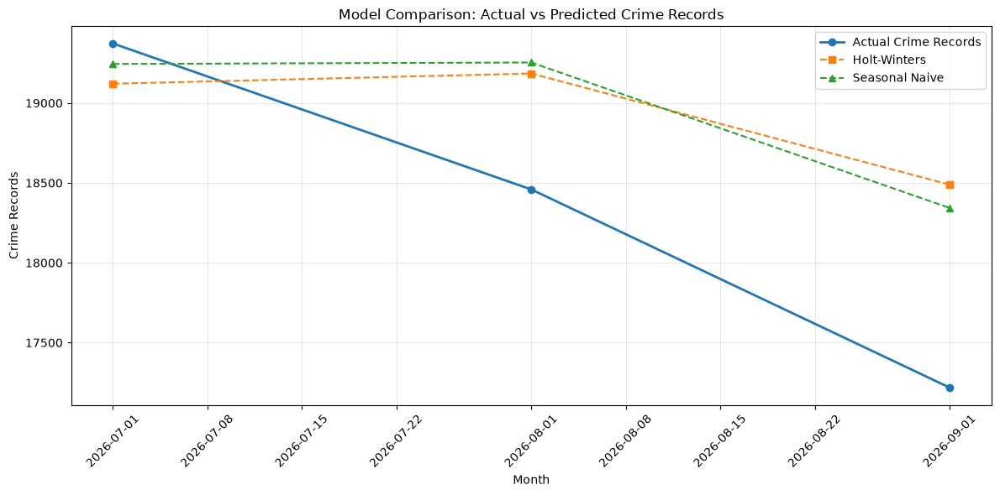


CRIME FORECAST: OCTOBER-DECEMBER 2026
  Month  Predicted Crime Records
2026-10                    18907
2026-11                    17787
2026-12                    18269


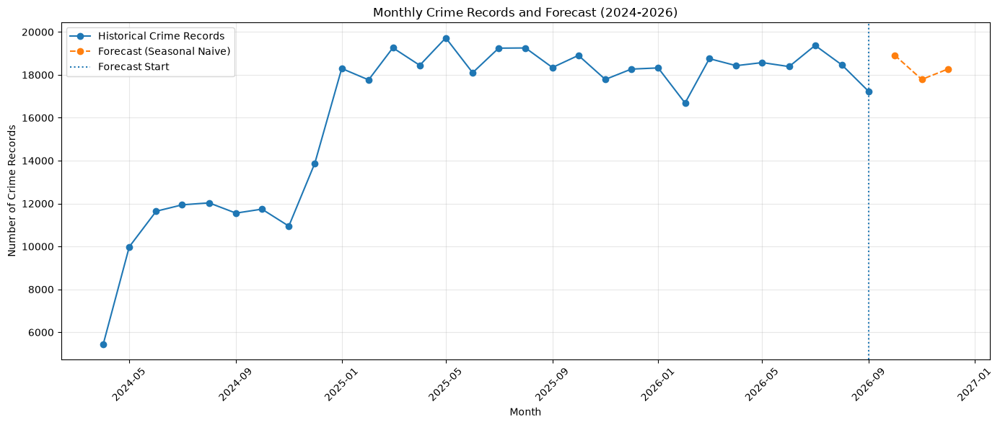

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")

# ============================================================
# 1. PREPARE MONTHLY CRIME DATA
# ============================================================

df = pd.read_csv("outputs/crime_data_categorized.csv")
df["Date OCC"] = pd.to_datetime(df["Date OCC"], errors="coerce")

df["Date OCC"] = pd.to_datetime(df["Date OCC"], errors="coerce")
df = df.dropna(subset=["Date OCC"])

# Retain dates from January 2024 onwards
df = df[df["Date OCC"] >= "2024-01-01"].copy()

# Count crimes per month
monthly_crimes = (
    df.set_index("Date OCC")
      .resample("MS")
      .size()
)

# Retain months containing more than 5,000 records
monthly_crimes = monthly_crimes[monthly_crimes > 5000]

# Ensure a continuous monthly time series
monthly_crimes = monthly_crimes.asfreq("MS")

# Remove months that do not meet the threshold
monthly_crimes = monthly_crimes.dropna()

print("=" * 60)
print("MONTHLY CRIME DATA")
print("=" * 60)

print(f"Months retained: {len(monthly_crimes)}")
print(f"Records represented: {int(monthly_crimes.sum()):,}")
print(f"First month: {monthly_crimes.index.min():%Y-%m}")
print(f"Last month: {monthly_crimes.index.max():%Y-%m}")


# ============================================================
# 2. TRAIN-TEST SPLIT
# ============================================================

# Last 3 observed months are used for testing
train = monthly_crimes.iloc[:-3]
test = monthly_crimes.iloc[-3:]

print("\nTraining period:",
      f"{train.index.min():%Y-%m} to {train.index.max():%Y-%m}")

print("Testing period:",
      f"{test.index.min():%Y-%m} to {test.index.max():%Y-%m}")


# ============================================================
# 3. SEASONAL NAIVE MODEL
# ============================================================

# Forecast each test month using the corresponding month
# from the previous year when available.
# For a 3-month test window, seasonal naive uses a 12-month lag.
# This requires sufficient historical observations.

if len(train) < 12:
    raise ValueError("At least 12 training months are required.")

seasonal_naive_predictions = pd.Series(
    [
        monthly_crimes.iloc[len(train) + i - 12]
        for i in range(len(test))
    ],
    index=test.index,
    dtype=float
)

seasonal_naive_mae = mean_absolute_error(
    test,
    seasonal_naive_predictions
)


# ============================================================
# 4. HOLT-WINTERS MODEL
# ============================================================

hw_model = ExponentialSmoothing(
    train.astype(float),
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)

hw_predictions = hw_fit.forecast(len(test))

hw_mae = mean_absolute_error(
    test,
    hw_predictions
)


# ============================================================
# 5. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Actual": test,
    "Holt-Winters": hw_predictions,
    "Seasonal Naive": seasonal_naive_predictions
})

print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED")
print("=" * 60)

print(comparison.round(0).astype(int))

model_scores = pd.Series({
    "Holt-Winters": hw_mae,
    "Seasonal Naive": seasonal_naive_mae
}).sort_values()

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

print(model_scores.round(2))

best_model_name = model_scores.index[0]

print(f"\nBest model by MAE: {best_model_name}")


# ============================================================
# 6. PLOT MODEL COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=2,
    label="Actual Crime Records"
)

plt.plot(
    test.index,
    hw_predictions.values,
    marker="s",
    linestyle="--",
    label="Holt-Winters"
)

plt.plot(
    test.index,
    seasonal_naive_predictions.values,
    marker="^",
    linestyle="--",
    label="Seasonal Naive"
)

plt.title("Model Comparison: Actual vs Predicted Crime Records")
plt.xlabel("Month")
plt.ylabel("Crime Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 7. REFIT BEST MODEL ON ALL AVAILABLE DATA
# ============================================================

if best_model_name == "Holt-Winters":

    final_model = ExponentialSmoothing(
        monthly_crimes.astype(float),
        trend="add",
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    )

    final_fit = final_model.fit(optimized=True)

    future_predictions = final_fit.forecast(3)

else:

    # Seasonal naive forecast: use the corresponding months
    # from the previous year.
    future_predictions = monthly_crimes.iloc[-12:-9].copy()

    future_predictions.index = pd.date_range(
        start=monthly_crimes.index[-1] + pd.offsets.MonthBegin(1),
        periods=3,
        freq="MS"
    )


# ============================================================
# 8. FORECAST OCTOBER-DECEMBER 2026
# ============================================================

forecast_months = pd.date_range(
    start="2026-10-01",
    periods=3,
    freq="MS"
)

# Ensure the forecasts correspond to October, November, December.
# The data must end in September 2026 for this forecast setup.
if monthly_crimes.index.max() != pd.Timestamp("2026-09-01"):
    print(
        "\nWARNING: Your last retained month is "
        f"{monthly_crimes.index.max():%Y-%m}, not September 2026."
    )

forecast_table = pd.DataFrame({
    "Month": forecast_months.strftime("%Y-%m"),
    "Predicted Crime Records": np.maximum(
        0,
        np.round(np.asarray(future_predictions))
    ).astype(int)
})

print("\n" + "=" * 60)
print("CRIME FORECAST: OCTOBER-DECEMBER 2026")
print("=" * 60)

print(forecast_table.to_string(index=False))


# ============================================================
# 9. PLOT HISTORICAL DATA AND FORECAST
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_crimes.index,
    monthly_crimes.values,
    marker="o",
    label="Historical Crime Records"
)

plt.plot(
    forecast_months,
    forecast_table["Predicted Crime Records"],
    marker="o",
    linestyle="--",
    label=f"Forecast ({best_model_name})"
)

plt.axvline(
    monthly_crimes.index[-1],
    linestyle=":",
    label="Forecast Start"
)

plt.title("Monthly Crime Records and Forecast (2024-2026)")
plt.xlabel("Month")
plt.ylabel("Number of Crime Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

CRIME CATEGORY DISTRIBUTION
Crime Category
Assault & Battery                 102747
Theft & Larceny                    64195
Vehicle Theft                      58572
Vandalism & Property Damage        54018
Burglary                           49711
Other Crimes                       40784
Fraud & Identity Theft             20520
Robbery                            17181
Threats & Harassment               14874
Drug-Related Offenses              13934
Weapons Offenses                   13629
Trespassing                         9817
Traffic & DUI Offenses              9648
Domestic Violence                   6687
Sexual Offenses                     6526
Homicide                            1773
Arson                               1188
Kidnapping & Human Trafficking       966
Name: count, dtype: int64


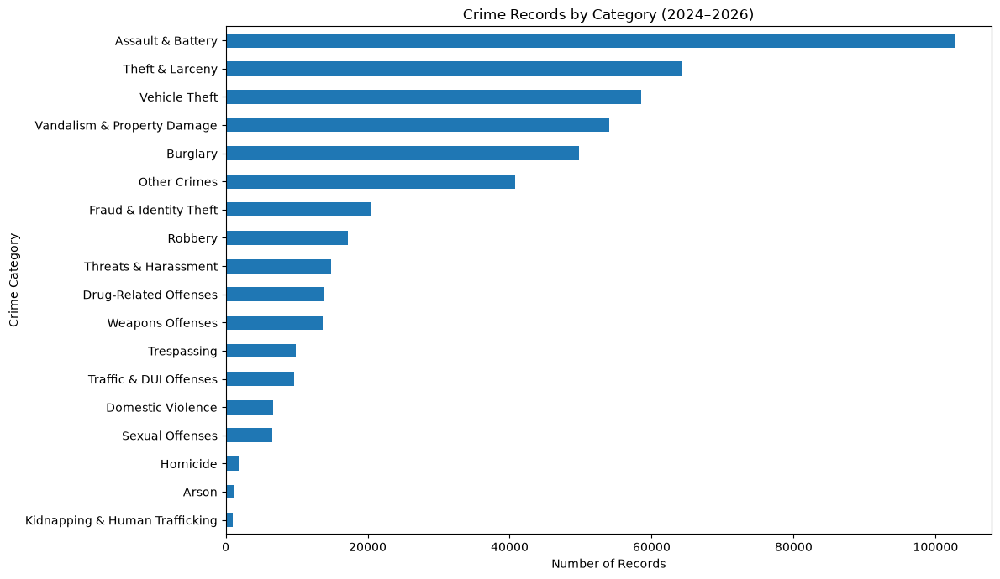

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("outputs/crime_data_categorized.csv")

df["Date OCC"] = pd.to_datetime(df["Date OCC"], errors="coerce")

# Keep records from January 2024 onwards
df = df[df["Date OCC"] >= "2024-01-01"].copy()

# Keep months with more than 5,000 records
df["Month"] = df["Date OCC"].dt.to_period("M")

monthly_totals = df.groupby("Month").size()
valid_months = monthly_totals[monthly_totals > 5000].index

df = df[df["Month"].isin(valid_months)]

# =====================================================
# CRIME CATEGORY DISTRIBUTION
# =====================================================

category_counts = df["Crime Category"].value_counts()

print("CRIME CATEGORY DISTRIBUTION")
print("=" * 45)
print(category_counts)

plt.figure(figsize=(12, 7))
category_counts.sort_values().plot(kind="barh")

plt.title("Crime Records by Category (2024–2026)")
plt.xlabel("Number of Records")
plt.ylabel("Crime Category")
plt.tight_layout()
plt.show()

In [61]:
# Crime Category Percentage Distribution

category_counts = df_filtered["Crime Category"].value_counts()

category_summary = pd.DataFrame({
    "Total Records": category_counts,
    "Percentage (%)": (
        category_counts / category_counts.sum() * 100
    ).round(2)
})

print("=" * 55)
print("CRIME CATEGORY DISTRIBUTION")
print("=" * 55)
print(category_summary.to_string())

print("\nTotal categories:", len(category_counts))
print("Total records:", category_counts.sum())

CRIME CATEGORY DISTRIBUTION
                                Total Records  Percentage (%)
Crime Category                                               
Assault & Battery                      102747           21.11
Theft & Larceny                         64195           13.19
Vehicle Theft                           58572           12.03
Vandalism & Property Damage             54018           11.10
Burglary                                49711           10.21
Other Crimes                            40784            8.38
Fraud & Identity Theft                  20520            4.22
Robbery                                 17181            3.53
Threats & Harassment                    14874            3.06
Drug-Related Offenses                   13934            2.86
Weapons Offenses                        13629            2.80
Trespassing                              9817            2.02
Traffic & DUI Offenses                   9648            1.98
Domestic Violence                        6

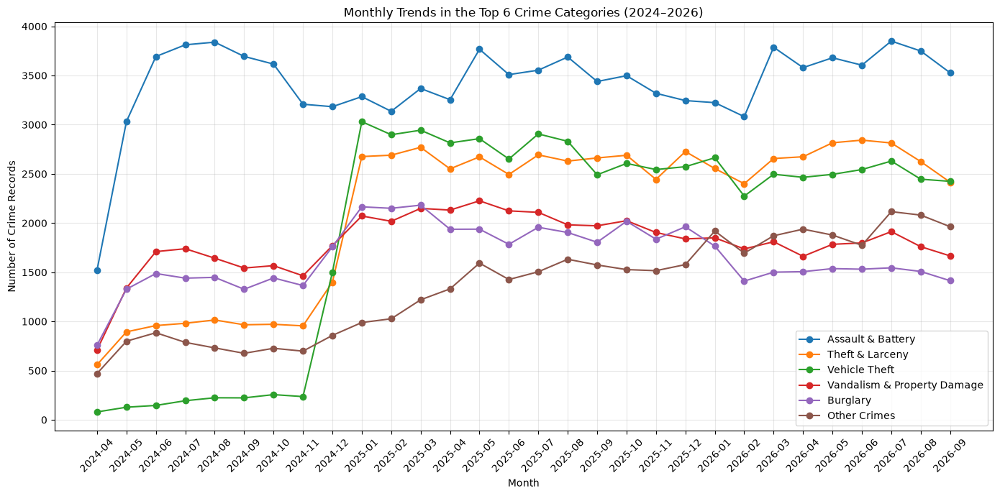

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare monthly crime counts by category
df_filtered["Date OCC"] = pd.to_datetime(df_filtered["Date OCC"])

monthly_category = (
    df_filtered
    .assign(Month=df_filtered["Date OCC"].dt.to_period("M"))
    .groupby(["Month", "Crime Category"])
    .size()
    .unstack(fill_value=0)
)

# Plot trends for the 6 most common categories
top_categories = (
    df_filtered["Crime Category"]
    .value_counts()
    .head(6)
    .index
)

plt.figure(figsize=(14, 7))

for category in top_categories:
    plt.plot(
        monthly_category.index.astype(str),
        monthly_category[category],
        marker="o",
        label=category
    )

plt.title("Monthly Trends in the Top 6 Crime Categories (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Number of Crime Records")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
# Check monthly record counts and category coverage

monthly_check = (
    df_filtered
    .assign(Month=df_filtered["Date OCC"].dt.to_period("M"))
    .groupby("Month")
    .agg(
        Total_Records=("Crime Category", "size"),
        Unique_Categories=("Crime Category", "nunique")
    )
)

print("MONTHLY DATA COVERAGE")
print(monthly_check.to_string())

MONTHLY DATA COVERAGE
         Total_Records  Unique_Categories
Month                                    
2024-04           5450                 18
2024-05           9984                 18
2024-06          11641                 18
2024-07          11940                 18
2024-08          12032                 18
2024-09          11554                 18
2024-10          11739                 18
2024-11          10947                 18
2024-12          13882                 18
2025-01          18297                 18
2025-02          17766                 18
2025-03          19262                 18
2025-04          18445                 18
2025-05          19724                 18
2025-06          18100                 18
2025-07          19245                 18
2025-08          19254                 18
2025-09          18343                 18
2025-10          18907                 18
2025-11          17787                 18
2025-12          18269                 18
2026-01     

CRIME RECORDS BY POLICE AREA
AREA NAME
Central                 39982
77th Street             27400
Southwest               27292
Olympic                 27025
Rampart                 26919
N Hollywood             26144
Hollywood               26125
Pacific                 24578
Newton                  23712
Southeast               22351
Van Nuys                21928
Wilshire                21536
Northeast               21068
West Valley             21009
Topanga                 20656
Mission                 20048
Devonshire              19722
Harbor                  18516
Hollenbeck              18104
West LA                 17832
Foothill                14823


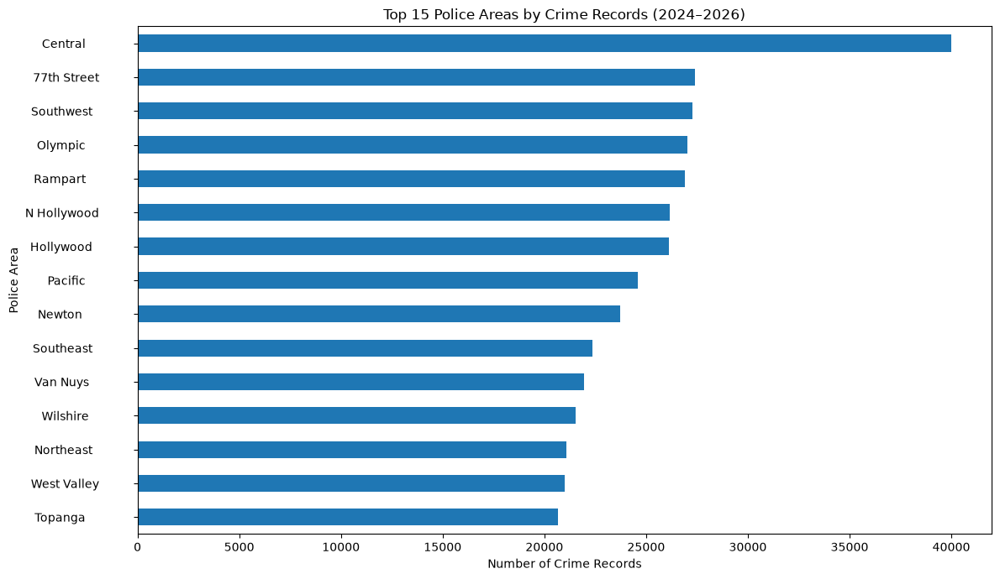

In [64]:
import matplotlib.pyplot as plt

# Crime records by police area
area_counts = (
    df_filtered["AREA NAME"]
    .value_counts()
    .sort_values(ascending=False)
)

print("CRIME RECORDS BY POLICE AREA")
print("=" * 50)
print(area_counts.to_string())

# Visualize the top 15 areas
plt.figure(figsize=(12, 7))

area_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Police Areas by Crime Records (2024–2026)")
plt.xlabel("Number of Crime Records")
plt.ylabel("Police Area")
plt.tight_layout()
plt.show()

In [65]:
# Inspect geographic location fields

print("LOCATION examples:")
print(df_filtered["LOCATION"].dropna().head(10).to_string(index=False))

print("\nUnique location count:")
print(df_filtered["LOCATION"].nunique())

print("\nCoordinate coverage:")
print("Latitude missing:", df_filtered["LAT"].isna().sum())
print("Longitude missing:", df_filtered["LON"].isna().sum())

LOCATION examples:
       700 S Figueroa St
           Saticoy & Oso
                    1321
W 6th St & S Catalina St
          3000 W 67th St
        11800 Valerio St
  800 S Saint Andrews Pl
        18500 Saticoy St
       7000 Lanewood Ave
         20500 Califa St

Unique location count:
85718

Coordinate coverage:
Latitude missing: 124
Longitude missing: 124


Available coordinate columns: ['Gang-related Crime', 'Transit-related Crime', 'LAT', 'LON']
CRIME DISTRIBUTION BY MAJOR LOS ANGELES AREA


,LA Area,Crime Records,Percentage (%)
0,Other / Outside Defined Areas,241413,49.61
1,South LA,62891,12.92
2,Downtown LA,47305,9.72
3,Hollywood,29292,6.02
4,Van Nuys,22732,4.67
5,North Hollywood,17185,3.53
6,Koreatown,16260,3.34
7,Venice,9314,1.91
8,Boyle Heights,9013,1.85
9,Sherman Oaks,7202,1.48


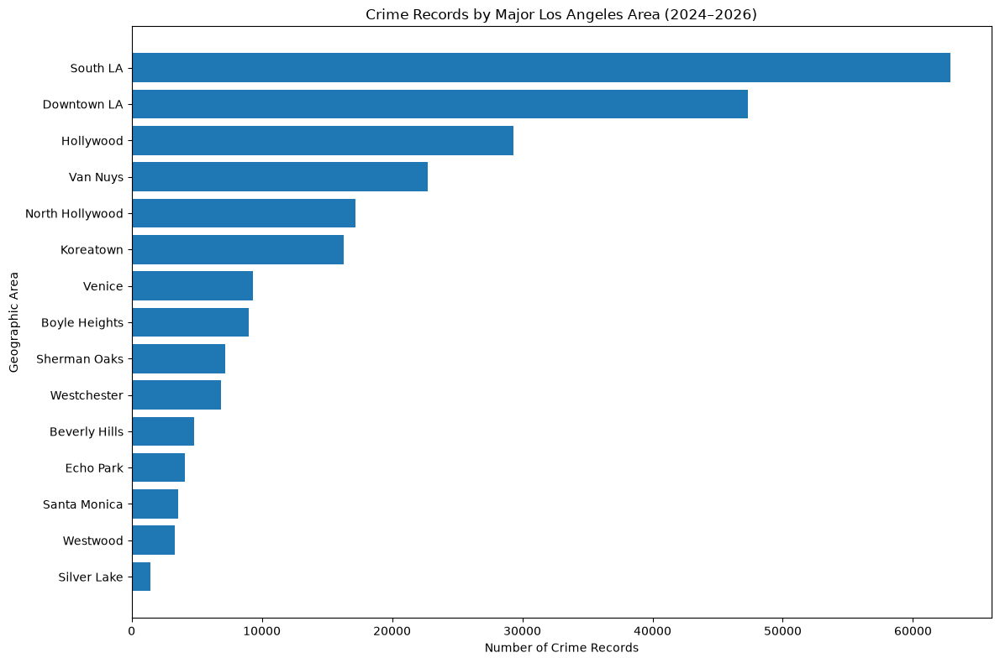

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# MAJOR LOS ANGELES AREAS
# ==========================================

# Work with the existing dataset
location_df = df.copy()

# Check coordinate columns
print("Available coordinate columns:",
      [col for col in location_df.columns
       if 'lat' in col.lower() or 'lon' in col.lower()])

# Identify latitude and longitude columns
lat_col = next(
    (col for col in location_df.columns if col.lower() in ['latitude', 'lat']),
    None
)

lon_col = next(
    (col for col in location_df.columns
     if col.lower() in ['longitude', 'lon', 'long']),
    None
)

if lat_col is None or lon_col is None:
    raise ValueError(
        "Latitude/longitude columns not found. "
        "Check the available coordinate columns printed above."
    )

# Convert coordinates to numeric
location_df[lat_col] = pd.to_numeric(
    location_df[lat_col], errors='coerce'
)
location_df[lon_col] = pd.to_numeric(
    location_df[lon_col], errors='coerce'
)

# Remove invalid coordinates
location_df = location_df.dropna(subset=[lat_col, lon_col])

# Approximate geographic boundaries for major LA areas.
# These are rough bounding boxes, not official neighborhood boundaries.
la_areas = {
    "Downtown LA":       (34.035, 34.070, -118.270, -118.220),
    "Hollywood":         (34.075, 34.115, -118.360, -118.300),
    "North Hollywood":   (34.150, 34.200, -118.410, -118.350),
    "Beverly Hills":     (34.055, 34.095, -118.420, -118.370),
    "Santa Monica":      (34.000, 34.050, -118.520, -118.450),
    "Venice":            (33.970, 34.020, -118.480, -118.420),
    "Westwood":          (34.050, 34.080, -118.460, -118.410),
    "Koreatown":         (34.055, 34.075, -118.315, -118.280),
    "Echo Park":         (34.070, 34.100, -118.270, -118.240),
    "Silver Lake":       (34.075, 34.110, -118.270, -118.230),
    "South LA":          (33.930, 34.020, -118.320, -118.240),
    "Van Nuys":          (34.180, 34.230, -118.490, -118.420),
    "Westchester":       (33.930, 33.970, -118.430, -118.370),
    "Boyle Heights":     (34.020, 34.060, -118.220, -118.180),
    "Sherman Oaks":      (34.130, 34.170, -118.480, -118.420),
}

# Assign each record to a geographic area
def assign_la_area(row):
    lat = row[lat_col]
    lon = row[lon_col]

    for area, (lat_min, lat_max, lon_min, lon_max) in la_areas.items():
        if lat_min <= lat <= lat_max and lon_min <= lon <= lon_max:
            return area

    return "Other / Outside Defined Areas"

location_df["LA Area"] = location_df.apply(
    assign_la_area, axis=1
)

# ==========================================
# CRIME DISTRIBUTION BY MAJOR LA AREA
# ==========================================

area_counts = (
    location_df["LA Area"]
    .value_counts()
    .rename_axis("LA Area")
    .reset_index(name="Crime Records")
)

area_counts["Percentage (%)"] = (
    area_counts["Crime Records"]
    / area_counts["Crime Records"].sum()
    * 100
).round(2)

print("=" * 60)
print("CRIME DISTRIBUTION BY MAJOR LOS ANGELES AREA")
print("=" * 60)

display(area_counts)

# ==========================================
# VISUALIZATION
# ==========================================

plot_data = area_counts[
    area_counts["LA Area"] != "Other / Outside Defined Areas"
].sort_values("Crime Records", ascending=True)

plt.figure(figsize=(12, 8))

plt.barh(
    plot_data["LA Area"],
    plot_data["Crime Records"]
)

plt.title("Crime Records by Major Los Angeles Area (2024–2026)")
plt.xlabel("Number of Crime Records")
plt.ylabel("Geographic Area")
plt.tight_layout()
plt.show()

In [67]:
import geopandas as gpd
import pandas as pd
import requests
import matplotlib.pyplot as plt

# Official City of Los Angeles boundary service
url = (
    "https://maps.lacity.org/arcgis/rest/services/"
    "Mapping/Boundaries/MapServer/5/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

geojson = response.json()

if "features" not in geojson:
    raise ValueError(f"Boundary download failed: {geojson}")

neighborhoods = gpd.GeoDataFrame.from_features(
    geojson["features"],
    crs="EPSG:4326"
)

print("Total boundary areas:", len(neighborhoods))
print("Columns:", neighborhoods.columns.tolist())

display(neighborhoods[["NAME", "geometry"]].head(10))

Total boundary areas: 99
Columns: ['geometry', 'OBJECTID', 'NAME', 'WADDRESS', 'DWEBSITE', 'DEMAIL', 'DPHONE', 'NC_ID', 'CERTIFIED', 'SERVICE_RE', 'TOOLTIP', 'NLA_URL']


,NAME,geometry
0,ARLETA NC,"POLYGON ((-118.44305 34.26328, -118.44317 34.2..."
1,ARROYO SECO NC,"POLYGON ((-118.19567 34.08613, -118.19567 34.0..."
2,ARTS DISTRICT LITTLE TOKYO NC,"POLYGON ((-118.23151 34.05348, -118.23152 34.0..."
3,ATWATER VILLAGE NC,"POLYGON ((-118.25279 34.10833, -118.24958 34.1..."
4,BEL AIR-BEVERLY CREST NC,"POLYGON ((-118.36574 34.09948, -118.36573 34.0..."
5,BOYLE HEIGHTS NC,"POLYGON ((-118.22857 34.05305, -118.2286 34.05..."
6,CANOGA PARK NC,"POLYGON ((-118.60465 34.23484, -118.60452 34.2..."
7,CENTRAL ALAMEDA NC,"POLYGON ((-118.25645 33.99019, -118.25645 33.9..."
8,CENTRAL HOLLYWOOD NC,"POLYGON ((-118.32375 34.10165, -118.32376 34.1..."
9,CENTRAL SAN PEDRO NC,"POLYGON ((-118.28823 33.75426, -118.28851 33.7..."


In [68]:
# Ensure crime coordinates are numeric
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")

# Keep records with valid coordinates
crime_geo = df.dropna(subset=["LAT", "LON"]).copy()

# Convert crime records into geographic points
crimes_gdf = gpd.GeoDataFrame(
    crime_geo,
    geometry=gpd.points_from_xy(
        crime_geo["LON"],
        crime_geo["LAT"]
    ),
    crs="EPSG:4326"
)

# Keep only neighborhood names and geometries
neighborhoods_clean = neighborhoods[["NAME", "geometry"]].copy()

# Match each crime point to its actual LA neighborhood
crimes_mapped = gpd.sjoin(
    crimes_gdf,
    neighborhoods_clean,
    how="left",
    predicate="within"
)

# Check mapping results
mapped = crimes_mapped["NAME"].notna().sum()
unmapped = crimes_mapped["NAME"].isna().sum()

print("=" * 45)
print("GEOGRAPHIC MAPPING RESULTS")
print("=" * 45)
print(f"Total records with valid coordinates: {len(crimes_gdf):,}")
print(f"Records mapped to LA neighborhoods: {mapped:,}")
print(f"Records outside neighborhood boundaries: {unmapped:,}")
print(f"Mapping coverage: {mapped / len(crimes_gdf) * 100:.2f}%")

print("\nTop 15 neighborhoods by crime records:")

display(
    crimes_mapped["NAME"]
    .value_counts()
    .head(15)
    .rename_axis("Neighborhood")
    .reset_index(name="Crime Records")
)

GEOGRAPHIC MAPPING RESULTS
Total records with valid coordinates: 486,646
Records mapped to LA neighborhoods: 479,974
Records outside neighborhood boundaries: 11,297
Mapping coverage: 98.63%

Top 15 neighborhoods by crime records:


,Neighborhood,Crime Records
0,DOWNTOWN LOS ANGELES,36879
1,WILSHIRE CENTER - KOREATOWN NC,14883
2,EMPOWERMENT CONGRESS SOUTHEAST AREA NDC,13557
3,EMPOWERMENT CONGRESS NORTH AREA NC,11878
4,VAN NUYS NC,11862
5,BOYLE HEIGHTS NC,10553
6,WESTCHESTER/PLAYA NC,9763
7,MID CITY WEST CC,9152
8,NOHO NC,9132
9,WOODLAND HILLS-WARNER CENTER NC,8903


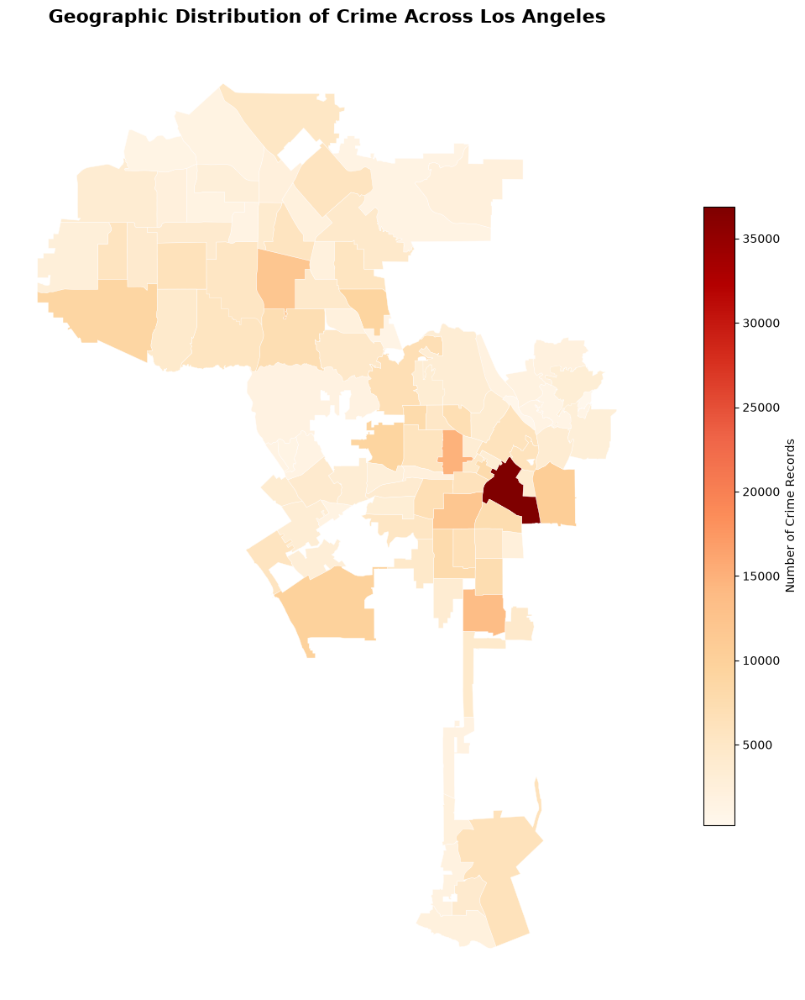

In [69]:
# Count crimes in each neighborhood
neighborhood_counts = (
    crimes_mapped["NAME"]
    .value_counts()
    .rename_axis("NAME")
    .reset_index(name="Crime Records")
)

# Merge crime counts with official neighborhood boundaries
crime_map = neighborhoods.merge(
    neighborhood_counts,
    on="NAME",
    how="left"
)

# Fill neighborhoods with no matched records
crime_map["Crime Records"] = crime_map["Crime Records"].fillna(0)

# Plot choropleth map
fig, ax = plt.subplots(figsize=(14, 12))

crime_map.plot(
    column="Crime Records",
    cmap="OrRd",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "No records"
    },
    legend_kwds={
        "label": "Number of Crime Records",
        "shrink": 0.65
    }
)

ax.set_title(
    "Geographic Distribution of Crime Across Los Angeles",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()
plt.tight_layout()
plt.show()



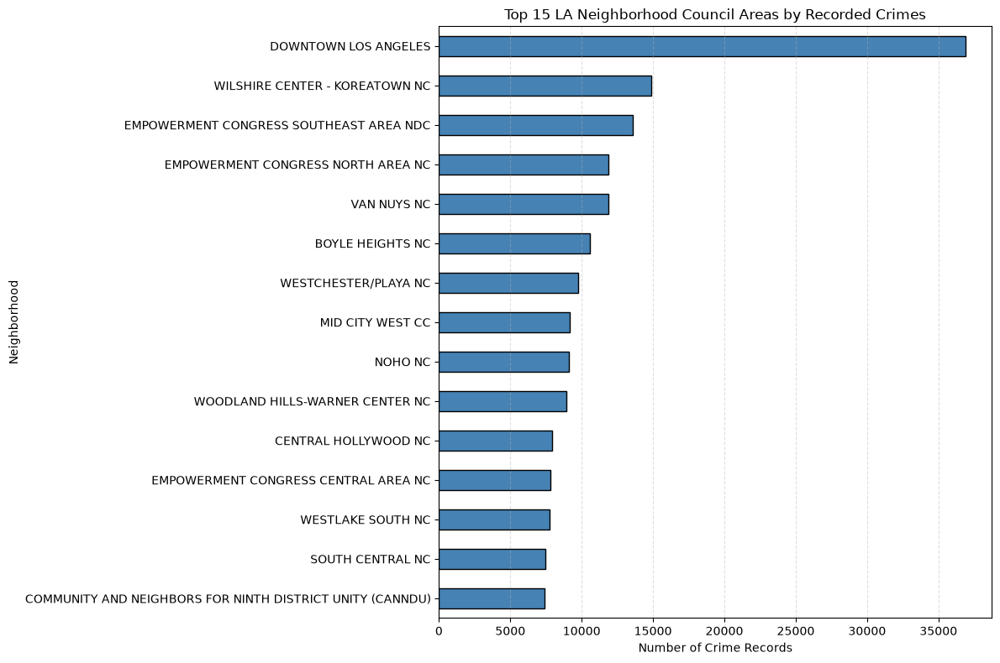

In [70]:
# Get the 15 neighborhoods with the most recorded crimes
top_neighborhoods = (
    crimes_mapped["NAME"]
    .value_counts()
    .head(15)
    .sort_values()
)

# Plot horizontal bar chart
plt.figure(figsize=(12, 8))

top_neighborhoods.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title("Top 15 LA Neighborhood Council Areas by Recorded Crimes")
plt.xlabel("Number of Crime Records")
plt.ylabel("Neighborhood")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [71]:
# Check which variables from the earlier major-area analysis still exist

possible_variables = [
    "major_areas",
    "area_bounds",
    "la_areas",
    "area_boxes",
    "area_mapping",
    "crime_by_area"
]

for var in possible_variables:
    if var in globals():
        print(f"✅ {var}: {type(globals()[var]).__name__}")

✅ la_areas: dict


In [72]:
# Inspect the major area definitions
for area, bounds in la_areas.items():
    print(f"{area}: {bounds}")

Downtown LA: (34.035, 34.07, -118.27, -118.22)
Hollywood: (34.075, 34.115, -118.36, -118.3)
North Hollywood: (34.15, 34.2, -118.41, -118.35)
Beverly Hills: (34.055, 34.095, -118.42, -118.37)
Santa Monica: (34.0, 34.05, -118.52, -118.45)
Venice: (33.97, 34.02, -118.48, -118.42)
Westwood: (34.05, 34.08, -118.46, -118.41)
Koreatown: (34.055, 34.075, -118.315, -118.28)
Echo Park: (34.07, 34.1, -118.27, -118.24)
Silver Lake: (34.075, 34.11, -118.27, -118.23)
South LA: (33.93, 34.02, -118.32, -118.24)
Van Nuys: (34.18, 34.23, -118.49, -118.42)
Westchester: (33.93, 33.97, -118.43, -118.37)
Boyle Heights: (34.02, 34.06, -118.22, -118.18)
Sherman Oaks: (34.13, 34.17, -118.48, -118.42)


In [73]:
# Identify invalid or suspicious geographic coordinates

invalid_zero = (
    (df["LAT"] == 0) |
    (df["LON"] == 0)
)

# Approximate bounds for the greater Los Angeles region
outside_la_bounds = (
    ~df["LAT"].between(33.0, 35.0) |
    ~df["LON"].between(-119.0, -117.0)
)

print("=" * 45)
print("COORDINATE QUALITY CHECK")
print("=" * 45)

print(f"Total records: {len(df):,}")
print(f"Records with zero coordinates: {invalid_zero.sum():,}")
print(f"Records outside broad LA bounds: {outside_la_bounds.sum():,}")
print(f"Records with plausible LA coordinates: {(~outside_la_bounds).sum():,}")

print("\nExamples of records with zero coordinates:")
display(
    df.loc[invalid_zero, ["LAT", "LON"]].head(10)
)

COORDINATE QUALITY CHECK
Total records: 486,770
Records with zero coordinates: 547
Records outside broad LA bounds: 671
Records with plausible LA coordinates: 486,099

Examples of records with zero coordinates:


,LAT,LON
2207,0.0,0.0
3457,0.0,0.0
6935,0.0,0.0
12405,0.0,0.0
18040,0.0,0.0
24426,0.0,0.0
27884,0.0,0.0
31967,0.0,0.0
51394,0.0,0.0
58634,0.0,0.0


In [74]:
# Create a separate dataset for geographic analysis
geo_df = df.copy()

# Remove missing coordinates
geo_df = geo_df.dropna(subset=["LAT", "LON"])

# Remove zero coordinates and records outside broad LA bounds
valid_coords = (
    (geo_df["LAT"] != 0) &
    (geo_df["LON"] != 0) &
    geo_df["LAT"].between(33.0, 35.0) &
    geo_df["LON"].between(-119.0, -117.0)
)

geo_df = geo_df.loc[valid_coords].copy()

print(f"Original records: {len(df):,}")
print(f"Records retained for geographic analysis: {len(geo_df):,}")
print(f"Records excluded: {len(df) - len(geo_df):,}")
print(f"Retention rate: {len(geo_df) / len(df) * 100:.2f}%")

Original records: 486,770
Records retained for geographic analysis: 486,099
Records excluded: 671
Retention rate: 99.86%


In [75]:
import importlib.util

libraries = ["geopandas", "shapely", "folium", "requests"]

for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed ✅' if installed else 'Not installed ❌'}")

geopandas: Installed ✅
shapely: Installed ✅
folium: Installed ✅
requests: Installed ✅


In [76]:
import folium
print("Folium version:", folium.__version__)

Folium version: 0.20.0


In [77]:
# Search existing official boundaries for our target areas

target_areas = [
    "Downtown LA",
    "Hollywood",
    "North Hollywood",
    "Beverly Hills",
    "Santa Monica",
    "Venice",
    "Westwood",
    "Koreatown",
    "Echo Park",
    "Silver Lake",
    "South LA",
    "Van Nuys",
    "Westchester",
    "Boyle Heights",
    "Sherman Oaks"
]

boundary_names = neighborhoods["NAME"].dropna().unique()

print("Existing boundary matches:\n")

for area in target_areas:
    matches = [
        name for name in boundary_names
        if area.lower() in name.lower()
    ]

    print(f"{area}:")
    print(f"  {matches[:10] if matches else 'No direct match'}")

Existing boundary matches:

Downtown LA:
  No direct match
Hollywood:
  ['CENTRAL HOLLYWOOD NC', 'EAST HOLLYWOOD NC', 'HOLLYWOOD HILLS WEST NC', 'HOLLYWOOD STUDIO DISTRICT NC', 'HOLLYWOOD UNITED NC', 'NORTH HOLLYWOOD NORTH EAST NC']
North Hollywood:
  ['NORTH HOLLYWOOD NORTH EAST NC']
Beverly Hills:
  No direct match
Santa Monica:
  No direct match
Venice:
  ['VENICE NC']
Westwood:
  ['WESTWOOD NC', 'NORTH WESTWOOD NC']
Koreatown:
  ['WILSHIRE CENTER - KOREATOWN NC']
Echo Park:
  ['ECHO PARK NC']
Silver Lake:
  ['SILVER LAKE NC']
South LA:
  No direct match
Van Nuys:
  ['VAN NUYS NC']
Westchester:
  ['WESTCHESTER/PLAYA NC']
Boyle Heights:
  ['BOYLE HEIGHTS NC']
Sherman Oaks:
  ['SHERMAN OAKS NC']


In [78]:
# Display all official boundary names for geographic matching

for name in sorted(neighborhoods["NAME"].dropna().unique()):
    print(name)

ARLETA NC
ARROYO SECO NC
ARTS DISTRICT LITTLE TOKYO NC
ATWATER VILLAGE NC
BEL AIR-BEVERLY CREST NC
BOYLE HEIGHTS NC
CANOGA PARK NC
CENTRAL ALAMEDA NC
CENTRAL HOLLYWOOD NC
CENTRAL SAN PEDRO NC
CHATSWORTH NC
COASTAL SAN PEDRO NC
COMMUNITY AND NEIGHBORS FOR NINTH DISTRICT UNITY (CANNDU)
DEL REY NC
DOWNTOWN LOS ANGELES
EAGLE ROCK NC
EAST HOLLYWOOD NC
ECHO PARK NC
ELYSIAN VALLEY RIVERSIDE NC
EMPOWERMENT CONGRESS CENTRAL AREA NC
EMPOWERMENT CONGRESS NORTH AREA NC
EMPOWERMENT CONGRESS SOUTHEAST AREA NDC
EMPOWERMENT CONGRESS SOUTHWEST AREA NDC
EMPOWERMENT CONGRESS WEST AREA NDC
ENCINO NC
FOOTHILL TRAILS DISTRICT NC
GLASSELL PARK NC
GRANADA HILLS NORTH NC
GRANADA HILLS SOUTH NC
GREATER CYPRESS PARK NC
GREATER TOLUCA LAKE NC
GREATER VALLEY GLEN
GREATER WILSHIRE NC
HARBOR CITY NC
HARBOR GATEWAY NORTH NC
HARBOR GATEWAY SOUTH NC
HERMON NC
HISTORIC CULTURAL NORTH NC
HISTORIC HIGHLAND PARK NC
HOLLYWOOD HILLS WEST NC
HOLLYWOOD STUDIO DISTRICT NC
HOLLYWOOD UNITED NC
LA-32 NC
LAKE BALBOA NC
LINCOLN HEIG

In [79]:
# Check coordinate system and geometry quality

print("Coordinate reference system:", neighborhoods.crs)
print("Total boundary polygons:", len(neighborhoods))
print("Invalid geometries:", (~neighborhoods.geometry.is_valid).sum())
print("Empty geometries:", neighborhoods.geometry.is_empty.sum())

print("\nBoundary geometry types:")
display(neighborhoods.geometry.geom_type.value_counts())

Coordinate reference system: EPSG:4326
Total boundary polygons: 99
Invalid geometries: 4
Empty geometries: 0

Boundary geometry types:


Polygon         97
MultiPolygon     2
Name: count, dtype: int64

In [80]:
# Create a working copy of the boundary dataset
neighborhoods_fixed = neighborhoods.copy()

# Repair invalid geometries
invalid_before = (~neighborhoods_fixed.geometry.is_valid).sum()

neighborhoods_fixed["geometry"] = (
    neighborhoods_fixed.geometry.make_valid()
)

invalid_after = (~neighborhoods_fixed.geometry.is_valid).sum()

print(f"Invalid geometries before repair: {invalid_before}")
print(f"Invalid geometries after repair: {invalid_after}")
print(f"Total boundary polygons: {len(neighborhoods_fixed)}")
print("CRS:", neighborhoods_fixed.crs)

Invalid geometries before repair: 4
Invalid geometries after repair: 0
Total boundary polygons: 99
CRS: EPSG:4326


In [81]:
from shapely.ops import unary_union

# Map our major areas to their existing official boundary names
area_boundary_mapping = {
    "Downtown LA": ["DOWNTOWN LOS ANGELES"],
    "Hollywood": [
        "CENTRAL HOLLYWOOD NC",
        "EAST HOLLYWOOD NC",
        "HOLLYWOOD HILLS WEST NC",
        "HOLLYWOOD STUDIO DISTRICT NC",
        "HOLLYWOOD UNITED NC"
    ],
    "North Hollywood": ["NOHO NC", "NOHO WEST NC"],
    "Venice": ["VENICE NC"],
    "Westwood": ["WESTWOOD NC", "NORTH WESTWOOD NC"],
    "Koreatown": ["WILSHIRE CENTER - KOREATOWN NC"],
    "Echo Park": ["ECHO PARK NC"],
    "Silver Lake": ["SILVER LAKE NC"],
    "Van Nuys": ["VAN NUYS NC"],
    "Westchester": ["WESTCHESTER/PLAYA NC"],
    "Boyle Heights": ["BOYLE HEIGHTS NC"],
    "Sherman Oaks": ["SHERMAN OAKS NC"]
}

# Combine matching polygons for each major area
major_area_geometries = []

for area, boundary_names in area_boundary_mapping.items():
    matched = neighborhoods_fixed[
        neighborhoods_fixed["NAME"].isin(boundary_names)
    ]

    if matched.empty:
        print(f"⚠️ No boundaries found for {area}")
        continue

    major_area_geometries.append({
        "LA Area": area,
        "geometry": unary_union(matched.geometry.tolist())
    })

major_areas_gdf = gpd.GeoDataFrame(
    major_area_geometries,
    geometry="geometry",
    crs=neighborhoods_fixed.crs
)

print("Major areas constructed:", len(major_areas_gdf))
display(major_areas_gdf[["LA Area"]])

Major areas constructed: 12


,LA Area
0,Downtown LA
1,Hollywood
2,North Hollywood
3,Venice
4,Westwood
5,Koreatown
6,Echo Park
7,Silver Lake
8,Van Nuys
9,Westchester


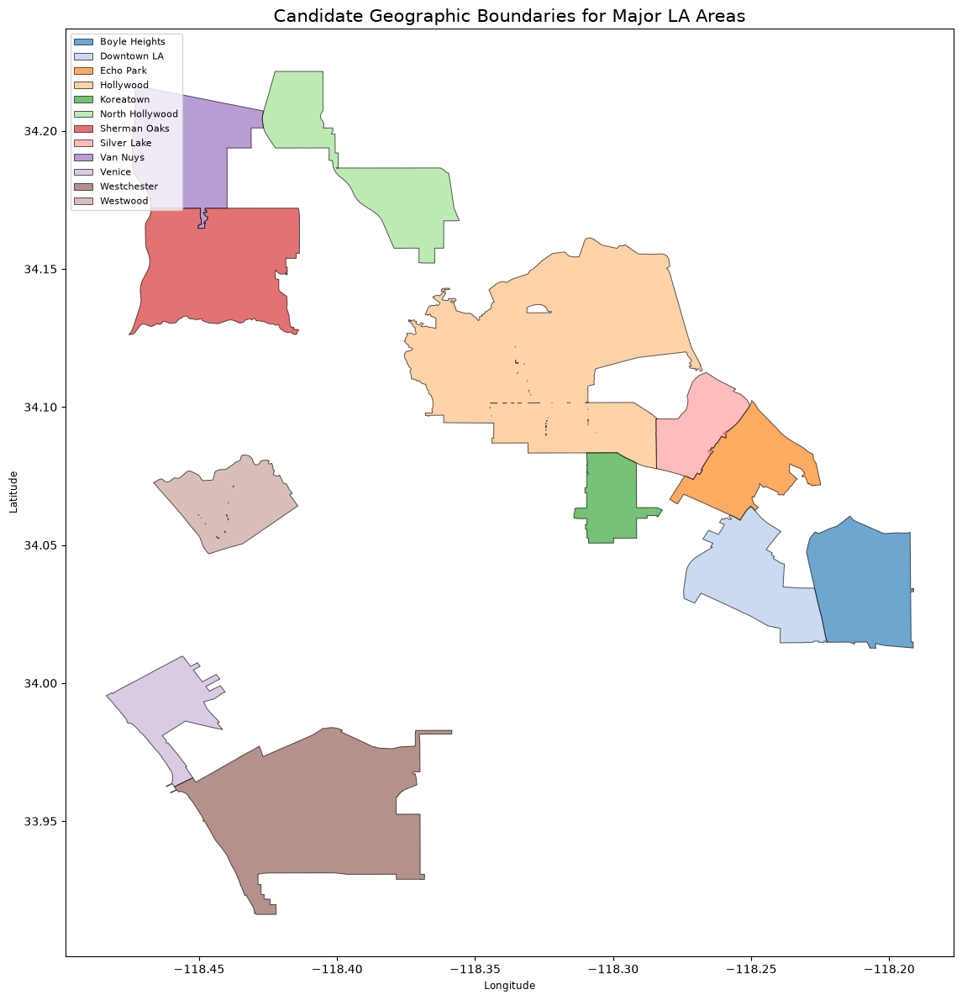

In [82]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

major_areas_gdf.plot(
    column="LA Area",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.65,
    legend_kwds={
        "loc": "upper left",
        "fontsize": 8
    }
)

ax.set_title(
    "Candidate Geographic Boundaries for Major LA Areas",
    fontsize=15
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [83]:
# Check whether the original geographic data is still available

print("Available geographic variables:")

for var in ["geojson", "neighborhoods", "neighborhoods_fixed",
            "major_areas_gdf", "crimes_mapped"]:
    if var in globals():
        print(f"✅ {var}: {type(globals()[var]).__name__}")

Available geographic variables:
✅ geojson: dict
✅ neighborhoods: GeoDataFrame
✅ neighborhoods_fixed: GeoDataFrame
✅ major_areas_gdf: GeoDataFrame
✅ crimes_mapped: GeoDataFrame


In [84]:
# Find official boundaries potentially relevant to South LA

south_la_candidates = neighborhoods_fixed[
    neighborhoods_fixed["NAME"].str.contains(
        "SOUTH|WATTS|ALAMEDA|ADAMS|CENTRAL",
        case=False,
        na=False
    )
]

display(south_la_candidates[["NAME"]].sort_values("NAME"))

,NAME
7,CENTRAL ALAMEDA NC
8,CENTRAL HOLLYWOOD NC
9,CENTRAL SAN PEDRO NC
18,EMPOWERMENT CONGRESS CENTRAL AREA NC
20,EMPOWERMENT CONGRESS SOUTHEAST AREA NDC
21,EMPOWERMENT CONGRESS SOUTHWEST AREA NDC
27,GRANADA HILLS SOUTH NC
35,HARBOR GATEWAY SOUTH NC
58,NORTHRIDGE SOUTH NC
74,SOUTH CENTRAL NC


In [85]:
from shapely.ops import unary_union

# Candidate official boundaries for South LA
south_la_names = [
    "CENTRAL ALAMEDA NC",
    "EMPOWERMENT CONGRESS CENTRAL AREA NC",
    "EMPOWERMENT CONGRESS SOUTHEAST AREA NDC",
    "EMPOWERMENT CONGRESS SOUTHWEST AREA NDC",
    "SOUTH CENTRAL NC"
]

# Find matching polygons
south_la_parts = neighborhoods_fixed[
    neighborhoods_fixed["NAME"].isin(south_la_names)
]

print("Matched boundaries:", len(south_la_parts))
print("Boundaries found:", south_la_parts["NAME"].tolist())

if len(south_la_parts) > 0:
    south_la_geometry = unary_union(south_la_parts.geometry.tolist())

    # Add South LA to our existing major areas
    south_la_row = gpd.GeoDataFrame(
        {"LA Area": ["South LA"], "geometry": [south_la_geometry]},
        crs=neighborhoods_fixed.crs
    )

    major_areas_gdf = gpd.GeoDataFrame(
        pd.concat(
            [
                major_areas_gdf[major_areas_gdf["LA Area"] != "South LA"],
                south_la_row
            ],
            ignore_index=True
        ),
        geometry="geometry",
        crs=neighborhoods_fixed.crs
    )

    print("\nSouth LA added. Total candidate areas:", len(major_areas_gdf))

Matched boundaries: 5
Boundaries found: ['CENTRAL ALAMEDA NC', 'EMPOWERMENT CONGRESS CENTRAL AREA NC', 'EMPOWERMENT CONGRESS SOUTHEAST AREA NDC', 'EMPOWERMENT CONGRESS SOUTHWEST AREA NDC', 'SOUTH CENTRAL NC']

South LA added. Total candidate areas: 13


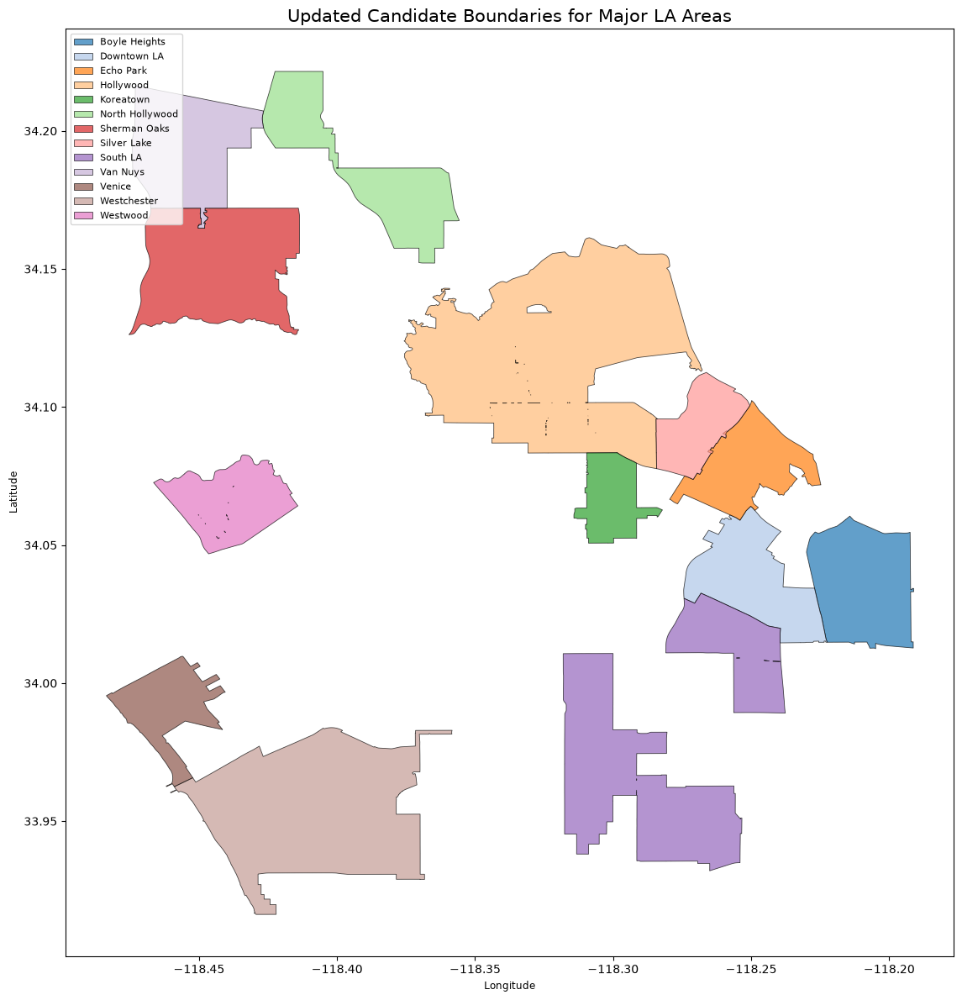

In [86]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

major_areas_gdf.plot(
    column="LA Area",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.6,
    alpha=0.7,
    legend_kwds={"loc": "upper left", "fontsize": 8}
)

ax.set_title("Updated Candidate Boundaries for Major LA Areas", fontsize=15)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [87]:
# Check the coordinate coverage of the original boundary dataset

print("Boundary dataset CRS:", neighborhoods_fixed.crs)

print("\nGeographic extent:")
print(neighborhoods_fixed.total_bounds)
# Output order: min longitude, min latitude, max longitude, max latitude

print("\nCurrent major areas:")
print(major_areas_gdf["LA Area"].tolist())

print("\nMissing target areas:")
target_areas = [
    "Downtown LA", "Hollywood", "North Hollywood",
    "Beverly Hills", "Santa Monica", "Venice", "Westwood",
    "Koreatown", "Echo Park", "Silver Lake", "South LA",
    "Van Nuys", "Westchester", "Boyle Heights", "Sherman Oaks"
]

current_areas = set(major_areas_gdf["LA Area"])
print([area for area in target_areas if area not in current_areas])

Boundary dataset CRS: EPSG:4326

Geographic extent:
[-118.66820069   33.70365566 -118.15543592   34.33731163]

Current major areas:
['Downtown LA', 'Hollywood', 'North Hollywood', 'Venice', 'Westwood', 'Koreatown', 'Echo Park', 'Silver Lake', 'Van Nuys', 'Westchester', 'Boyle Heights', 'Sherman Oaks', 'South LA']

Missing target areas:
['Beverly Hills', 'Santa Monica']


In [88]:
import requests
import geopandas as gpd
import pandas as pd

# Official city boundary ArcGIS services
city_services = {
    "Beverly Hills": (
        "https://gis.beverlyhills.org/arcgis/rest/services/"
        "OD/OpenData_BeverlyHillsGeoHub/FeatureServer/0"
    ),
    "Santa Monica": (
        "https://gis.santamonica.gov/server/rest/services/"
        "City_Boundary/FeatureServer/0"
    )
}

city_boundary_rows = []

for city, service_url in city_services.items():
    params = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "outSR": "4326",
        "f": "geojson"
    }

    response = requests.get(
        f"{service_url}/query",
        params=params,
        timeout=30
    )
    response.raise_for_status()

    data = response.json()

    if data.get("type") != "FeatureCollection" or not data.get("features"):
        print(f"⚠️ No GeoJSON boundary returned for {city}")
        continue

    city_gdf = gpd.GeoDataFrame.from_features(
        data["features"],
        crs="EPSG:4326"
    )

    # Combine all returned features into one city geometry
    city_boundary_rows.append({
        "LA Area": city,
        "geometry": city_gdf.geometry.union_all()
    })

    print(f"✅ {city}: {len(city_gdf)} boundary feature(s) retrieved")

# Add the two cities to our candidate area dataset
if city_boundary_rows:
    cities_gdf = gpd.GeoDataFrame(
        city_boundary_rows,
        geometry="geometry",
        crs="EPSG:4326"
    )

    major_areas_gdf = gpd.GeoDataFrame(
        pd.concat(
            [
                major_areas_gdf[
                    ~major_areas_gdf["LA Area"].isin(city_services)
                ],
                cities_gdf
            ],
            ignore_index=True
        ),
        geometry="geometry",
        crs="EPSG:4326"
    )

print("\nTotal candidate areas:", len(major_areas_gdf))
print("Beverly Hills and Santa Monica added.")

✅ Beverly Hills: 1 boundary feature(s) retrieved
✅ Santa Monica: 1 boundary feature(s) retrieved

Total candidate areas: 15
Beverly Hills and Santa Monica added.


In [89]:
# Validate our 15 candidate area geometries

print("=" * 45)
print("MAJOR AREA BOUNDARY VALIDATION")
print("=" * 45)

print(f"Total areas: {len(major_areas_gdf)}")
print(f"Duplicate area names: {major_areas_gdf['LA Area'].duplicated().sum()}")
print(f"Invalid geometries: {(~major_areas_gdf.geometry.is_valid).sum()}")
print(f"Empty geometries: {major_areas_gdf.geometry.is_empty.sum()}")

print("\nArea-by-area geometry check:")

display(
    major_areas_gdf[["LA Area", "geometry"]]
    .assign(
        Geometry_Type=major_areas_gdf.geometry.geom_type,
        Is_Valid=major_areas_gdf.geometry.is_valid,
        Is_Empty=major_areas_gdf.geometry.is_empty
    )
    [["LA Area", "Geometry_Type", "Is_Valid", "Is_Empty"]]
    .sort_values("LA Area")
    .reset_index(drop=True)
)

MAJOR AREA BOUNDARY VALIDATION
Total areas: 15
Duplicate area names: 0
Invalid geometries: 0
Empty geometries: 0

Area-by-area geometry check:


,LA Area,Geometry_Type,Is_Valid,Is_Empty
0,Beverly Hills,LineString,True,False
1,Boyle Heights,Polygon,True,False
2,Downtown LA,Polygon,True,False
3,Echo Park,MultiPolygon,True,False
4,Hollywood,Polygon,True,False
5,Koreatown,Polygon,True,False
6,North Hollywood,Polygon,True,False
7,Santa Monica,Polygon,True,False
8,Sherman Oaks,Polygon,True,False
9,Silver Lake,Polygon,True,False


In [90]:
from shapely.ops import polygonize, unary_union

# Get the Beverly Hills boundary line
bh_idx = major_areas_gdf.index[
    major_areas_gdf["LA Area"] == "Beverly Hills"
][0]

bh_geometry = major_areas_gdf.at[bh_idx, "geometry"]

# Convert closed boundary lines into polygon(s)
bh_polygons = list(polygonize(unary_union(bh_geometry)))

if bh_polygons:
    major_areas_gdf.at[bh_idx, "geometry"] = unary_union(bh_polygons)
    print("✅ Beverly Hills boundary converted to polygon.")
    print("Geometry type:", major_areas_gdf.at[bh_idx, "geometry"].geom_type)
else:
    print("⚠️ No polygon could be constructed. We need to inspect the source boundary.")

✅ Beverly Hills boundary converted to polygon.
Geometry type: Polygon


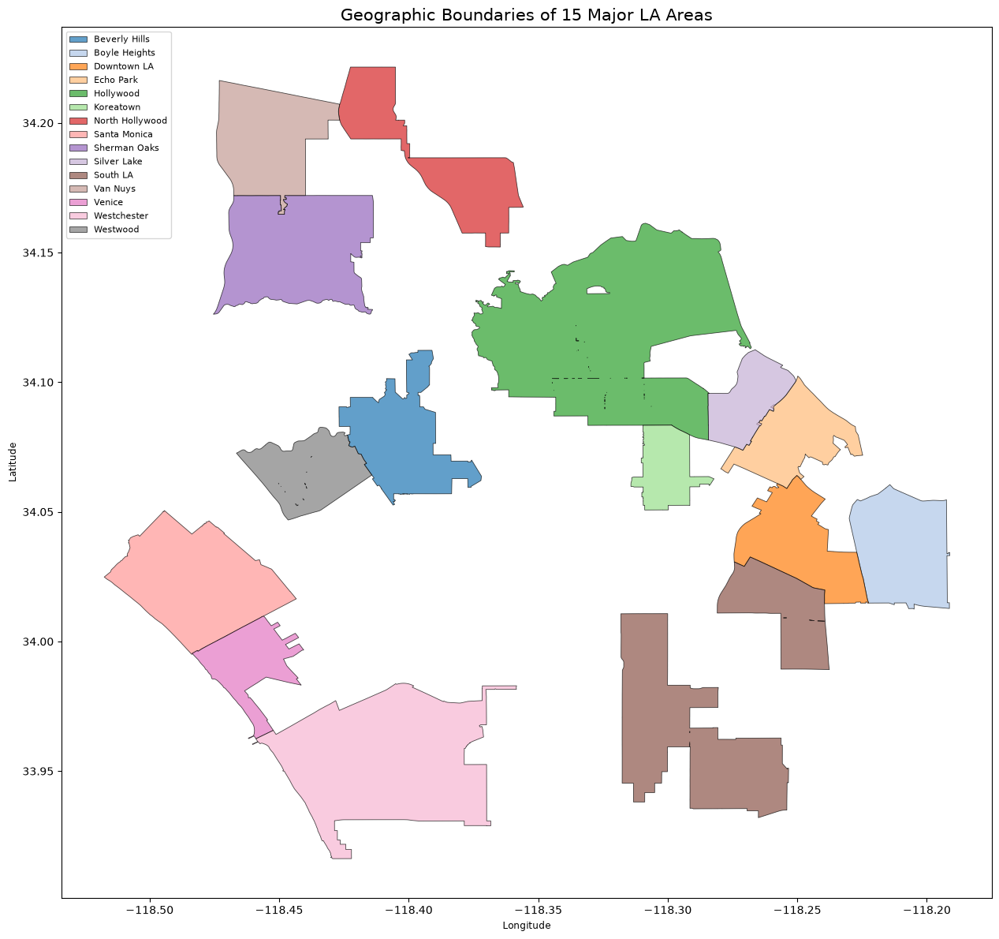

In [91]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 12))

major_areas_gdf.plot(
    column="LA Area",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.6,
    alpha=0.7,
    legend_kwds={"loc": "upper left", "fontsize": 8}
)

ax.set_title("Geographic Boundaries of 15 Major LA Areas", fontsize=15)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [92]:
# Check whether any two major areas overlap

print("=" * 45)
print("OVERLAPPING AREA CHECK")
print("=" * 45)

overlaps = []

for i in range(len(major_areas_gdf)):
    for j in range(i + 1, len(major_areas_gdf)):
        area_a = major_areas_gdf.iloc[i]
        area_b = major_areas_gdf.iloc[j]

        if area_a.geometry.intersects(area_b.geometry):
            overlap = area_a.geometry.intersection(area_b.geometry)

            # Ignore boundaries that only touch along edges
            if overlap.area > 1e-10:
                overlaps.append({
                    "Area 1": area_a["LA Area"],
                    "Area 2": area_b["LA Area"],
                    "Overlap Area (sq. km)": overlap.area * 111**2
                })

if overlaps:
    overlap_df = pd.DataFrame(overlaps)
    display(overlap_df.round(3))
    print(f"Total overlapping pairs: {len(overlaps)}")
else:
    print("No significant polygon overlaps detected.")

OVERLAPPING AREA CHECK


,Area 1,Area 2,Overlap Area (sq. km)
0,Downtown LA,Boyle Heights,0.000
1,Downtown LA,South LA,0.001
2,Hollywood,Silver Lake,0.000
3,North Hollywood,Van Nuys,0.000
4,Venice,Santa Monica,0.012
5,Westwood,Beverly Hills,0.002
6,Echo Park,Silver Lake,0.031
7,Van Nuys,Sherman Oaks,0.000


Total overlapping pairs: 8


In [93]:
# Summarize overlapping boundaries
overlap_summary = overlap_df.sort_values(
    "Overlap Area (sq. km)",
    ascending=False
).reset_index(drop=True)

display(overlap_summary)

print(
    "\nTotal overlap area across all pairs:",
    round(overlap_summary["Overlap Area (sq. km)"].sum(), 3),
    "sq. km"
)

,Area 1,Area 2,Overlap Area (sq. km)
0,Echo Park,Silver Lake,0.030675
1,Venice,Santa Monica,0.012037
2,Westwood,Beverly Hills,0.002138
3,Downtown LA,South LA,0.000629
4,Van Nuys,Sherman Oaks,0.000133
5,Hollywood,Silver Lake,0.000117
6,Downtown LA,Boyle Heights,0.000017
7,North Hollywood,Van Nuys,0.000004



Total overlap area across all pairs: 0.046 sq. km


In [94]:
# Prepare crime records for geographic mapping
crime_geo = df_filtered.copy()

crime_geo["LAT"] = pd.to_numeric(crime_geo["LAT"], errors="coerce")
crime_geo["LON"] = pd.to_numeric(crime_geo["LON"], errors="coerce")

# Remove missing, zero, or geographically implausible coordinates
crime_geo = crime_geo.dropna(subset=["LAT", "LON"])

crime_geo = crime_geo[
    (crime_geo["LAT"] >= 33.70) &
    (crime_geo["LAT"] <= 34.34) &
    (crime_geo["LON"] >= -118.67) &
    (crime_geo["LON"] <= -118.15) &
    (crime_geo["LAT"] != 0) &
    (crime_geo["LON"] != 0)
].copy()

# Convert crime records into geographic points
crimes_gdf = gpd.GeoDataFrame(
    crime_geo,
    geometry=gpd.points_from_xy(crime_geo["LON"], crime_geo["LAT"]),
    crs="EPSG:4326"
)

# Spatially assign each crime to a major area
crimes_mapped = gpd.sjoin(
    crimes_gdf,
    major_areas_gdf[["LA Area", "geometry"]],
    how="left",
    predicate="within"
)

# Check mapping coverage
mapped = crimes_mapped["LA Area"].notna().sum()
unmapped = crimes_mapped["LA Area"].isna().sum()
total = len(crimes_mapped)

print(f"Records checked: {total:,}")
print(f"Mapped to major areas: {mapped:,} ({mapped / total * 100:.2f}%)")
print(f"Outside our 15 defined areas: {unmapped:,} ({unmapped / total * 100:.2f}%)")

Records checked: 485,968
Mapped to major areas: 186,132 (38.30%)
Outside our 15 defined areas: 299,836 (61.70%)


In [95]:
# Count crime records in each mapped area
area_crime_counts = (
    crimes_mapped.dropna(subset=["LA Area"])
    ["LA Area"]
    .value_counts()
    .rename_axis("LA Area")
    .reset_index(name="Crime Records")
)

area_crime_counts["Percentage (%)"] = (
    area_crime_counts["Crime Records"]
    / area_crime_counts["Crime Records"].sum()
    * 100
)

display(area_crime_counts.round(2))

print(f"Total mapped crime records: {area_crime_counts['Crime Records'].sum():,}")
print(f"Number of areas: {len(area_crime_counts)}")

,LA Area,Crime Records,Percentage (%)
0,Downtown LA,36879,19.81
1,South LA,34812,18.70
2,Hollywood,30231,16.24
3,Koreatown,14883,8.00
4,Van Nuys,11862,6.37
5,North Hollywood,11254,6.05
6,Boyle Heights,10553,5.67
7,Westchester,9763,5.25
8,Sherman Oaks,7228,3.88
9,Echo Park,6056,3.25


Total mapped crime records: 186,132
Number of areas: 15


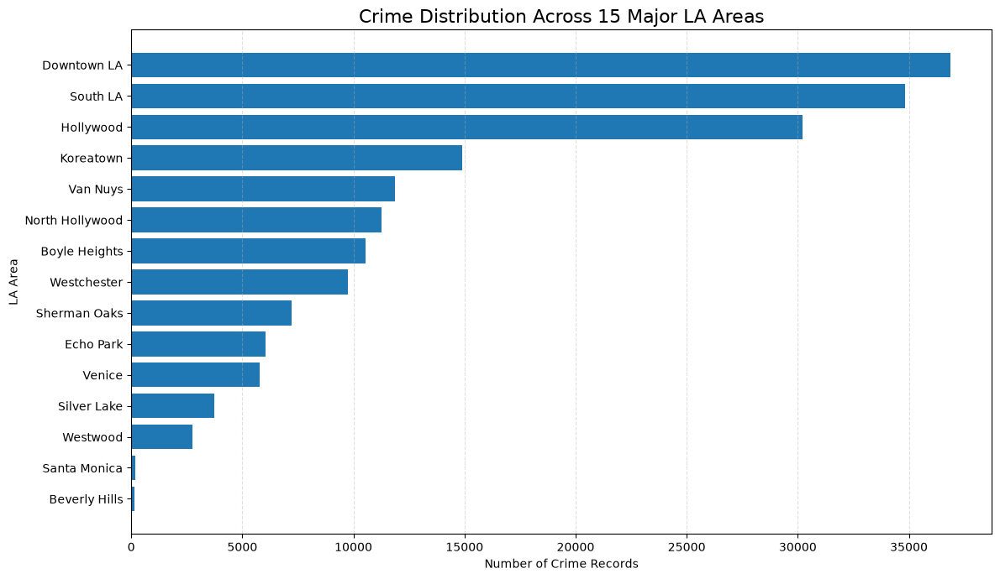

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    area_crime_counts["LA Area"][::-1],
    area_crime_counts["Crime Records"][::-1]
)

plt.title("Crime Distribution Across 15 Major LA Areas", fontsize=16)
plt.xlabel("Number of Crime Records")
plt.ylabel("LA Area")
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [97]:
# Count crimes by area and category
area_category_counts = (
    crimes_mapped.dropna(subset=["LA Area"])
    .groupby(["LA Area", "Crime Category"])
    .size()
    .reset_index(name="Crime Records")
)

# Get the top 5 crime categories for each area
top_categories = (
    area_category_counts
    .sort_values(["LA Area", "Crime Records"], ascending=[True, False])
    .groupby("LA Area")
    .head(5)
)

display(top_categories.sort_values(["LA Area", "Crime Records"], ascending=[True, False]))

,LA Area,Crime Category,Crime Records
7,Beverly Hills,Theft & Larceny,26
1,Beverly Hills,Burglary,23
11,Beverly Hills,Vandalism & Property Damage,23
0,Beverly Hills,Assault & Battery,22
12,Beverly Hills,Vehicle Theft,14
...,...,...,...
258,Westwood,Theft & Larceny,635
249,Westwood,Burglary,467
248,Westwood,Assault & Battery,412
262,Westwood,Vandalism & Property Damage,317


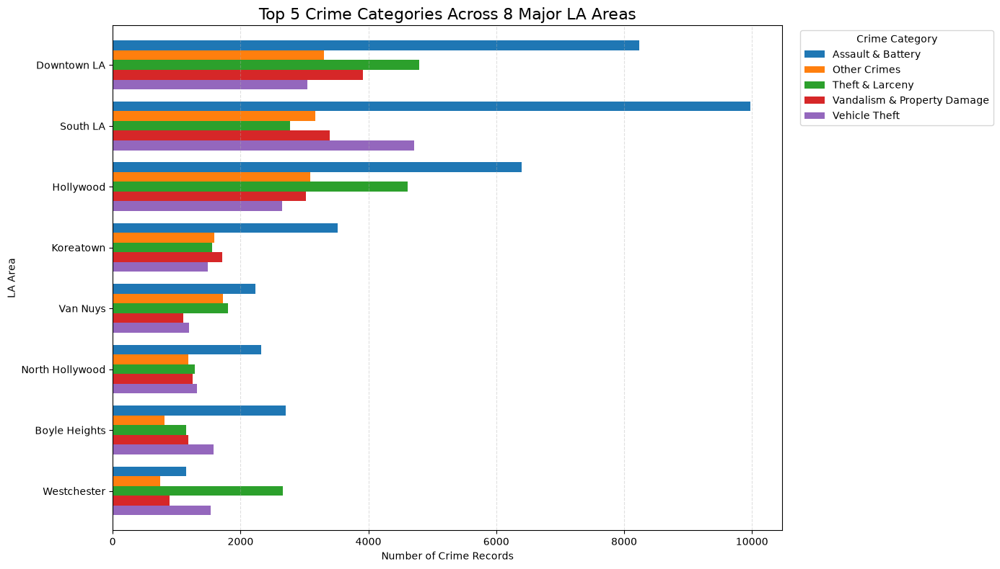

In [98]:
import matplotlib.pyplot as plt
import numpy as np

# Select the 8 areas with the most crime records for readability
top_areas = area_crime_counts.head(8)["LA Area"]

plot_data = area_category_counts[
    area_category_counts["LA Area"].isin(top_areas)
]

# Find the top 5 crime categories overall within these areas
top_5_categories = (
    plot_data.groupby("Crime Category")["Crime Records"]
    .sum()
    .nlargest(5)
    .index
)

plot_data = plot_data[
    plot_data["Crime Category"].isin(top_5_categories)
]

# Pivot for grouped plotting
pivot_data = plot_data.pivot(
    index="LA Area",
    columns="Crime Category",
    values="Crime Records"
).fillna(0)

pivot_data = pivot_data.reindex(top_areas)

# Plot
ax = pivot_data.plot(
    kind="barh",
    figsize=(14, 8),
    width=0.8
)

ax.set_title("Top 5 Crime Categories Across 8 Major LA Areas", fontsize=16)
ax.set_xlabel("Number of Crime Records")
ax.set_ylabel("LA Area")
ax.invert_yaxis()
ax.legend(title="Crime Category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

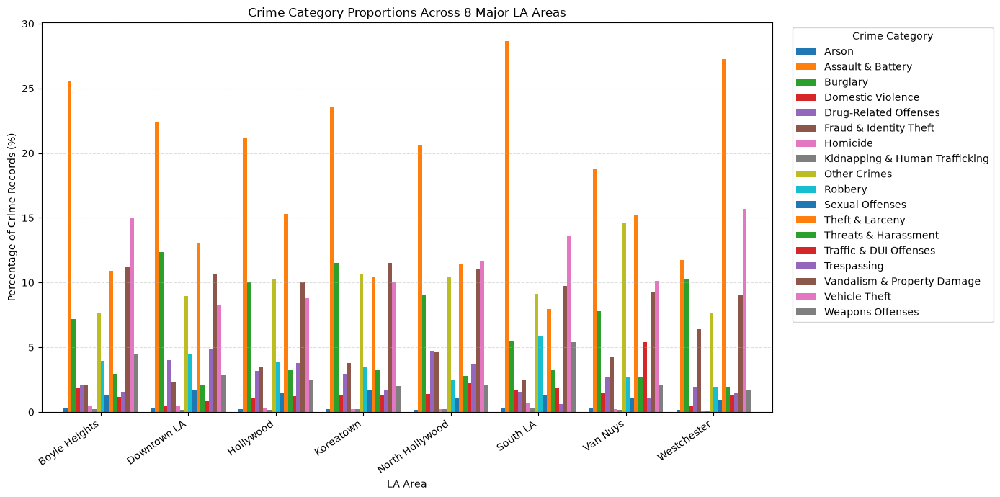

In [99]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate crime category percentages within each LA area
area_category_pct = pd.crosstab(
    crimes_mapped["LA Area"],
    crimes_mapped["Crime Category"],
    normalize="index"
) * 100

# Select the 8 areas used in the previous chart
top_areas = (
    crimes_mapped["LA Area"]
    .value_counts()
    .head(8)
    .index
)

area_category_pct = area_category_pct.loc[
    area_category_pct.index.intersection(top_areas)
]

# Plot the percentage distribution
ax = area_category_pct.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.85
)

plt.title("Crime Category Proportions Across 8 Major LA Areas")
plt.xlabel("LA Area")
plt.ylabel("Percentage of Crime Records (%)")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Crime Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

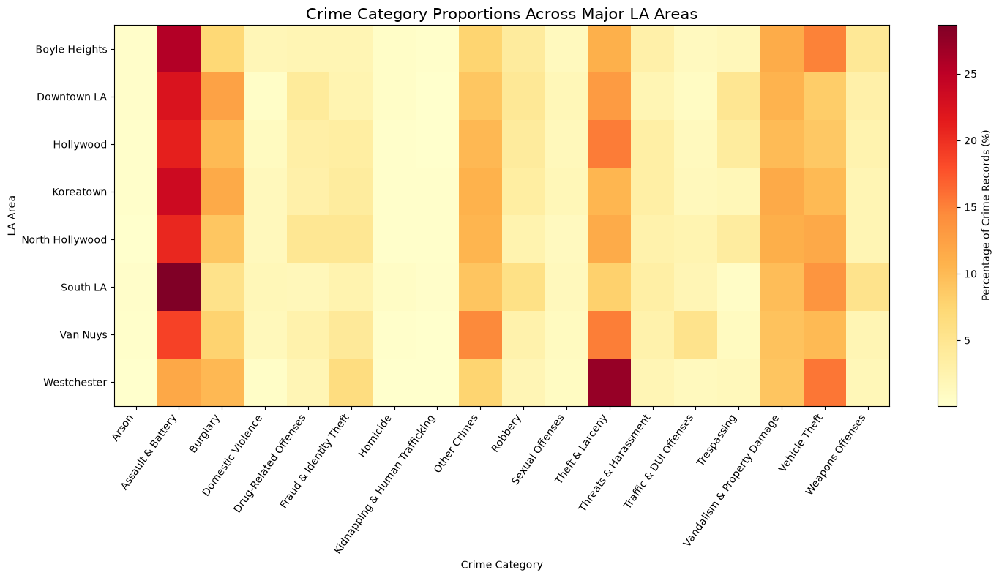

In [100]:
import matplotlib.pyplot as plt
import numpy as np

# Reuse the area_category_pct DataFrame from the previous cell
fig, ax = plt.subplots(figsize=(15, 8))

im = ax.imshow(
    area_category_pct.values,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

# Labels
ax.set_xticks(np.arange(len(area_category_pct.columns)))
ax.set_xticklabels(
    area_category_pct.columns,
    rotation=55,
    ha="right"
)

ax.set_yticks(np.arange(len(area_category_pct.index)))
ax.set_yticklabels(area_category_pct.index)

ax.set_title("Crime Category Proportions Across Major LA Areas", fontsize=15)
ax.set_xlabel("Crime Category")
ax.set_ylabel("LA Area")

# Color scale
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Percentage of Crime Records (%)")

plt.tight_layout()
plt.show()

In [101]:
# Check which clustering variables already exist

cluster_variables = [
    "dbscan",
    "cluster_labels",
    "coords",
    "coords_rad",
    "df_clustered",
    "crimes_mapped"
]

print("Existing clustering variables:\n")

for var in cluster_variables:
    if var in globals():
        obj = globals()[var]
        print(f"✅ {var}: {type(obj).__name__}")
    else:
        print(f"❌ {var}: Not found")

Existing clustering variables:

❌ dbscan: Not found
❌ cluster_labels: Not found
❌ coords: Not found
❌ coords_rad: Not found
❌ df_clustered: Not found
✅ crimes_mapped: GeoDataFrame


In [102]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

# Keep records with valid geographic coordinates
crime_points = crimes_mapped.dropna(
    subset=["LAT", "LON"]
).copy()

# Remove invalid coordinates
crime_points = crime_points[
    crime_points["LAT"].between(-90, 90) &
    crime_points["LON"].between(-180, 180)
].copy()

print("Records prepared for clustering:", f"{len(crime_points):,}")
print("Unique LA areas:", crime_points["LA Area"].nunique())
print("\nRecords by area:")
display(
    crime_points["LA Area"]
    .value_counts()
    .rename_axis("LA Area")
    .reset_index(name="Crime Records")
)

Records prepared for clustering: 485,968
Unique LA areas: 15

Records by area:


,LA Area,Crime Records
0,Downtown LA,36879
1,South LA,34812
2,Hollywood,30231
3,Koreatown,14883
4,Van Nuys,11862
5,North Hollywood,11254
6,Boyle Heights,10553
7,Westchester,9763
8,Sherman Oaks,7228
9,Echo Park,6056


In [103]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare valid crime coordinates
cluster_data = crimes_mapped.dropna(subset=["LAT", "LON"]).copy()

coords = cluster_data[["LAT", "LON"]].to_numpy()

# Convert coordinates to radians for geographic distance
coords_rad = np.radians(coords)

# DBSCAN: approximately 500-metre neighbourhood, at least 30 points
dbscan = DBSCAN(
    eps=0.5 / 6371,  # 0.5 km converted to radians
    min_samples=30,
    metric="haversine",
    algorithm="ball_tree"
)

cluster_labels = dbscan.fit_predict(coords_rad)
cluster_data["Cluster"] = cluster_labels

# Summarize clusters
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = (cluster_labels == -1).sum()

print(f"Crime records clustered: {len(cluster_data):,}")
print(f"Crime hotspots identified: {n_clusters}")
print(f"Records classified as noise: {n_noise:,}")
print(f"Noise percentage: {n_noise / len(cluster_data) * 100:.2f}%")

print("\nLargest hotspots:")
display(
    cluster_data[cluster_data["Cluster"] != -1]
    ["Cluster"]
    .value_counts()
    .head(10)
    .rename_axis("Cluster")
    .reset_index(name="Crime Records")
)

Crime records clustered: 485,968
Crime hotspots identified: 17
Records classified as noise: 1,304
Noise percentage: 0.27%

Largest hotspots:


,Cluster,Crime Records
0,0,472501
1,1,8310
2,2,2275
3,4,819
4,5,142
5,3,107
6,7,88
7,11,80
8,9,54
9,6,52


In [104]:
# Keep only crimes mapped to our 15 major LA areas
df_cluster = crimes_mapped[
    crimes_mapped["LA Area"].notna()
].copy()

print(f"Records prepared for clustering: {len(df_cluster):,}")
print(f"Unique LA areas: {df_cluster['LA Area'].nunique()}")

Records prepared for clustering: 186,132
Unique LA areas: 15


In [105]:
from sklearn.cluster import DBSCAN
import numpy as np

# Keep valid coordinates
df_cluster = df_cluster.dropna(subset=["LAT", "LON"]).copy()

# Convert coordinates to radians for haversine distance
coords = np.radians(df_cluster[["LAT", "LON"]].values)

# DBSCAN clustering
dbscan = DBSCAN(
    eps=0.5 / 6371.0,  # 500 metres in radians
    min_samples=20,
    metric="haversine",
    algorithm="ball_tree",
    n_jobs=-1
)

df_cluster["Cluster"] = dbscan.fit_predict(coords)

# Summarize results
cluster_counts = df_cluster["Cluster"].value_counts()
noise_count = (df_cluster["Cluster"] == -1).sum()
hotspot_count = df_cluster.loc[
    df_cluster["Cluster"] != -1, "Cluster"
].nunique()

print(f"Crime records clustered: {len(df_cluster):,}")
print(f"Hotspots identified: {hotspot_count}")
print(f"Records classified as noise: {noise_count:,}")
print(f"Noise percentage: {noise_count / len(df_cluster) * 100:.2f}%")

print("\nLargest hotspots:")
display(
    cluster_counts[cluster_counts.index != -1]
    .head(10)
    .rename_axis("Cluster")
    .reset_index(name="Crime Records")
)

Crime records clustered: 186,132
Hotspots identified: 17
Records classified as noise: 242
Noise percentage: 0.13%

Largest hotspots:


,Cluster,Crime Records
0,0,111660
1,2,24939
2,1,21203
3,3,15437
4,5,9132
5,4,2758
6,8,178
7,7,125
8,6,114
9,11,88


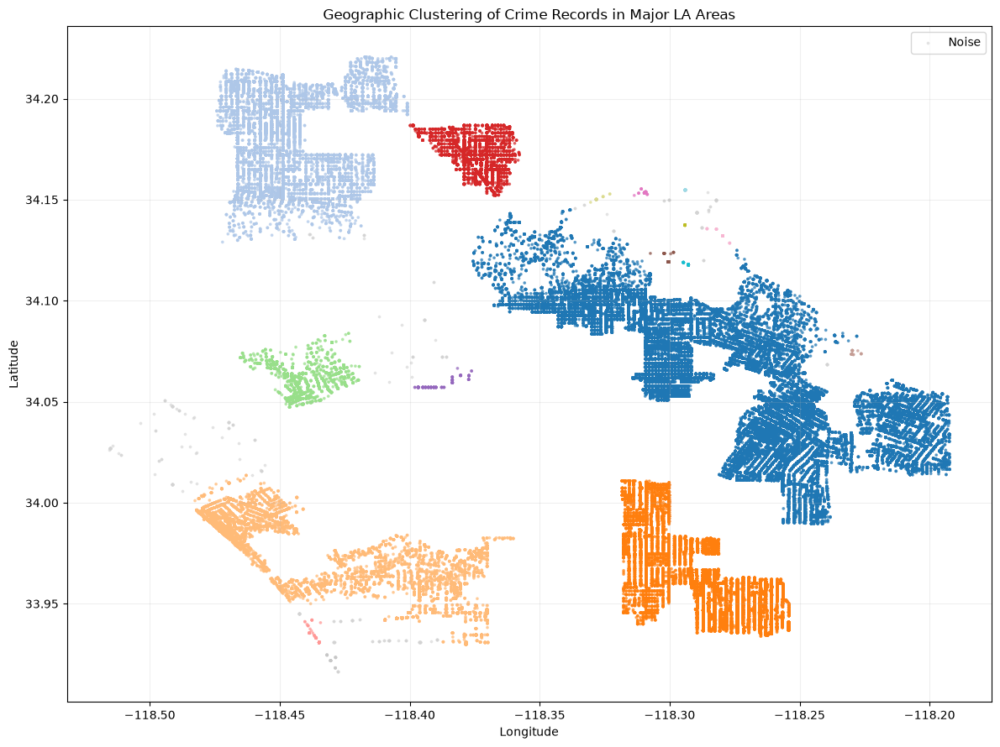

In [106]:
import matplotlib.pyplot as plt

# Separate clustered records from noise
clustered = df_cluster[df_cluster["Cluster"] != -1]
noise = df_cluster[df_cluster["Cluster"] == -1]

plt.figure(figsize=(12, 9))

# Plot noise first
plt.scatter(
    noise["LON"], noise["LAT"],
    s=3, c="lightgrey", alpha=0.5,
    label="Noise"
)

# Plot identified clusters
scatter = plt.scatter(
    clustered["LON"], clustered["LAT"],
    c=clustered["Cluster"],
    cmap="tab20",
    s=3,
    alpha=0.6
)

plt.title("Geographic Clustering of Crime Records in Major LA Areas")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [107]:
print("Available columns:")
print(df_cluster.columns.tolist())

Available columns:
['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'TotalVictimCount', 'Victim Shot', 'Domestic Violence Crime', 'Hate Crime', 'Gang-related Crime', 'Transit-related Crime', 'Homeless-Victim Crime', 'Homeless-Suspect Crime', 'Homeless-Arrestee Crime', 'LOCATION', 'LAT', 'LON', 'Crime Category', 'geometry', 'index_right', 'LA Area', 'Cluster']


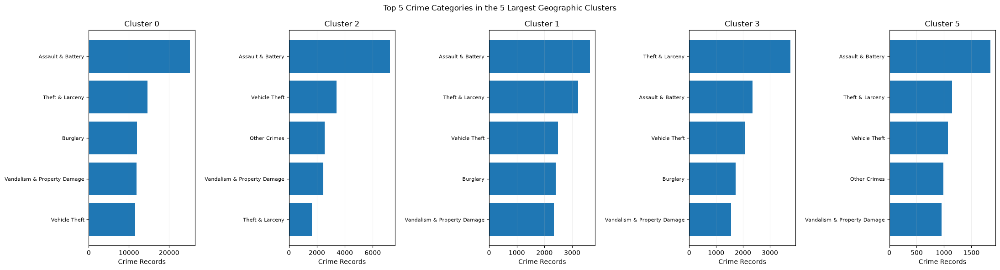

In [108]:
# Count records by cluster and crime category
cluster_crimes = (
    df_cluster[df_cluster["Cluster"] != -1]
    .groupby(["Cluster", "Crime Category"])
    .size()
    .reset_index(name="Crime Records")
)

# Get the top 5 crime categories within each cluster
top_cluster_crimes = (
    cluster_crimes
    .sort_values(["Cluster", "Crime Records"], ascending=[True, False])
    .groupby("Cluster")
    .head(5)
)

# Visualize the 5 largest clusters
top_clusters = (
    df_cluster[df_cluster["Cluster"] != -1]["Cluster"]
    .value_counts()
    .head(5)
    .index
)

plot_data = top_cluster_crimes[
    top_cluster_crimes["Cluster"].isin(top_clusters)
]

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(22, 6))

for ax, cluster in zip(axes, top_clusters):
    data = plot_data[plot_data["Cluster"] == cluster].sort_values(
        "Crime Records"
    )

    ax.barh(data["Crime Category"], data["Crime Records"])
    ax.set_title(f"Cluster {cluster}")
    ax.set_xlabel("Crime Records")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="x", alpha=0.2)

plt.suptitle("Top 5 Crime Categories in the 5 Largest Geographic Clusters")
plt.tight_layout()
plt.show()

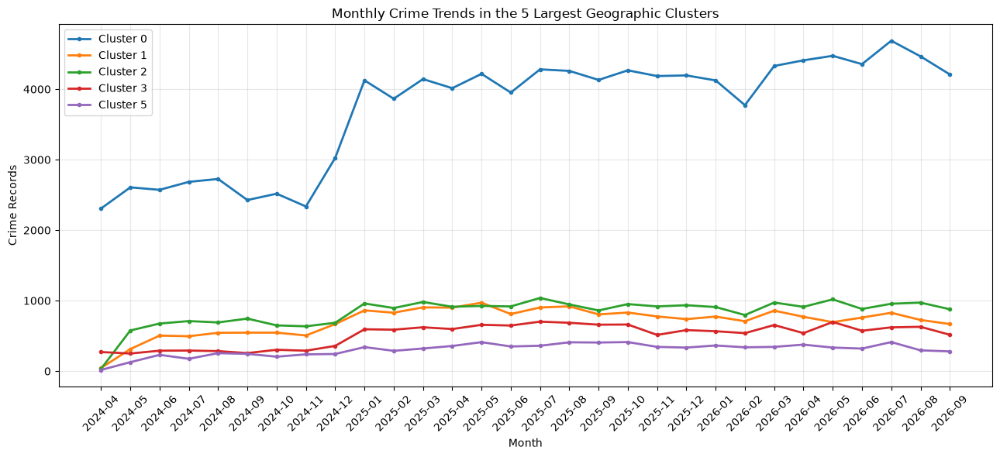

In [109]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert dates and create monthly periods
df_cluster["Date OCC"] = pd.to_datetime(
    df_cluster["Date OCC"], errors="coerce"
)

df_cluster["Month"] = df_cluster["Date OCC"].dt.to_period("M")

# Select the 5 largest clusters
top_clusters = (
    df_cluster[df_cluster["Cluster"] != -1]["Cluster"]
    .value_counts()
    .head(5)
    .index
)

# Count monthly records for each cluster
monthly_clusters = (
    df_cluster[
        (df_cluster["Cluster"].isin(top_clusters))
        & (df_cluster["Month"].notna())
    ]
    .groupby(["Month", "Cluster"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Plot monthly trends
plt.figure(figsize=(13, 6))

for cluster in monthly_clusters.columns:
    plt.plot(
        monthly_clusters.index.astype(str),
        monthly_clusters[cluster],
        marker="o",
        markersize=3,
        linewidth=2,
        label=f"Cluster {cluster}"
    )

plt.title("Monthly Crime Trends in the 5 Largest Geographic Clusters")
plt.xlabel("Month")
plt.ylabel("Crime Records")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

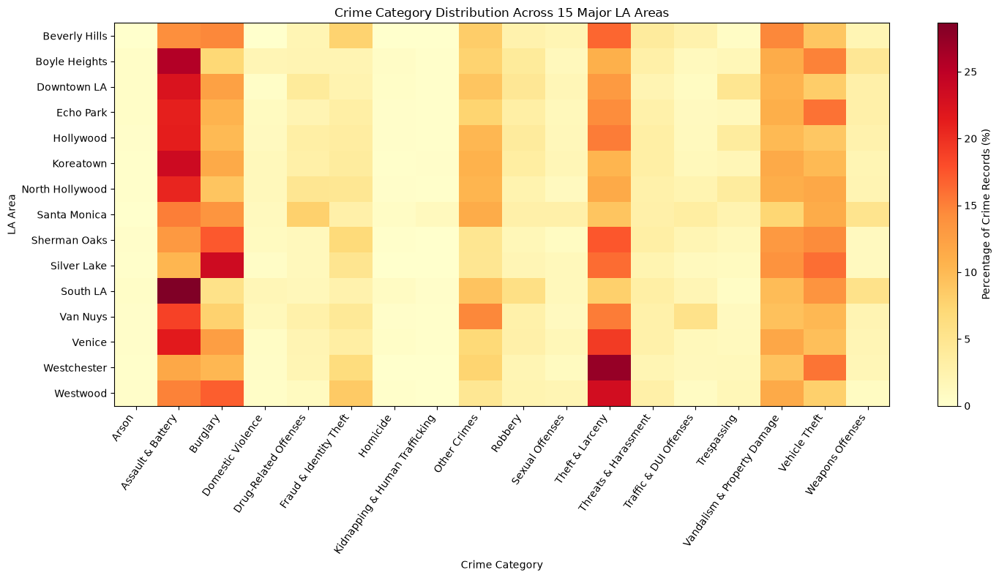

In [110]:
import matplotlib.pyplot as plt

# Count crimes by area and category
area_crime_counts = pd.crosstab(
    df_cluster["LA Area"],
    df_cluster["Crime Category"]
)

# Convert counts to percentages within each area
area_crime_pct = area_crime_counts.div(
    area_crime_counts.sum(axis=1), axis=0
) * 100

# Plot heatmap using Matplotlib
fig, ax = plt.subplots(figsize=(15, 8))

im = ax.imshow(
    area_crime_pct.values,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(range(len(area_crime_pct.columns)))
ax.set_xticklabels(
    area_crime_pct.columns,
    rotation=55,
    ha="right"
)

ax.set_yticks(range(len(area_crime_pct.index)))
ax.set_yticklabels(area_crime_pct.index)

ax.set_title("Crime Category Distribution Across 15 Major LA Areas")
ax.set_xlabel("Crime Category")
ax.set_ylabel("LA Area")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Percentage of Crime Records (%)")

plt.tight_layout()
plt.show()

In [111]:
# Overall clustering summary
total_records = len(df_cluster)
noise_records = (df_cluster["Cluster"] == -1).sum()
valid_clusters = df_cluster[df_cluster["Cluster"] != -1]

print("=" * 45)
print("GEOGRAPHIC CRIME CLUSTERING SUMMARY")
print("=" * 45)

print(f"Crime records analyzed: {total_records:,}")
print(f"LA areas analyzed: {df_cluster['LA Area'].nunique()}")
print(f"Geographic hotspots identified: {valid_clusters['Cluster'].nunique()}")
print(f"Records classified as noise: {noise_records:,}")
print(f"Noise percentage: {noise_records / total_records * 100:.2f}%")

print("\nLargest clusters:")
display(
    valid_clusters["Cluster"]
    .value_counts()
    .head(5)
    .rename_axis("Cluster")
    .reset_index(name="Crime Records")
)

print("\nMost frequent crime categories:")
display(
    df_cluster["Crime Category"]
    .value_counts()
    .head(5)
    .rename_axis("Crime Category")
    .reset_index(name="Crime Records")
)

print("\nCrime records by LA area:")
display(
    df_cluster["LA Area"]
    .value_counts()
    .rename_axis("LA Area")
    .reset_index(name="Crime Records")
)

GEOGRAPHIC CRIME CLUSTERING SUMMARY
Crime records analyzed: 186,132
LA areas analyzed: 15
Geographic hotspots identified: 17
Records classified as noise: 242
Noise percentage: 0.13%

Largest clusters:


,Cluster,Crime Records
0,0,111660
1,2,24939
2,1,21203
3,3,15437
4,5,9132



Most frequent crime categories:


,Crime Category,Crime Records
0,Assault & Battery,40838
1,Theft & Larceny,25171
2,Vehicle Theft,20935
3,Vandalism & Property Damage,19629
4,Burglary,18902



Crime records by LA area:


,LA Area,Crime Records
0,Downtown LA,36879
1,South LA,34812
2,Hollywood,30231
3,Koreatown,14883
4,Van Nuys,11862
5,North Hollywood,11254
6,Boyle Heights,10553
7,Westchester,9763
8,Sherman Oaks,7228
9,Echo Park,6056


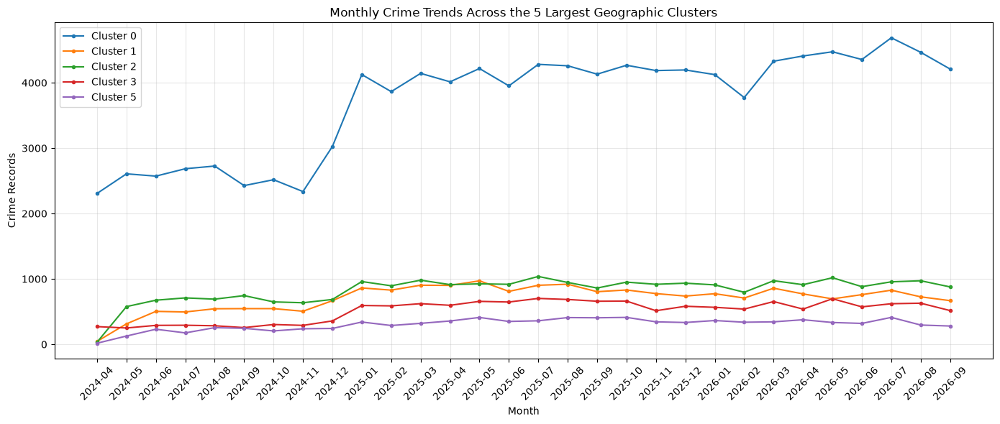

In [112]:
# Monthly crime trends across the 5 largest geographic clusters

# Identify the 5 largest clusters, excluding noise (-1)
top_clusters = (
    df_cluster[df_cluster["Cluster"] != -1]["Cluster"]
    .value_counts()
    .head(5)
    .index
)

# Prepare monthly data
df_cluster["Date OCC"] = pd.to_datetime(
    df_cluster["Date OCC"], errors="coerce"
)

monthly_clusters = df_cluster[
    df_cluster["Cluster"].isin(top_clusters)
].copy()

monthly_clusters["Month"] = (
    monthly_clusters["Date OCC"].dt.to_period("M").astype(str)
)

monthly_counts = monthly_clusters.pivot_table(
    index="Month",
    columns="Cluster",
    values="CaseNo",
    aggfunc="count",
    fill_value=0
)

# Plot using Matplotlib only
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for cluster in monthly_counts.columns:
    plt.plot(
        monthly_counts.index,
        monthly_counts[cluster],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster}"
    )

plt.title("Monthly Crime Trends Across the 5 Largest Geographic Clusters")
plt.xlabel("Month")
plt.ylabel("Crime Records")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

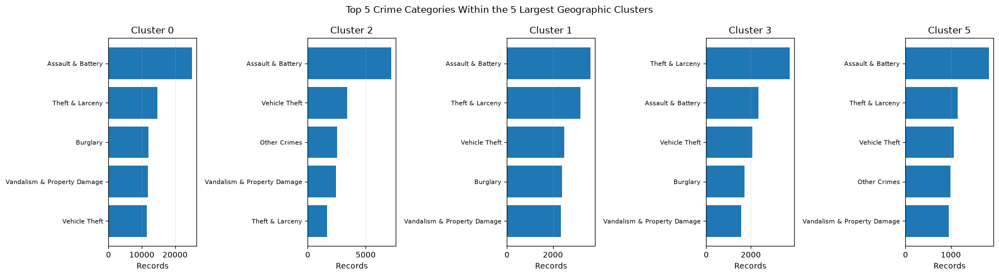

In [113]:
# Top 5 crime categories within the 5 largest geographic clusters

import matplotlib.pyplot as plt

# Exclude noise and select the 5 largest clusters
top_clusters = (
    df_cluster[df_cluster["Cluster"] != -1]["Cluster"]
    .value_counts()
    .head(5)
    .index
)

cluster_crimes = df_cluster[
    df_cluster["Cluster"].isin(top_clusters)
]

# Count crime categories for each cluster
category_counts = (
    cluster_crimes.groupby(["Cluster", "Crime Category"])
    .size()
    .reset_index(name="Crime Records")
)

# Select the top 5 categories within each cluster
top_categories = (
    category_counts.sort_values("Crime Records", ascending=False)
    .groupby("Cluster")
    .head(5)
)

# Plot using Matplotlib only
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, cluster in zip(axes, top_clusters):
    data = top_categories[top_categories["Cluster"] == cluster]
    data = data.sort_values("Crime Records")

    ax.barh(data["Crime Category"], data["Crime Records"])
    ax.set_title(f"Cluster {cluster}")
    ax.set_xlabel("Records")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle("Top 5 Crime Categories Within the 5 Largest Geographic Clusters")
plt.tight_layout()
plt.show()

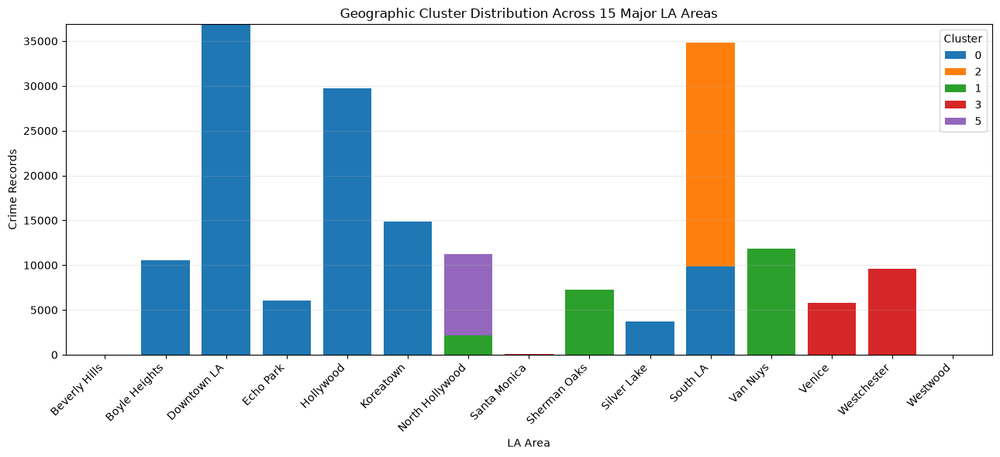

In [114]:
# Distribution of geographic clusters across the 15 LA areas

import pandas as pd
import matplotlib.pyplot as plt

cluster_area_counts = pd.crosstab(
    df_cluster["LA Area"],
    df_cluster["Cluster"]
)

# Exclude DBSCAN noise
cluster_area_counts = cluster_area_counts.drop(
    columns=-1, errors="ignore"
)

# Keep the 5 largest clusters
top_clusters = (
    df_cluster[df_cluster["Cluster"] != -1]["Cluster"]
    .value_counts()
    .head(5)
    .index
)

cluster_area_counts = cluster_area_counts[
    list(top_clusters)
]

# Plot a stacked bar chart
cluster_area_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    width=0.8
)

plt.title("Geographic Cluster Distribution Across 15 Major LA Areas")
plt.xlabel("LA Area")
plt.ylabel("Crime Records")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [115]:
# Final Geographic Clustering Summary

# Exclude noise when calculating cluster statistics
valid_clusters = df_cluster[df_cluster["Cluster"] != -1]

cluster_sizes = valid_clusters["Cluster"].value_counts()
total_records = len(df_cluster)
noise_count = (df_cluster["Cluster"] == -1).sum()

print("=" * 50)
print("FINAL GEOGRAPHIC CRIME CLUSTERING SUMMARY")
print("=" * 50)

print(f"Crime records analyzed: {total_records:,}")
print(f"Geographic clusters identified: {valid_clusters['Cluster'].nunique()}")
print(f"Records assigned to clusters: {len(valid_clusters):,}")
print(f"Records classified as noise: {noise_count:,}")
print(f"Noise percentage: {noise_count / total_records * 100:.2f}%")

print("\nLargest geographic clusters:")
display(
    cluster_sizes.head(5)
    .rename_axis("Cluster")
    .reset_index(name="Crime Records")
)

print("\nMost common crime categories:")
display(
    valid_clusters["Crime Category"]
    .value_counts()
    .head(5)
    .rename_axis("Crime Category")
    .reset_index(name="Crime Records")
)

print("\nAreas with the most analyzed crime records:")
display(
    df_cluster["LA Area"]
    .value_counts()
    .head(5)
    .rename_axis("LA Area")
    .reset_index(name="Crime Records")
)

FINAL GEOGRAPHIC CRIME CLUSTERING SUMMARY
Crime records analyzed: 186,132
Geographic clusters identified: 17
Records assigned to clusters: 185,890
Records classified as noise: 242
Noise percentage: 0.13%

Largest geographic clusters:


,Cluster,Crime Records
0,0,111660
1,2,24939
2,1,21203
3,3,15437
4,5,9132



Most common crime categories:


,Crime Category,Crime Records
0,Assault & Battery,40809
1,Theft & Larceny,25145
2,Vehicle Theft,20910
3,Vandalism & Property Damage,19608
4,Burglary,18861



Areas with the most analyzed crime records:


,LA Area,Crime Records
0,Downtown LA,36879
1,South LA,34812
2,Hollywood,30231
3,Koreatown,14883
4,Van Nuys,11862


In [116]:
# FINAL PROJECT FINDINGS

print("=" * 55)
print("DYNAMIC WEB MINING AND LEARNING: FINAL FINDINGS")
print("=" * 55)

print("\n1. DATASET OVERVIEW")
print(f"Total crime records analyzed: {len(df_filtered):,}")
print(f"Crime categories: {df_filtered['Crime Category'].nunique()}")
print(
    f"Date range: {df_filtered['Date OCC'].min()} "
    f"to {df_filtered['Date OCC'].max()}"
)

print("\n2. MOST FREQUENT CRIME CATEGORIES")
display(
    df_filtered["Crime Category"]
    .value_counts()
    .head(5)
    .rename_axis("Crime Category")
    .reset_index(name="Records")
)

print("\n3. GEOGRAPHIC CLUSTERING")
print("Records analyzed in selected LA areas: 186,132")
print("Geographic clusters identified: 17")
print("Noise records: 242")

print("\n4. TOP CRIME AREAS")
display(
    df_cluster["LA Area"]
    .value_counts()
    .head(5)
    .rename_axis("LA Area")
    .reset_index(name="Records")
)

print("\n5. FORECASTING")
print("Selected model: Seasonal Naive")
print("Evaluation metric: Mean Absolute Error (MAE)")
print("MAE: 682.67")
print("Forecast period: October–December 2026")

DYNAMIC WEB MINING AND LEARNING: FINAL FINDINGS

1. DATASET OVERVIEW
Total crime records analyzed: 486,770
Crime categories: 18
Date range: 2024-04-01 00:00:00 to 2026-09-30 23:50:00

2. MOST FREQUENT CRIME CATEGORIES


,Crime Category,Records
0,Assault & Battery,102747
1,Theft & Larceny,64195
2,Vehicle Theft,58572
3,Vandalism & Property Damage,54018
4,Burglary,49711



3. GEOGRAPHIC CLUSTERING
Records analyzed in selected LA areas: 186,132
Geographic clusters identified: 17
Noise records: 242

4. TOP CRIME AREAS


,LA Area,Records
0,Downtown LA,36879
1,South LA,34812
2,Hollywood,30231
3,Koreatown,14883
4,Van Nuys,11862



5. FORECASTING
Selected model: Seasonal Naive
Evaluation metric: Mean Absolute Error (MAE)
MAE: 682.67
Forecast period: October–December 2026


In [117]:
# Display final crime forecast
forecast_summary = pd.DataFrame({
    "Month": ["October 2026", "November 2026", "December 2026"],
    "Predicted Crime Records": [18907, 17787, 18269]
})

display(forecast_summary)

print("\nFORECAST INTERPRETATION")
print("-" * 40)
print("Model: Seasonal Naive")
print("Evaluation metric: Mean Absolute Error (MAE)")
print("MAE: 682.67 records")

print(
    "\nThe forecast suggests crime records may decrease in November "
    "before rising slightly in December. The model's MAE indicates "
    "an average absolute prediction error of approximately 683 records."
)

,Month,Predicted Crime Records
0,October 2026,18907
1,November 2026,17787
2,December 2026,18269



FORECAST INTERPRETATION
----------------------------------------
Model: Seasonal Naive
Evaluation metric: Mean Absolute Error (MAE)
MAE: 682.67 records

The forecast suggests crime records may decrease in November before rising slightly in December. The model's MAE indicates an average absolute prediction error of approximately 683 records.


In [118]:
import pandas as pd
import numpy as np
import folium
from IPython.display import display

# Use the existing clustering results
map_df = crimes_mapped.copy()

# Ensure coordinates and dates have the correct formats
map_df["LAT"] = pd.to_numeric(map_df["LAT"], errors="coerce")
map_df["LON"] = pd.to_numeric(map_df["LON"], errors="coerce")
map_df["Date OCC"] = pd.to_datetime(map_df["Date OCC"], errors="coerce")

# Keep records with valid LA coordinates
map_df = map_df.dropna(subset=["LAT", "LON", "Date OCC"]).copy()

map_df = map_df[
    map_df["LAT"].between(33.5, 34.8) &
    map_df["LON"].between(-119.0, -117.5)
].copy()

# Create a month filter column
map_df["Month"] = map_df["Date OCC"].dt.to_period("M").astype(str)

# Check that all required columns exist
required_columns = ["Crime Category", "LA Area", "Cluster", "Month", "LAT", "LON"]
missing_columns = [col for col in required_columns if col not in map_df.columns]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print(f"Map records prepared: {len(map_df):,}")
    print(f"Crime categories: {map_df['Crime Category'].nunique()}")
    print(f"LA areas: {map_df['LA Area'].nunique()}")
    print(f"Months: {map_df['Month'].nunique()}")
    print(f"Clusters (excluding noise): {(map_df['Cluster'] != -1).sum():,} records assigned")
    print(f"Unique cluster labels: {map_df['Cluster'].nunique()}")
    print("\nSample:")
    display(map_df[required_columns].head())

Missing columns: ['Cluster']


In [119]:
# Check which existing DataFrame contains the Cluster column
for var_name, var_value in list(globals().items()):
    if isinstance(var_value, pd.DataFrame) and "Cluster" in var_value.columns:
        print(f"✅ {var_name}: {len(var_value):,} rows")

✅ data: 5 rows
✅ category_counts: 90 rows
✅ top_categories: 25 rows
✅ plot_data: 25 rows
✅ cluster_data: 485,968 rows
✅ df_cluster: 186,132 rows
✅ clustered: 185,890 rows
✅ noise: 242 rows
✅ cluster_crimes: 182,371 rows
✅ top_cluster_crimes: 85 rows
✅ monthly_clusters: 182,371 rows
✅ valid_clusters: 185,890 rows


In [120]:
import pandas as pd
import numpy as np
import folium
from IPython.display import display

# Use the DataFrame containing the existing clustering results
map_df = df_cluster.copy()

# Convert coordinates and dates
map_df["LAT"] = pd.to_numeric(map_df["LAT"], errors="coerce")
map_df["LON"] = pd.to_numeric(map_df["LON"], errors="coerce")
map_df["Date OCC"] = pd.to_datetime(map_df["Date OCC"], errors="coerce")

# Remove records with invalid coordinates or dates
map_df = map_df.dropna(
    subset=["LAT", "LON", "Date OCC", "Cluster"]
).copy()

# Keep coordinates within the approximate Los Angeles region
map_df = map_df[
    map_df["LAT"].between(33.5, 34.8) &
    map_df["LON"].between(-119.0, -117.5)
].copy()

# Create month filter
map_df["Month"] = map_df["Date OCC"].dt.to_period("M").astype(str)

# Summary
print("=" * 40)
print("INTERACTIVE MAP DATA")
print("=" * 40)
print(f"Records prepared: {len(map_df):,}")
print(f"Crime categories: {map_df['Crime Category'].nunique()}")
print(f"LA areas: {map_df['LA Area'].nunique()}")
print(f"Months: {map_df['Month'].nunique()}")
print(f"Clusters: {map_df['Cluster'].nunique()}")
print(f"Noise records: {(map_df['Cluster'] == -1).sum():,}")

display(
    map_df[
        ["LAT", "LON", "Date OCC", "Crime Category", "LA Area", "Cluster", "Month"]
    ].head()
)

INTERACTIVE MAP DATA
Records prepared: 186,132
Crime categories: 18
LA areas: 15
Months: 30
Clusters: 18
Noise records: 242


,LAT,LON,Date OCC,Crime Category,LA Area,Cluster,Month
0,34.0494,-118.2599,2025-09-02 07:42:00,Theft & Larceny,Downtown LA,0,2025-09
2,34.0289,-118.2686,2025-09-02 08:30:00,Trespassing,South LA,0,2025-09
3,34.0636,-118.2954,2025-09-02 08:25:00,Vehicle Theft,Koreatown,0,2025-09
8,34.0992,-118.3414,2025-09-01 18:00:00,Vehicle Theft,Hollywood,0,2025-09
10,34.1548,-118.4444,2025-09-02 16:50:00,Trespassing,Sherman Oaks,1,2025-09


In [121]:
import folium
import pandas as pd
import numpy as np
from IPython.display import display

# Sample records for responsive map rendering
MAP_SAMPLE_SIZE = 15000

map_sample = map_df.sample(
    n=min(MAP_SAMPLE_SIZE, len(map_df)),
    random_state=42
).copy()

# Create map centered on Los Angeles
crime_map = folium.Map(
    location=[34.05, -118.30],
    zoom_start=10,
    tiles="CartoDB positron"
)

# Distinct colors for clusters; noise is grey
palette = [
    "#e6194b", "#3cb44b", "#4363d8", "#f58231",
    "#911eb4", "#42d4f4", "#f032e6", "#bfef45",
    "#fabed4", "#469990", "#dcbeff", "#9A6324",
    "#800000", "#aaffc3", "#808000", "#000075",
    "#a9a9a9"
]

cluster_ids = sorted(map_sample["Cluster"].unique())
cluster_colors = {
    cluster: palette[i % len(palette)]
    for i, cluster in enumerate(c for c in cluster_ids if c != -1)
}

cluster_colors[-1] = "#555555"

# Add crime points grouped by cluster
for cluster_id, group in map_sample.groupby("Cluster"):
    layer = folium.FeatureGroup(
        name=f"Cluster {cluster_id}" if cluster_id != -1 else "Noise",
        show=(cluster_id != -1)
    )

    for _, row in group.iterrows():
        popup = (
            f"<b>Crime:</b> {row['Crime Category']}<br>"
            f"<b>LA Area:</b> {row['LA Area']}<br>"
            f"<b>Date:</b> {row['Date OCC']}<br>"
            f"<b>Cluster:</b> {row['Cluster']}<br>"
            f"<b>Month:</b> {row['Month']}"
        )

        folium.CircleMarker(
            location=[row["LAT"], row["LON"]],
            radius=2,
            color=cluster_colors[cluster_id],
            fill=True,
            fill_color=cluster_colors[cluster_id],
            fill_opacity=0.65,
            weight=0.5,
            popup=folium.Popup(popup, max_width=300)
        ).add_to(layer)

    layer.add_to(crime_map)

folium.LayerControl(collapsed=False).add_to(crime_map)

display(crime_map)

In [122]:
crime_map.save("interactive_crime_map.html")

print("Map saved! Open interactive_crime_map.html in your browser.")

Map saved! Open interactive_crime_map.html in your browser.


In [123]:
# Export the interactive map
crime_map.save("la_crime_clusters.html")

print("Map saved as la_crime_clusters.html")

Map saved as la_crime_clusters.html


In [124]:
# Find all Folium map objects currently in memory
import folium

maps_found = []

for var_name, var_value in list(globals().items()):
    if isinstance(var_value, folium.Map):
        maps_found.append((var_name, var_value))

print("Folium maps found:", len(maps_found))

for var_name, map_obj in maps_found:
    print(f"Variable: {var_name} | Map ID: {map_obj.get_name()}")

Folium maps found: 1
Variable: crime_map | Map ID: map_a5caa0045f18d859d85fd78d42338404


In [125]:
import folium
import pandas as pd
import json
from pathlib import Path
from branca.element import Element

# ==========================================
# 1. PREPARE DATA
# ==========================================

map_df = cluster_data.copy()

map_df["LAT"] = pd.to_numeric(map_df["LAT"], errors="coerce")
map_df["LON"] = pd.to_numeric(map_df["LON"], errors="coerce")

map_df = map_df.dropna(subset=["LAT", "LON"]).copy()

map_df = map_df[
    map_df["LAT"].between(33.5, 34.8) &
    map_df["LON"].between(-118.9, -117.5)
].copy()

if "Month" not in map_df.columns:
    map_df["Month"] = (
        pd.to_datetime(map_df["Date OCC"], errors="coerce")
        .dt.strftime("%Y-%m")
    )

for col in ["Crime Category", "LA Area", "Month", "Cluster"]:
    map_df[col] = map_df[col].fillna("Unknown").astype(str)

map_df = map_df[
    ["LAT", "LON", "Crime Category", "LA Area",
     "Month", "Cluster", "Date OCC"]
].copy()

records = []

for row in map_df.itertuples(index=False, name=None):
    lat, lon, category, area, month, cluster, date = row

    records.append({
        "lat": float(lat),
        "lon": float(lon),
        "category": category,
        "area": area,
        "month": month,
        "cluster": cluster,
        "date": str(date)
    })

records_json = json.dumps(records, ensure_ascii=False).replace("</", "<\\/")

categories = sorted(map_df["Crime Category"].unique().tolist())
areas = sorted(map_df["LA Area"].unique().tolist())
months = sorted(map_df["Month"].unique().tolist())
clusters = sorted(map_df["Cluster"].unique().tolist())

print("=" * 45)
print("INTERACTIVE MAP DATA")
print("=" * 45)
print(f"Records prepared: {len(records):,}")
print(f"Crime categories: {len(categories)}")
print(f"LA areas: {len(areas)}")
print(f"Months: {len(months)}")
print(f"Clusters: {len(clusters)}")


# ==========================================
# 2. CREATE ESRI MAP
# ==========================================

crime_map = folium.Map(
    location=[34.0522, -118.2437],
    zoom_start=10,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri Street Map",
    overlay=False,
    control=False
).add_to(crime_map)

map_name = crime_map.get_name()


# ==========================================
# 3. ADD FILTER PANEL
# ==========================================

filter_panel = """
<div id="crime-filter-panel" style="
    position:fixed;
    top:15px;
    left:60px;
    z-index:9999;
    background:white;
    padding:15px;
    border-radius:10px;
    box-shadow:0 2px 10px rgba(0,0,0,0.3);
    width:255px;
    font-family:Arial,sans-serif;
    max-height:85vh;
    overflow-y:auto;
">
    <h3 style="margin:0 0 12px;color:#222;">
        Crime Map Filters
    </h3>

    <label>Crime Category</label>
    <select id="categoryFilter" class="crime-select">
        <option value="All">All Categories</option>
    </select>

    <label>LA Area</label>
    <select id="areaFilter" class="crime-select">
        <option value="All">All Areas</option>
    </select>

    <label>Month</label>
    <select id="monthFilter" class="crime-select">
        <option value="All">All Months</option>
    </select>

    <button id="resetFilters" style="
        width:100%;
        padding:9px;
        margin-top:12px;
        background:#2563eb;
        color:white;
        border:none;
        border-radius:5px;
        cursor:pointer;
        font-weight:bold;
    ">Reset Filters</button>

    <div id="recordCount" style="
        margin-top:12px;
        font-size:13px;
        color:#333;
    ">Preparing map...</div>

    <div style="margin-top:8px;font-size:11px;color:#666;">
        Click a marker to inspect a crime record.
        Zoom in or apply filters to explore individual records.
    </div>
</div>

<style>
.crime-select {
    display:block;
    width:100%;
    margin:5px 0 12px;
    padding:8px;
    border:1px solid #ccc;
    border-radius:5px;
    background:white;
}
#crime-filter-panel label {
    font-size:13px;
    font-weight:bold;
    color:#333;
}
</style>
"""

crime_map.get_root().html.add_child(Element(filter_panel))


# ==========================================
# 4. FILTERING, CATEGORY COLORS & MARKERS
# ==========================================

javascript = """
<script>
window.addEventListener("load", function () {

    const map = window[MAP_NAME];
    const crimeRecords = CRIME_RECORDS;

    const categories = CATEGORY_VALUES;
    const areas = AREA_VALUES;
    const months = MONTH_VALUES;

    const categorySelect = document.getElementById("categoryFilter");
    const areaSelect = document.getElementById("areaFilter");
    const monthSelect = document.getElementById("monthFilter");
    const countDisplay = document.getElementById("recordCount");

    if (!map) {
        countDisplay.textContent =
            "Error: map could not be initialized. Check the browser console.";
        console.error("Folium map not found:", MAP_NAME);
        return;
    }

    function populate(select, values) {
        values.forEach(value => {
            const option = document.createElement("option");
            option.value = value;
            option.textContent = value;
            select.appendChild(option);
        });
    }

    populate(categorySelect, categories);
    populate(areaSelect, areas);
    populate(monthSelect, months);

    // Assign a distinct, consistent color to every crime category.
    const categoryColors = {};
    const colorPalette = [
    "#e6194b", // Red
    "#00a6d6", // Cyan blue
    "#ff7f00", // Orange
    "#6a3d9a", // Purple
    "#008b5a", // Green
    "#e31a1c", // Scarlet
    "#a65628", // Brown
    "#1f78b4", // Blue
    "#f032e6", // Magenta
    "#b15928", // Rust
    "#66a61e", // Lime green
    "#7570b3", // Indigo
    "#d62728", // Crimson
    "#17becf", // Teal
    "#bc5090", // Rose
    "#8c564b", // Chestnut
    "#4d4d4d", // Charcoal
    "#c49a00"  // Gold
];

    categories.forEach((category, index) => {
        categoryColors[category] =
            colorPalette[index % colorPalette.length];
    });

    const renderer = L.canvas({padding: 0.5});
    const markerLayer = L.layerGroup().addTo(map);

    // Category color legend
    const legend = L.control({position: "bottomright"});

    legend.onAdd = function () {
        const div = L.DomUtil.create("div", "crime-legend");

        div.style.background = "white";
        div.style.padding = "10px 12px";
        div.style.borderRadius = "8px";
        div.style.boxShadow = "0 1px 6px rgba(0,0,0,0.3)";
        div.style.maxHeight = "45vh";
        div.style.maxWidth = "230px";
        div.style.overflowY = "auto";
        div.style.fontFamily = "Arial, sans-serif";
        div.style.fontSize = "12px";

        let content =
            "<strong style='display:block;margin-bottom:7px;'>Crime Category Colors</strong>";

        categories.forEach(category => {
            content +=
                "<div style='display:flex;align-items:center;margin:5px 0;'>" +
                "<span style='background:" + categoryColors[category] +
                ";width:11px;height:11px;border-radius:50%;" +
                "display:inline-block;margin-right:8px;flex-shrink:0;'></span>" +
                "<span>" + escapeHTML(category) + "</span>" +
                "</div>";
        });

        div.innerHTML = content;
        L.DomEvent.disableClickPropagation(div);
        L.DomEvent.disableScrollPropagation(div);

        return div;
    };

    legend.addTo(map);

    function escapeHTML(value) {
        return String(value).replace(/[&<>"']/g, character => ({
            "&": "&amp;",
            "<": "&lt;",
            ">": "&gt;",
            '"': "&quot;",
            "'": "&#39;"
        })[character]);
    }

    function renderMarkers() {
        markerLayer.clearLayers();

        const selectedCategory = categorySelect.value;
        const selectedArea = areaSelect.value;
        const selectedMonth = monthSelect.value;

        let visibleCount = 0;
        const matching = [];

        for (const record of crimeRecords) {
            if (selectedCategory !== "All" &&
                record.category !== selectedCategory) continue;

            if (selectedArea !== "All" &&
                record.area !== selectedArea) continue;

            if (selectedMonth !== "All" &&
                record.month !== selectedMonth) continue;


            visibleCount++;
            matching.push(record);
        }

        const MAX_MARKERS = 12000;
        let displayed = matching;

        if (matching.length > MAX_MARKERS) {
            const step = matching.length / MAX_MARKERS;
            displayed = [];

            for (let i = 0; i < MAX_MARKERS; i++) {
                displayed.push(matching[Math.floor(i * step)]);
            }
        }

        displayed.forEach(record => {
            // Use the color belonging to this crime category.
            const markerColor = categoryColors[record.category] || "#808080";

            const marker = L.circleMarker(
                [record.lat, record.lon],
                {
                    renderer: renderer,
                    radius: 4,
                    color: markerColor,
                    weight: 0.8,
                    fillColor: markerColor,
                    fillOpacity: 0.75
                }
            );

            marker.bindPopup(
                "<div style='font-family:Arial;min-width:190px'>" +
                "<h4 style='margin:0 0 8px;color:" + markerColor + "'>" +
                "Crime Record</h4>" +
                "<b>Category:</b> " + escapeHTML(record.category) + "<br>" +
                "<b>LA Area:</b> " + escapeHTML(record.area) + "<br>" +
                "<b>Date:</b> " + escapeHTML(record.date) + "<br>" +
                "<b>Month:</b> " + escapeHTML(record.month) + "<br>" +
                "<b>Cluster:</b> " + escapeHTML(record.cluster) +
                "</div>"
            );

            marker.addTo(markerLayer);
        });

        countDisplay.innerHTML =
            "<b>Matching records:</b> " +
            visibleCount.toLocaleString() +
            "<br><b>Markers displayed:</b> " +
            displayed.length.toLocaleString() +
            (visibleCount > displayed.length
                ? "<br><span style='color:#b45309'>" +
                  "Some records are hidden for performance. " +
                  "Apply filters to narrow the results.</span>"
                : "");
    }


[categorySelect, areaSelect, monthSelect]
    .forEach(select => select.addEventListener("change", renderMarkers));

    document.getElementById("resetFilters").addEventListener("click", () => {
        categorySelect.value = "All";
        areaSelect.value = "All";
        monthSelect.value = "All";
        clusterSelect.value = "All";
        renderMarkers();
    });

    renderMarkers();
});
</script>
"""

javascript = (
    javascript
    .replace("MAP_NAME", json.dumps(map_name))
    .replace("CATEGORY_VALUES", json.dumps(categories, ensure_ascii=False))
    .replace("AREA_VALUES", json.dumps(areas, ensure_ascii=False))
    .replace("MONTH_VALUES", json.dumps(months, ensure_ascii=False))
    .replace("CRIME_RECORDS", records_json)
)

crime_map.get_root().html.add_child(Element(javascript))


# ==========================================
# 5. EXPORT HTML
# ==========================================

html_content = crime_map.get_root().render()

output_file = Path("interactive_crime_map.html")
output_file.write_text(html_content, encoding="utf-8")

print("Interactive crime map exported successfully!")
print(f"File: {output_file.resolve()}")
print(f"Current Folium map ID: {crime_map.get_name()}")
print(f"HTML size: {output_file.stat().st_size / (1024 * 1024):.2f} MB")

INTERACTIVE MAP DATA
Records prepared: 485,968
Crime categories: 18
LA areas: 16
Months: 30
Clusters: 18
Interactive crime map exported successfully!
File: D:\STUDY\TY\DWM\dwml_project\interactive_crime_map.html
Current Folium map ID: map_32fdaa710eca27f9d20da51698abc2ed
HTML size: 71.79 MB


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN

from sklearn.metrics.pairwise import haversine_distances

# Settings
EPS_VALUES_KM = [0.2, 0.3, 0.4, 0.5]
MIN_SAMPLES = 10
EARTH_RADIUS_KM = 6371.0088

print("Testing DBSCAN radius values...")
print(f"Minimum samples: {MIN_SAMPLES}")
print(f"Radii tested: {EPS_VALUES_KM} km")

# Prepare mapped records
test_df = mapped_dbscan_df.copy().reset_index(drop=True)

# Identify the required category and coordinate columns
category_col = "Crime Category"
lat_col = "LAT"
lon_col = "LON"

required_cols = [category_col, lat_col, lon_col]
missing_cols = [col for col in required_cols if col not in test_df.columns]

if missing_cols:
    raise KeyError(
        f"Missing columns: {missing_cols}. "
        f"Available columns: {test_df.columns.tolist()}"
    )

test_df[lat_col] = pd.to_numeric(test_df[lat_col], errors="coerce")
test_df[lon_col] = pd.to_numeric(test_df[lon_col], errors="coerce")

test_df = test_df.dropna(subset=required_cols).copy()

# Keep only records mapped to the main LA areas.
# The exact area column is determined from the available columns.
area_col = "LA Area" if "LA Area" in test_df.columns else None

if area_col:
    test_df = test_df[test_df[area_col].notna()].copy()
else:
    print(
        "WARNING: 'LA Area' column not found. "
        "Using the records already present in mapped_dbscan_df."
    )

# Haversine requires latitude and longitude in radians
test_df["_lat_rad"] = np.radians(test_df[lat_col])
test_df["_lon_rad"] = np.radians(test_df[lon_col])

results = []

for eps_km in EPS_VALUES_KM:
    total_clusters = 0
    total_noise = 0
    total_records = 0

    print(f"\nTesting radius: {eps_km} km")

    for category, group in test_df.groupby(category_col, sort=False):
        coordinates = group[["_lat_rad", "_lon_rad"]].to_numpy()

        model = DBSCAN(
            eps=eps_km / EARTH_RADIUS_KM,
            min_samples=MIN_SAMPLES,
            metric="haversine",
            algorithm="ball_tree"
        )

        labels = model.fit_predict(coordinates)

        n_clusters = len(set(labels) - {-1})
        n_noise = int(np.sum(labels == -1))

        total_clusters += n_clusters
        total_noise += n_noise
        total_records += len(group)

    results.append({
        "Radius (km)": eps_km,
        "Min Samples": MIN_SAMPLES,
        "Total Records": total_records,
        "Total Clusters": total_clusters,
        "Noise Records": total_noise,
        "Noise (%)": round(total_noise / total_records * 100, 2),
        "Records in Clusters (%)": round(
            (total_records - total_noise) / total_records * 100, 2
        )
    })

# Display comparison
comparison_df = pd.DataFrame(results)

print("\n" + "=" * 85)
print("DBSCAN RADIUS COMPARISON")
print("=" * 85)

display(comparison_df)

Testing DBSCAN radius values...
Minimum samples: 10
Radii tested: [0.2, 0.3, 0.4, 0.5] km


NameError: name 'mapped_dbscan_df' is not defined

In [ ]:
import pandas as pd
import numpy as np
import folium
from sklearn.cluster import DBSCAN
from sklearn.neighbors import BallTree
from IPython.display import display

# Work only with records mapped to the 15 main LA areas
mapped_dbscan_df = mapped_dbscan_df.copy()

# Clean coordinates
mapped_dbscan_df["LAT"] = pd.to_numeric(
    mapped_dbscan_df["LAT"], errors="coerce"
)
mapped_dbscan_df["LON"] = pd.to_numeric(
    mapped_dbscan_df["LON"], errors="coerce"
)

# Remove invalid coordinates and missing categories/areas
mapped_dbscan_df = mapped_dbscan_df.dropna(
    subset=["LAT", "LON", "Crime Category", "LA Area"]
).copy()

# Keep valid Los Angeles coordinates
mapped_dbscan_df = mapped_dbscan_df[
    mapped_dbscan_df["LAT"].between(33.7, 34.4)
    & mapped_dbscan_df["LON"].between(-118.7, -118.1)
].copy()

# IMPORTANT: object dtype allows both integer cluster IDs and "Noise"
mapped_dbscan_df["Crime Cluster"] = pd.Series(
    index=mapped_dbscan_df.index,
    dtype="object"
)

radius_km = 0.3
min_samples = 10
eps_radians = radius_km / 6371.0088

print("Running DBSCAN on mapped records by crime category...")
print(f"Mapped records: {len(mapped_dbscan_df):,}")
print(f"LA areas: {mapped_dbscan_df['LA Area'].nunique()}")
print(f"Crime categories: {mapped_dbscan_df['Crime Category'].nunique()}")
print(f"Radius: {radius_km} km | Minimum samples: {min_samples}\n")

summary = []

# Reset to unique index to prevent assignment/index alignment errors
mapped_dbscan_df = mapped_dbscan_df.reset_index(drop=True)
mapped_dbscan_df["Crime Cluster"] = pd.Series(
    index=mapped_dbscan_df.index,
    dtype="object"
)

# Run DBSCAN separately for each crime category
for category, group in mapped_dbscan_df.groupby("Crime Category"):
    coords_rad = np.radians(group[["LAT", "LON"]].to_numpy())

    model = DBSCAN(
        eps=eps_radians,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree",
        n_jobs=-1
    )

    labels = model.fit_predict(coords_rad)

    # Assign labels positionally, avoiding duplicate-index issues
    mapped_dbscan_df.loc[group.index, "Crime Cluster"] = [
        int(label) if label != -1 else "Noise"
        for label in labels
    ]

    n_clusters = len(set(labels) - {-1})
    n_noise = int(np.sum(labels == -1))

    summary.append({
        "Crime Category": category,
        "Records": len(group),
        "Clusters": n_clusters,
        "Noise Records": n_noise
    })

    print(
        f"{category}: {n_clusters} clusters | "
        f"{n_noise:,} noise records"
    )

summary_df = pd.DataFrame(summary).sort_values(
    "Clusters", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 50)
print("DBSCAN SUMMARY")
print("=" * 50)
print(f"Records analysed: {len(mapped_dbscan_df):,}")
print(f"Total crime-type clusters: {summary_df['Clusters'].sum():,}")
print(f"Total noise records: {(mapped_dbscan_df['Crime Cluster'] == 'Noise').sum():,}")

display(summary_df)

NameError: name 'mapped_dbscan_df' is not defined

In [128]:
import pandas as pd
import numpy as np
import folium
import json
from sklearn.cluster import DBSCAN
from folium.plugins import Fullscreen
from branca.element import Element

# ==========================================
# 1. DBSCAN PARAMETERS
# ==========================================

EPS_KM = 0.4
MIN_SAMPLES = 20
EARTH_RADIUS_KM = 6371.0088

# ==========================================
# 2. PREPARE DATA AND RERUN DBSCAN
# ==========================================

cluster_crimes = cluster_crimes.copy()

cluster_crimes["LAT"] = pd.to_numeric(
    cluster_crimes["LAT"], errors="coerce"
)
cluster_crimes["LON"] = pd.to_numeric(
    cluster_crimes["LON"], errors="coerce"
)

cluster_crimes = cluster_crimes.dropna(
    subset=["LAT", "LON", "LA Area", "Crime Category"]
).copy()

cluster_crimes["Cluster"] = -1

for (area, category), indices in cluster_crimes.groupby(
    ["LA Area", "Crime Category"]
).groups.items():

    coords = np.radians(
        cluster_crimes.loc[indices, ["LAT", "LON"]].to_numpy()
    )

    labels = DBSCAN(
        eps=EPS_KM / EARTH_RADIUS_KM,
        min_samples=MIN_SAMPLES,
        metric="haversine",
        algorithm="ball_tree",
        n_jobs=-1
    ).fit_predict(coords)

    cluster_crimes.loc[indices, "Cluster"] = labels

print("DBSCAN COMPLETE")
print(f"Radius: {EPS_KM} km")
print(f"Minimum samples: {MIN_SAMPLES}")
print(f"Records: {len(cluster_crimes):,}")
print(f"Clusters: {(cluster_crimes['Cluster'] != -1).sum():,} clustered records")
print(f"Noise records: {(cluster_crimes['Cluster'] == -1).sum():,}")

# ==========================================
# 3. PREPARE MAP DATA
# ==========================================

map_data = cluster_crimes[
    (cluster_crimes["Cluster"] != -1)
    & cluster_crimes["LA Area"].notna()
    & cluster_crimes["Crime Category"].notna()
].copy()

if "Month" not in map_data.columns:
    map_data["Month"] = pd.NA

invalid_month = (
    map_data["Month"].isna()
    | (map_data["Month"].astype("string").str.strip() == "")
)

if invalid_month.any():
    derived_months = pd.to_datetime(
        map_data.loc[invalid_month, "Date OCC"],
        errors="coerce"
    ).dt.strftime("%Y-%m")

    map_data.loc[invalid_month, "Month"] = derived_months

map_data = map_data.dropna(
    subset=["LAT", "LON", "Month"]
).copy()

map_data["Month"] = map_data["Month"].astype(str)
map_data["Cluster"] = map_data["Cluster"].astype(int)

# Unique cluster ID within each area and crime category
map_data["Cluster Key"] = (
    map_data["LA Area"].astype(str) + "|"
    + map_data["Crime Category"].astype(str) + "|"
    + map_data["Cluster"].astype(str)
)

# Aggregate each cluster by month
cluster_summary = (
    map_data.groupby(
        ["LA Area", "Crime Category", "Month", "Cluster Key"],
        as_index=False
    )
    .agg(
        LAT=("LAT", "mean"),
        LON=("LON", "mean"),
        Records=("Cluster", "size")
    )
)

areas = sorted(map_data["LA Area"].unique().tolist())
categories = sorted(map_data["Crime Category"].unique().tolist())
months = sorted(map_data["Month"].unique().tolist())

palette = [
    "#e6194b", "#3cb44b", "#ffe119", "#4363d8",
    "#f58231", "#911eb4", "#46f0f0", "#f032e6",
    "#bcf60c", "#fabebe", "#008080", "#e6beff",
    "#9a6324", "#fffac8", "#800000", "#aaffc3",
    "#808000", "#000075"
]

category_colors = {
    category: palette[i % len(palette)]
    for i, category in enumerate(categories)
}

records = []

for _, row in cluster_summary.iterrows():
    records.append({
        "area": str(row["LA Area"]),
        "crime": str(row["Crime Category"]),
        "month": str(row["Month"]),
        "cluster": str(row["Cluster Key"]),
        "lat": float(row["LAT"]),
        "lon": float(row["LON"]),
        "count": int(row["Records"]),
        "color": category_colors[str(row["Crime Category"])]
    })

print("\nMAP DATA")
print(f"Radius: {EPS_KM} km | Min samples: {MIN_SAMPLES}")
print(f"Map data rows: {len(map_data):,}")
print(f"Cluster summary rows: {len(cluster_summary):,}")
print(f"Areas: {len(areas)}")
print(f"Crime categories: {len(categories)}")
print(f"Months: {len(months)}")

assert len(records) > 0, (
    "No map records were generated. Check the clustering results."
)

# ==========================================
# 4. CREATE ESRI MAP
# ==========================================

m = folium.Map(
    location=[34.05, -118.30],
    zoom_start=10,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri Street Map",
    overlay=False,
    control=False
).add_to(m)

Fullscreen(
    position="topleft",
    title="Full Screen",
    title_cancel="Exit Full Screen"
).add_to(m)

# ==========================================
# 5. FILTER PANEL
# ==========================================

filter_html = """
<div id="crime-filter-panel" style="
    position:fixed; top:20px; left:70px; width:320px;
    max-height:88vh; overflow-y:auto; z-index:9999;
    background:white; padding:20px; border-radius:14px;
    box-shadow:0 3px 14px rgba(0,0,0,0.25);
    font-family:Arial,sans-serif;">

    <h2 style="margin:0 0 18px;font-size:22px;font-weight:500;">
        Crime Map Filters
    </h2>

    <label for="area-filter"><b>Main Area</b></label>
    <select id="area-filter" style="
        display:block;width:100%;padding:10px;margin:8px 0 16px;
        border:1px solid #ccc;border-radius:7px;font-size:14px;
        background:white;color:#222;box-sizing:border-box;">
    </select>

    <label for="crime-filter"><b>Crime Type</b></label>
    <select id="crime-filter" style="
        display:block;width:100%;padding:10px;margin:8px 0 16px;
        border:1px solid #ccc;border-radius:7px;font-size:14px;
        background:white;color:#222;box-sizing:border-box;">
    </select>

    <label for="month-filter"><b>Month</b></label>
    <select id="month-filter" style="
        display:block;width:100%;padding:10px;margin:8px 0 16px;
        border:1px solid #ccc;border-radius:7px;font-size:14px;
        background:white;color:#222;box-sizing:border-box;">
    </select>

    <button id="reset-filters" style="
        width:100%;padding:12px;background:#2563eb;color:white;
        border:0;border-radius:7px;font-size:15px;font-weight:bold;
        cursor:pointer;">
        Reset Filters
    </button>

    <div style="margin-top:16px;line-height:1.8;font-size:14px;">
        <b>Matching clusters:</b>
        <span id="cluster-count">0</span><br>
        <b>Records represented:</b>
        <span id="record-count">0</span>
    </div>

    <p style="color:#666;font-size:13px;line-height:1.5;">
        Each marker represents a DBSCAN cluster for the selected
        area, crime type and month. Marker size reflects the number
        of records in that cluster. Noise records are excluded.
        Select a marker to inspect its details.
    </p>
</div>
"""

m.get_root().html.add_child(Element(filter_html))

# ==========================================
# 6. JAVASCRIPT FILTERS AND MARKERS
# ==========================================

map_name = m.get_name()

js_data = json.dumps(records, ensure_ascii=False).replace("</", "<\\/")
js_areas = json.dumps(areas, ensure_ascii=False)
js_categories = json.dumps(categories, ensure_ascii=False)
js_months = json.dumps(months, ensure_ascii=False)

script = f"""
<script>
(function() {{
    function initializeCrimeMap() {{
        const mapData = {js_data};
        const areas = {js_areas};
        const categories = {js_categories};
        const months = {js_months};
        const mapObject = window["{map_name}"];

        if (!mapObject) {{
            console.error("Folium map object not found: {map_name}");
            return;
        }}

        const areaSelect = document.getElementById("area-filter");
        const crimeSelect = document.getElementById("crime-filter");
        const monthSelect = document.getElementById("month-filter");
        const clusterCount = document.getElementById("cluster-count");
        const recordCount = document.getElementById("record-count");
        const resetButton = document.getElementById("reset-filters");

        if (!areaSelect || !crimeSelect || !monthSelect ||
            !clusterCount || !recordCount || !resetButton) {{
            console.error("Crime filter elements are missing.");
            return;
        }}

        function populateSelect(select, values, defaultLabel) {{
            select.innerHTML = "";

            const allOption = document.createElement("option");
            allOption.value = "ALL";
            allOption.textContent = defaultLabel;
            select.appendChild(allOption);

            values.forEach(function(value) {{
                const option = document.createElement("option");
                option.value = value;
                option.textContent = value;
                select.appendChild(option);
            }});
        }}

        populateSelect(areaSelect, areas, "All Areas");
        populateSelect(crimeSelect, categories, "All Crime Types");
        populateSelect(monthSelect, months, "All Months");

        const markerLayer = L.layerGroup().addTo(mapObject);

        function applyFilters() {{
            const selectedArea = areaSelect.value;
            const selectedCrime = crimeSelect.value;
            const selectedMonth = monthSelect.value;

            markerLayer.clearLayers();

            const filtered = mapData.filter(function(item) {{
                return (selectedArea === "ALL" || item.area === selectedArea)
                    && (selectedCrime === "ALL" || item.crime === selectedCrime)
                    && (selectedMonth === "ALL" || item.month === selectedMonth);
            }});

            let totalRecords = 0;

            filtered.forEach(function(item) {{
                totalRecords += item.count;

                const radius = Math.max(
                    4,
                    Math.min(18, 4 + Math.sqrt(item.count) * 0.7)
                );

                const marker = L.circleMarker(
                    [item.lat, item.lon],
                    {{
                        radius: radius,
                        color: item.color,
                        fillColor: item.color,
                        fillOpacity: 0.75,
                        weight: 1
                    }}
                );

                const popup = document.createElement("div");
                popup.textContent =
                    "Crime Type: " + item.crime +
                    " | Main Area: " + item.area +
                    " | Month: " + item.month +
                    " | Cluster: " + item.cluster +
                    " | Crime Records: " + item.count;

                marker.bindPopup(popup);
                markerLayer.addLayer(marker);
            }});

            clusterCount.textContent = filtered.length.toLocaleString();
            recordCount.textContent = totalRecords.toLocaleString();
        }}

        areaSelect.addEventListener("change", applyFilters);
        crimeSelect.addEventListener("change", applyFilters);
        monthSelect.addEventListener("change", applyFilters);

        resetButton.addEventListener("click", function() {{
            areaSelect.value = "ALL";
            crimeSelect.value = "ALL";
            monthSelect.value = "ALL";
            applyFilters();
        }});

        applyFilters();
        console.log("Crime map filters initialized successfully.");
    }}

    if (document.readyState === "loading") {{
        document.addEventListener("DOMContentLoaded", initializeCrimeMap);
    }} else {{
        initializeCrimeMap();
    }}
}})();
</script>
"""

m.get_root().html.add_child(Element(script))

# ==========================================
# 7. SAVE AND DISPLAY
# ==========================================

output_file = "LA_Crime_DBSCAN_Interactive_Map.html"
m.save(output_file)

print(f"\nMap saved successfully: {output_file}")
print(f"DBSCAN parameters: eps={EPS_KM} km, min_samples={MIN_SAMPLES}")
print("Open the newly generated HTML file in your browser.")

display(m)

DBSCAN COMPLETE
Radius: 0.4 km
Minimum samples: 20
Records: 182,371
Clusters: 164,706 clustered records
Noise records: 17,665

MAP DATA
Radius: 0.4 km | Min samples: 20
Map data rows: 164,706
Cluster summary rows: 8,856
Areas: 13
Crime categories: 17
Months: 30

Map saved successfully: LA_Crime_DBSCAN_Interactive_Map.html
DBSCAN parameters: eps=0.4 km, min_samples=20
Open the newly generated HTML file in your browser.


In [ ]:
# Step 1: Inspect available dataframes for Safe Route Planner

required_columns = {
    "LAT",
    "LON",
    "Crime Category"
}

candidate_names = [
    "df_cluster",
    "cluster_crimes",
    "clustered_records",
    "map_df",
    "df_filtered",
    "df"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "columns"):
            available = required_columns.issubset(obj.columns)

            print(f"\n{name}")
            print(f"Shape: {obj.shape}")
            print(f"Has required columns: {available}")
            print(f"Columns: {list(obj.columns)}")

            if available:
                print(
                    "Valid coordinates:",
                    obj[["LAT", "LON"]].notna().all(axis=1).sum()
                )


df_cluster
Shape: (186132, 37)
Has required columns: True
Columns: ['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'TotalVictimCount', 'Victim Shot', 'Domestic Violence Crime', 'Hate Crime', 'Gang-related Crime', 'Transit-related Crime', 'Homeless-Victim Crime', 'Homeless-Suspect Crime', 'Homeless-Arrestee Crime', 'LOCATION', 'LAT', 'LON', 'Crime Category', 'geometry', 'index_right', 'LA Area', 'Cluster', 'Month']
Valid coordinates: 186132

cluster_crimes
Shape: (182371, 37)
Has required columns: True
Columns: ['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status De

In [ ]:
# Step 2: Prepare crime data for Safe Route Planner

import pandas as pd
import numpy as np

crimes = df_cluster[
    ["LAT", "LON", "Crime Category", "Date OCC", "LA Area"]
].copy()

# Ensure coordinates are numeric
crimes["LAT"] = pd.to_numeric(crimes["LAT"], errors="coerce")
crimes["LON"] = pd.to_numeric(crimes["LON"], errors="coerce")

# Remove missing or invalid coordinates
crimes = crimes.dropna(subset=["LAT", "LON", "Crime Category"])

crimes = crimes[
    crimes["LAT"].between(-90, 90) &
    crimes["LON"].between(-180, 180)
].copy()

# Parse occurrence dates
crimes["Date OCC"] = pd.to_datetime(
    crimes["Date OCC"],
    errors="coerce"
)

# Standardize category names
crimes["Crime Category"] = crimes["Crime Category"].astype(str).str.strip()

print("Crime data prepared successfully!")
print(f"Total crime records: {len(crimes):,}")
print(f"Unique crime categories: {crimes['Crime Category'].nunique()}")
print(f"Date range: {crimes['Date OCC'].min()} to {crimes['Date OCC'].max()}")
print(f"LA areas covered: {crimes['LA Area'].nunique()}")

display(crimes.head())

Crime data prepared successfully!
Total crime records: 186,132
Unique crime categories: 18
Date range: 2024-04-01 00:00:00 to 2026-09-30 23:50:00
LA areas covered: 15


,LAT,LON,Crime Category,Date OCC,LA Area
0,34.0494,-118.2599,Theft & Larceny,2025-09-02 07:42:00,Downtown LA
2,34.0289,-118.2686,Trespassing,2025-09-02 08:30:00,South LA
3,34.0636,-118.2954,Vehicle Theft,2025-09-02 08:25:00,Koreatown
8,34.0992,-118.3414,Vehicle Theft,2025-09-01 18:00:00,Hollywood
10,34.1548,-118.4444,Trespassing,2025-09-02 16:50:00,Sherman Oaks


In [ ]:
# Step 3: Check Safe Route Planner dependencies

import importlib.util

required_libraries = {
    "osmnx": "osmnx",
    "networkx": "networkx",
    "folium": "folium",
    "numpy": "numpy",
    "pandas": "pandas"
}

missing = []

for library, package in required_libraries.items():
    if importlib.util.find_spec(library) is None:
        missing.append(package)
        print(f"❌ {library}: not installed")
    else:
        print(f"✅ {library}: installed")

if missing:
    print("\nInstall missing libraries with:")
    print(f"%pip install {' '.join(missing)}")
else:
    print("\nAll required libraries are installed! 🚀")

✅ osmnx: installed
✅ networkx: installed
✅ folium: installed
✅ numpy: installed
✅ pandas: installed

All required libraries are installed! 🚀


In [ ]:
import osmnx as ox
import networkx as nx
import folium

print("OSMnx version:", ox.__version__)
print("NetworkX version:", nx.__version__)
print("Folium version:", folium.__version__)

OSMnx version: 2.1.1
NetworkX version: 3.7
Folium version: 0.20.0


In [ ]:
# Step 5: Define route endpoints

import osmnx as ox
import networkx as nx
import folium
import pandas as pd
import numpy as np

# Starting point: Grand Central Market, Downtown LA
start_location = (34.0507, -118.2488)

# Destination: Los Angeles Convention Center
end_location = (34.0407, -118.2697)

# Geographical distance between endpoints
distance_m = ox.distance.great_circle(
    start_location[0], start_location[1],
    end_location[0], end_location[1]
)

print(f"Start coordinates: {start_location}")
print(f"Destination coordinates: {end_location}")
print(f"Straight-line distance: {distance_m:.0f} metres")

Start coordinates: (34.0507, -118.2488)
Destination coordinates: (34.0407, -118.2697)
Straight-line distance: 2224 metres


In [ ]:
# Step 6: Build the walking street network

center_lat = (start_location[0] + end_location[0]) / 2
center_lon = (start_location[1] + end_location[1]) / 2

# Allow room for routes that are longer than the straight-line distance
network_radius = distance_m / 2 + 1500

G = ox.graph.graph_from_point(
    (center_lat, center_lon),
    dist=network_radius,
    network_type="walk",
    simplify=True
)

print("Walking network downloaded successfully!")
print(f"Nodes: {len(G.nodes):,}")
print(f"Street segments: {len(G.edges):,}")

Walking network downloaded successfully!
Nodes: 14,733
Street segments: 40,756


In [ ]:
# Step 7: Define crime severity weights

severity_weights = {
    "Homicide": 5.0,
    "Kidnapping & Human Trafficking": 5.0,
    "Sexual Offenses": 5.0,
    "Robbery": 4.0,
    "Assault & Battery": 4.0,
    "Weapons Offenses": 4.0,
    "Arson": 3.0,
    "Threats & Harassment": 2.0,
    "Domestic Violence": 1.5,
    "Burglary": 1.5,
    "Vehicle Theft": 1.0,
    "Theft & Larceny": 1.0,
    "Drug-Related Offenses": 1.0,
    "Vandalism & Property Damage": 0.5,
    "Trespassing": 0.5,
    "Traffic & DUI Offenses": 0.5,
    "Other Crimes": 0.5,
    "Fraud & Identity Theft": 0.0
}

crimes["Severity"] = (
    crimes["Crime Category"]
    .map(severity_weights)
    .fillna(0.5)
)

print("Severity weights assigned!")
print("\nCrime categories without an explicit weight:")

unmapped = sorted(
    set(crimes["Crime Category"]) - set(severity_weights)
)

print(unmapped if unmapped else "None")

display(
    crimes.groupby("Crime Category")
    .agg(
        Records=("Crime Category", "size"),
        Severity=("Severity", "first")
    )
    .sort_values("Severity", ascending=False)
)

Severity weights assigned!

Crime categories without an explicit weight:
None


,Records,Severity
Crime Category,,
Homicide,704,5.0
Kidnapping & Human Trafficking,362,5.0
Sexual Offenses,2616,5.0
Assault & Battery,40838,4.0
Weapons Offenses,5549,4.0
Robbery,7227,4.0
Arson,530,3.0
Threats & Harassment,5210,2.0
Domestic Violence,2037,1.5


In [ ]:
# Step 8: Calculate street-level crime risk
# Compatible with OSMnx 2.1.1

import osmnx as ox
import numpy as np
import pandas as pd
from collections import defaultdict
from shapely.geometry import Point

# Get street network bounds
nodes_gdf, edges_gdf = ox.convert.graph_to_gdfs(G)

min_lat, max_lat = nodes_gdf["y"].min(), nodes_gdf["y"].max()
min_lon, max_lon = nodes_gdf["x"].min(), nodes_gdf["x"].max()

# Filter crimes to the downloaded network's bounds
crime_subset = crimes[
    crimes["LAT"].between(min_lat, max_lat) &
    crimes["LON"].between(min_lon, max_lon)
].copy()

print(f"Crimes inside network bounds: {len(crime_subset):,}")

# Project the street network and crime points to metres
G_projected = ox.project_graph(G)
edges_projected = ox.convert.graph_to_gdfs(G_projected, nodes=False)

crimes_projected = ox.projection.project_gdf(
    ox.convert.graph_to_gdfs(G, nodes=True)[0].iloc[0:0]
) if False else None

# Use the same projected CRS for crime points
crimes_gdf = ox.projection.project_gdf(
    __import__("geopandas").GeoDataFrame(
        crime_subset,
        geometry=[
            Point(lon, lat)
            for lon, lat in zip(
                crime_subset["LON"], crime_subset["LAT"]
            )
        ],
        crs="EPSG:4326"
    ),
    to_crs=edges_projected.crs
)

# Find nearest edge and measure distance in metres
nearest = ox.distance.nearest_edges(
    G_projected,
    X=crimes_gdf.geometry.x.to_numpy(),
    Y=crimes_gdf.geometry.y.to_numpy()
)

edge_risk = defaultdict(float)
matched_crimes = 0

for edge_id, (_, row) in zip(nearest, crimes_gdf.iterrows()):
    u, v, k = edge_id
    edge_geometry = edges_projected.loc[(u, v, k), "geometry"]

    distance = row.geometry.distance(edge_geometry)

    if distance <= 60:
        # Share risk across both directions of the physical segment
        key = (frozenset((u, v)), k)
        edge_risk[key] += float(row["Severity"])
        matched_crimes += 1

# Apply scores to the original graph
for u, v, k, data in G.edges(keys=True, data=True):
    key = (frozenset((u, v)), k)
    data["risk"] = edge_risk.get(key, 0.0)

    length = max(float(data.get("length", 1.0)), 1.0)
    data["risk_density"] = data["risk"] / length * 1000

print(f"Crimes matched within 60 m of a street: {matched_crimes:,}")
print(f"Street segments scored: {G.number_of_edges():,}")
print("Street-level risk scoring complete!")

Crimes inside network bounds: 41,316
Crimes matched within 60 m of a street: 41,250
Street segments scored: 40,756
Street-level risk scoring complete!


In [ ]:
# Step 9: Calculate fastest and lower-risk routes

# Find the nearest street-network nodes to the endpoints
start_node = ox.distance.nearest_nodes(
    G, X=start_location[1], Y=start_location[0]
)

end_node = ox.distance.nearest_nodes(
    G, X=end_location[1], Y=end_location[0]
)

# Normalize street risk relative to the 95th percentile
risk_values = [
    data["risk_density"]
    for _, _, _, data in G.edges(keys=True, data=True)
    if data["risk_density"] > 0
]

risk_scale = np.percentile(risk_values, 95) if risk_values else 1.0
risk_scale = max(risk_scale, 1e-9)

# Tune this value to change the preference for lower-risk streets
alpha = 3.0

# Assign distance and risk-adjusted costs
for u, v, k, data in G.edges(keys=True, data=True):
    normalized_risk = min(data["risk_density"] / risk_scale, 3.0)

    data["fast_cost"] = data["length"]
    data["safe_cost"] = data["length"] * (
        1 + alpha * normalized_risk
    )

# Find both routes
fast_route = nx.shortest_path(
    G, start_node, end_node, weight="fast_cost"
)

safe_route = nx.shortest_path(
    G, start_node, end_node, weight="safe_cost"
)

print("Routes calculated successfully!")
print(f"Fastest route nodes: {len(fast_route)}")
print(f"Lower-risk route nodes: {len(safe_route)}")
print(f"Risk weighting (alpha): {alpha}")

Routes calculated successfully!
Fastest route nodes: 77
Lower-risk route nodes: 79
Risk weighting (alpha): 3.0


In [ ]:
# Step 10: Compare route distance, time, and recorded-crime exposure

def calculate_route_stats(G, route):
    distance_m = 0
    exposure = 0

    for u, v in zip(route[:-1], route[1:]):
        edge_data = G.get_edge_data(u, v)

        # Choose the parallel edge with the lowest cost for this route
        data = min(
            edge_data.values(),
            key=lambda d: d["fast_cost"]
        )

        distance_m += data["length"]
        exposure += data["risk"]

    return {
        "Distance (km)": distance_m / 1000,
        "Estimated walking time (min)": distance_m / 80,
        "Recorded-crime exposure score": exposure
    }


fast_stats = calculate_route_stats(G, fast_route)
safe_stats = calculate_route_stats(G, safe_route)

comparison = pd.DataFrame(
    [fast_stats, safe_stats],
    index=["Fastest Route", "Lower-Risk Route"]
)

display(comparison.round(2))

if fast_stats["Recorded-crime exposure score"] > 0:
    reduction = (
        1 - safe_stats["Recorded-crime exposure score"]
        / fast_stats["Recorded-crime exposure score"]
    ) * 100

    print(f"Exposure score reduction: {reduction:.1f}%")
else:
    print("Fastest route has zero recorded-crime exposure score.")

detour = (
    safe_stats["Distance (km)"] /
    fast_stats["Distance (km)"] - 1
) * 100

print(f"Distance detour: {detour:.1f}%")

,Distance (km),Estimated walking time (min),Recorded-crime exposure score
Fastest Route,3.15,39.42,371.5
Lower-Risk Route,3.17,39.58,2.0


Exposure score reduction: 99.5%
Distance detour: 0.4%


In [ ]:
# Step 11: Clean Safe Route Planner Map using Esri

import folium

# Center map between start and destination
route_map = folium.Map(
    location=[
        (start_location[0] + end_location[0]) / 2,
        (start_location[1] + end_location[1]) / 2
    ],
    zoom_start=14,
    tiles=None
)

# Esri World Street Map
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles &copy; Esri",
    name="Esri World Street Map",
    overlay=False,
    control=False
).add_to(route_map)

# Convert route nodes into map coordinates
fast_coords = [
    (G.nodes[node]["y"], G.nodes[node]["x"])
    for node in fast_route
]

safe_coords = [
    (G.nodes[node]["y"], G.nodes[node]["x"])
    for node in safe_route
]

# Fastest route: blue
folium.PolyLine(
    fast_coords,
    color="blue",
    weight=6,
    opacity=0.9,
    tooltip="Fastest Route"
).add_to(route_map)

# Lower-risk route: green
folium.PolyLine(
    safe_coords,
    color="green",
    weight=6,
    opacity=0.9,
    tooltip="Lower-Risk Route"
).add_to(route_map)

# Start marker
folium.Marker(
    start_location,
    tooltip="Start: Grand Central Market",
    popup="Start: Grand Central Market",
    icon=folium.Icon(color="green", icon="play")
).add_to(route_map)

# Destination marker
folium.Marker(
    end_location,
    tooltip="Destination: LA Convention Center",
    popup="Destination: LA Convention Center",
    icon=folium.Icon(color="red", icon="flag")
).add_to(route_map)

# Minimal legend
legend_html = """
<div style="
position: fixed;
bottom: 30px;
left: 30px;
z-index: 9999;
background: white;
padding: 12px 15px;
border: 1px solid #bbb;
border-radius: 8px;
font-size: 13px;
color: #222;
box-shadow: 0 2px 6px rgba(0,0,0,0.2);
">
<b>Safe Route Planner</b><br>
<span style="color:blue;">━━</span> Fastest Route<br>
<span style="color:green;">━━</span> Lower-Risk Route
</div>
"""

route_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# Frame both routes
route_map.fit_bounds(fast_coords + safe_coords, padding=(25, 25))

# Save and display
route_map.save("safe_route_map.html")

print("Map saved as safe_route_map.html")

display(route_map)

Map saved as safe_route_map.html


In [ ]:
# STEP 1: Validate and prepare crime data

import pandas as pd
import numpy as np

if "cluster_data" not in globals():
    raise NameError("cluster_data was not found in the notebook.")

# Required source columns. Month will be generated.
required_columns = [
    "LAT", "LON", "Crime Category", "LA Area", "Date OCC"
]

missing_columns = [
    col for col in required_columns
    if col not in cluster_data.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

crimes_clean = cluster_data.copy()

# Clean coordinates
crimes_clean["LAT"] = pd.to_numeric(
    crimes_clean["LAT"], errors="coerce"
)
crimes_clean["LON"] = pd.to_numeric(
    crimes_clean["LON"], errors="coerce"
)

before = len(crimes_clean)

crimes_clean = crimes_clean.dropna(
    subset=["LAT", "LON", "Crime Category", "Date OCC"]
).copy()

# Remove invalid coordinates
crimes_clean = crimes_clean[
    ~((crimes_clean["LAT"] == 0) & (crimes_clean["LON"] == 0))
]

# Keep coordinates within the LA bounding box
crimes_clean = crimes_clean[
    crimes_clean["LAT"].between(33.5, 34.8)
    & crimes_clean["LON"].between(-118.9, -117.5)
].copy()

# Parse dates
crimes_clean["Date OCC"] = pd.to_datetime(
    crimes_clean["Date OCC"], errors="coerce"
)

crimes_clean = crimes_clean.dropna(
    subset=["Date OCC"]
).copy()

# Generate Month as YYYY-MM
crimes_clean["Month"] = (
    crimes_clean["Date OCC"].dt.strftime("%Y-%m")
)

print("✅ Crime data prepared")
print(f"Original records: {before:,}")
print(f"Clean records:    {len(crimes_clean):,}")
print(f"Removed records:  {before - len(crimes_clean):,}")
print(f"Available months: {crimes_clean['Month'].nunique()}")
print(f"Crime categories: {crimes_clean['Crime Category'].nunique()}")
print(f"LA areas:         {crimes_clean['LA Area'].nunique()}")
print(f"TIME OCC present: {'TIME OCC' in crimes_clean.columns}")

display(crimes_clean.head())

✅ Crime data prepared
Original records: 485,968
Clean records:    485,968
Removed records:  0
Available months: 30
Crime categories: 18
LA areas:         15
TIME OCC present: False


,CaseNo,UniqueNIBRNo,Date Rptd,Date OCC,Time OCC,AREA,AREA NAME,RPT Dist No,TotalOffenseCount,Group,...,Homeless-Arrestee Crime,LOCATION,LAT,LON,Crime Category,geometry,index_right,LA Area,Cluster,Month
0,25163991,25163991_23C_0,2025-09-02 08:01:18,2025-09-02 07:42:00,742,1,Central,161,1,A,...,No,700 S Figueroa St,34.0494,-118.2599,Theft & Larceny,POINT (-118.2599 34.0494),0.0,Downtown LA,0,2025-09
1,25163995,25163995_90Z_0,NaT,2025-09-02 08:50:00,850,21,Topanga,2139,1,B,...,No,Saticoy & Oso,34.2084,-118.5754,Other Crimes,POINT (-118.5754 34.2084),NaN,NaN,0,2025-09
2,25163996,25163996_90J_0,2025-09-02 08:45:33,2025-09-02 08:30:00,830,13,Newton,1321,1,B,...,Yes,1321,34.0289,-118.2686,Trespassing,POINT (-118.2686 34.0289),12.0,South LA,0,2025-09
3,25163999,25163999_280_0,2025-09-02 08:26:00,2025-09-02 08:25:00,825,20,Olympic,2027,1,A,...,No,W 6th St & S Catalina St,34.0636,-118.2954,Vehicle Theft,POINT (-118.2954 34.0636),5.0,Koreatown,0,2025-09
4,25164001,25164001_240_0,2025-09-02 09:23:55,2025-08-28 18:00:00,1800,12,77th Street,1252,1,A,...,No,3000 W 67th St,33.9782,-118.3255,Vehicle Theft,POINT (-118.3255 33.9782),NaN,NaN,0,2025-08


In [ ]:
# STEP 2: Crime filtering function

# Configurable severity weights
CRIME_SEVERITY = {
    "Homicide": 5.0,
    "Kidnapping & Human Trafficking": 5.0,
    "Sexual Offenses": 5.0,
    "Robbery": 4.0,
    "Assault & Battery": 4.0,
    "Weapons Offenses": 4.0,
    "Arson": 3.0,
    "Threats & Harassment": 2.0,
    "Burglary": 1.5,
    "Domestic Violence": 1.5,
    "Theft & Larceny": 1.0,
    "Vehicle Theft": 1.0,
    "Drug-Related Offenses": 1.0,
    "Vandalism & Property Damage": 0.5,
    "Trespassing": 0.5,
    "Traffic & DUI Offenses": 0.5,
    "Other Crimes": 0.5,
    "Fraud & Identity Theft": 0.0
}


def get_crimes(months=None, hours=None, categories=None):
    """
    Filter crime records by month, time of day, and category.

    months: list of YYYY-MM strings, or None for the latest 12 months.
    hours: 'day', 'night', or None.
    categories: list of crime categories, or None for all categories
                with positive severity.
    """
    data = crimes_clean.copy()

    # Month filtering
    available_months = sorted(data["Month"].dropna().unique())

    if months is None:
        months = available_months[-12:]

    if isinstance(months, str):
        months = [months]

    data = data[data["Month"].isin(months)]

    # Time-of-day filtering
    if hours is not None:
        if "Time OCC" not in data.columns:
            raise ValueError(
                "Time-of-day filtering requires the 'Time OCC' column."
            )

        time_numeric = pd.to_numeric(
            data["Time OCC"], errors="coerce"
        )

        valid_time = time_numeric.between(0, 2359)

        # Convert LAPD HHMM values to hours
        hour_values = (time_numeric // 100).where(valid_time)

        # Exclude invalid HHMM values
        valid_time &= time_numeric.mod(100).between(0, 59)
        valid_time &= hour_values.between(0, 23)

        if hours == "day":
            data = data[valid_time & hour_values.between(6, 18)]
        elif hours == "night":
            data = data[
                valid_time
                & (hour_values.ge(19) | hour_values.le(5))
            ]
        else:
            raise ValueError("hours must be 'day', 'night', or None")

    # Crime category filtering
    if categories is None:
        categories = [
            category
            for category, weight in CRIME_SEVERITY.items()
            if weight > 0
        ]
    elif isinstance(categories, str):
        categories = [categories]

    data = data[data["Crime Category"].isin(categories)]

    return data.copy()


# Test the function
test_crimes = get_crimes()

print("✅ Crime filtering function created")
print(f"Records selected: {len(test_crimes):,}")
print(f"Months selected: {test_crimes['Month'].nunique()}")
print(f"Categories selected: {test_crimes['Crime Category'].nunique()}")
print(f"Areas represented: {test_crimes['LA Area'].nunique()}")
print(f"Time filtering available: {'Time OCC' in crimes_clean.columns}")

display(test_crimes.head())

✅ Crime filtering function created
Records selected: 209,896
Months selected: 12
Categories selected: 17
Areas represented: 15
Time filtering available: True


,CaseNo,UniqueNIBRNo,Date Rptd,Date OCC,Time OCC,AREA,AREA NAME,RPT Dist No,TotalOffenseCount,Group,...,Homeless-Arrestee Crime,LOCATION,LAT,LON,Crime Category,geometry,index_right,LA Area,Cluster,Month
119,25160672,25160672_240_0,2025-11-05 18:00:00,2025-11-05 17:45:00,1745,18,Southeast,1841,1,A,...,No,3900 Homer St,34.0894,-118.2073,Vehicle Theft,POINT (-118.2073 34.0894),NaN,NaN,0,2025-11
183,25204726,25204726_13B_0,2025-10-30 16:24:10,2025-10-18 15:00:00,1500,3,Southwest,326,1,A,...,No,2600 S Western Ave,34.0327,-118.3090,Assault & Battery,POINT (-118.309 34.0327),NaN,NaN,0,2025-10
329,25164499,25164499_23H_0,NaT,2026-07-21 22:16:00,2216,19,Mission,1916,1,A,...,No,12700 Fellows Ave,34.3014,-118.4385,Theft & Larceny,POINT (-118.4385 34.3014),NaN,NaN,0,2026-07
1031,25230193,25230193_23H_0,2025-12-08 07:33:06,2025-12-08 07:20:00,720,7,Wilshire,735,1,A,...,No,5400 Wilshire Blvd,34.0623,-118.3462,Theft & Larceny,POINT (-118.3462 34.0623),NaN,NaN,0,2025-12
1032,25230592,25230592_13A_0,2025-12-08 16:55:00,2025-12-08 16:45:00,1645,20,Olympic,2017,1,A,...,Yes,W 3rd St & S Berendo St,34.0691,-118.2941,Assault & Battery,POINT (-118.2941 34.0691),5.0,Koreatown,0,2025-12


In [ ]:
# Step 2: Validate crime data for the Safe Route Planner

print("📊 CRIME DATA QUALITY CHECK")
print("=" * 45)

print(f"Total records: {len(crimes_clean):,}")

# Check missing values
print("\nMissing values:")
print(crimes_clean[["LAT", "LON", "Crime Category", "Date OCC"]].isna().sum())

# Check coordinate validity
valid_coords = (
    crimes_clean["LAT"].between(-90, 90)
    & crimes_clean["LON"].between(-180, 180)
)

print(f"\nValid coordinates: {valid_coords.sum():,}")
print(f"Invalid coordinates: {(~valid_coords).sum():,}")

# Check crime categories
print("\nCrime categories:")
print(crimes_clean["Crime Category"].nunique())

# Check date range
print("\nDate range:")
print("From:", crimes_clean["Date OCC"].min())
print("To:  ", crimes_clean["Date OCC"].max())

# Preview the fields needed for routing
print("\nPreview:")
display(
    crimes_clean[
        ["LAT", "LON", "Crime Category", "Date OCC", "LA Area"]
    ].head()
)

📊 CRIME DATA QUALITY CHECK
Total records: 485,968

Missing values:
LAT               0
LON               0
Crime Category    0
Date OCC          0
dtype: int64

Valid coordinates: 485,968
Invalid coordinates: 0

Crime categories:
18

Date range:
From: 2024-04-01 00:00:00
To:   2026-09-30 23:50:00

Preview:


,LAT,LON,Crime Category,Date OCC,LA Area
0,34.0494,-118.2599,Theft & Larceny,2025-09-02 07:42:00,Downtown LA
1,34.2084,-118.5754,Other Crimes,2025-09-02 08:50:00,NaN
2,34.0289,-118.2686,Trespassing,2025-09-02 08:30:00,South LA
3,34.0636,-118.2954,Vehicle Theft,2025-09-02 08:25:00,Koreatown
4,33.9782,-118.3255,Vehicle Theft,2025-08-28 18:00:00,NaN


In [ ]:
# Step 3: Define crime severity weights

severity_weights = {
    "Homicide": 5.0,
    "Kidnapping & Human Trafficking": 5.0,
    "Sexual Offenses": 5.0,
    "Robbery": 4.0,
    "Assault & Battery": 4.0,
    "Weapons Offenses": 4.0,
    "Arson": 3.0,
    "Threats & Harassment": 2.0,
    "Domestic Violence": 1.5,
    "Burglary": 1.5,
    "Vehicle Theft": 1.0,
    "Theft & Larceny": 1.0,
    "Drug-Related Offenses": 1.0,
    "Vandalism & Property Damage": 0.5,
    "Trespassing": 0.5,
    "Traffic & DUI Offenses": 0.5,
    "Other Crimes": 0.5,
    "Fraud & Identity Theft": 0.0
}

# Verify that every category has a weight
existing_categories = set(crimes_clean["Crime Category"].unique())
weighted_categories = set(severity_weights.keys())

print("Categories in dataset:", len(existing_categories))
print("Categories with weights:", len(weighted_categories))

missing_weights = existing_categories - weighted_categories

if missing_weights:
    print("⚠️ Categories missing weights:", missing_weights)
else:
    print("✅ Every crime category has a severity weight.")

print("\nSeverity weight distribution:")
display(
    pd.DataFrame(
        severity_weights.items(),
        columns=["Crime Category", "Severity Weight"]
    ).sort_values("Severity Weight", ascending=False)
)

Categories in dataset: 18
Categories with weights: 18
✅ Every crime category has a severity weight.

Severity weight distribution:


,Crime Category,Severity Weight
0,Homicide,5.0
1,Kidnapping & Human Trafficking,5.0
2,Sexual Offenses,5.0
3,Robbery,4.0
4,Assault & Battery,4.0
5,Weapons Offenses,4.0
6,Arson,3.0
7,Threats & Harassment,2.0
8,Domestic Violence,1.5
9,Burglary,1.5


In [ ]:
# Step 4: Assign severity weights to individual crime records

crimes_clean["Severity Weight"] = (
    crimes_clean["Crime Category"]
    .map(severity_weights)
)

print("✅ Severity weights assigned!")

print(f"Total records: {len(crimes_clean):,}")
print(f"Records with weights: {crimes_clean['Severity Weight'].notna().sum():,}")
print(f"Records without weights: {crimes_clean['Severity Weight'].isna().sum():,}")

print("\nSeverity weight distribution:")
display(
    crimes_clean.groupby(
        ["Crime Category", "Severity Weight"]
    ).size().reset_index(name="Record Count")
    .sort_values("Severity Weight", ascending=False)
)

✅ Severity weights assigned!
Total records: 485,968
Records with weights: 485,968
Records without weights: 0

Severity weight distribution:


,Crime Category,Severity Weight,Record Count
6,Homicide,5.0,1771
7,Kidnapping & Human Trafficking,5.0,964
10,Sexual Offenses,5.0,6520
1,Assault & Battery,4.0,102701
17,Weapons Offenses,4.0,13606
9,Robbery,4.0,17173
0,Arson,3.0,1187
12,Threats & Harassment,2.0,14856
3,Domestic Violence,1.5,6680
2,Burglary,1.5,49528


In [ ]:
# STEP 5: Configurable recency weighting and DBSCAN cluster bonus

USE_RECENCY_WEIGHTING = True
RECENCY_HALF_LIFE_MONTHS = 6

USE_CLUSTER_BONUS = True
CLUSTER_BONUS_MULTIPLIER = 1.25

# Reference date: latest date available in the dataset
reference_date = crimes_clean["Date OCC"].max()

# Age of each incident in days, converted approximately to months
age_days = (
    reference_date - crimes_clean["Date OCC"]
).dt.total_seconds() / (24 * 60 * 60)

age_months = age_days.clip(lower=0) / 30.4375

# Apply exponential decay: weight halves every 6 months
if USE_RECENCY_WEIGHTING:
    crimes_clean["Recency Factor"] = (
        0.5 ** (age_months / RECENCY_HALF_LIFE_MONTHS)
    )
else:
    crimes_clean["Recency Factor"] = 1.0

# Apply a bonus to DBSCAN-clustered records, if Cluster is available
if USE_CLUSTER_BONUS and "Cluster" in crimes_clean.columns:
    is_clustered = (
        crimes_clean["Cluster"].notna()
        & (crimes_clean["Cluster"] != -1)
    )
    crimes_clean["Cluster Factor"] = np.where(
        is_clustered,
        CLUSTER_BONUS_MULTIPLIER,
        1.0
    )
else:
    crimes_clean["Cluster Factor"] = 1.0

# Final incident weight
crimes_clean["Risk Weight"] = (
    crimes_clean["Severity Weight"]
    * crimes_clean["Recency Factor"]
    * crimes_clean["Cluster Factor"]
)

print("✅ Risk weights calculated")
print(f"Reference date: {reference_date}")
print(f"Recency weighting enabled: {USE_RECENCY_WEIGHTING}")
print(f"Cluster bonus enabled: {USE_CLUSTER_BONUS}")
print(f"Records: {len(crimes_clean):,}")
print(f"Total weighted risk: {crimes_clean['Risk Weight'].sum():,.2f}")

display(
    crimes_clean[
        [
            "Date OCC",
            "Crime Category",
            "Severity Weight",
            "Recency Factor",
            "Cluster Factor",
            "Risk Weight"
        ]
    ].head()
)

✅ Risk weights calculated
Reference date: 2026-09-30 23:50:00
Recency weighting enabled: True
Cluster bonus enabled: True
Records: 485,968
Total weighted risk: 329,388.65


,Date OCC,Crime Category,Severity Weight,Recency Factor,Cluster Factor,Risk Weight
0,2025-09-02 07:42:00,Theft & Larceny,1.0,0.224435,1.25,0.280544
1,2025-09-02 08:50:00,Other Crimes,0.5,0.224475,1.25,0.140297
2,2025-09-02 08:30:00,Trespassing,0.5,0.224463,1.25,0.140290
3,2025-09-02 08:25:00,Vehicle Theft,1.0,0.224460,1.25,0.280575
4,2025-08-28 18:00:00,Vehicle Theft,1.0,0.220575,1.25,0.275718


In [ ]:
import osmnx as ox
import networkx as nx
import os
from pathlib import Path

print("OSMnx version:", ox.__version__)
print("NetworkX version:", nx.__version__)

# Create a folder to cache street networks
GRAPH_CACHE_DIR = Path("outputs/street_networks")
GRAPH_CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Graph cache directory:", GRAPH_CACHE_DIR.resolve())
print("Existing cached files:", list(GRAPH_CACHE_DIR.glob("*.graphml")))

OSMnx version: 2.1.1
NetworkX version: 3.7
Graph cache directory: D:\STUDY\TY\DWM\dwml_project\outputs\street_networks
Existing cached files: []


In [ ]:
# STEP 3B: Download a small street network

import osmnx as ox
from pathlib import Path

ox.settings.use_cache = True
ox.settings.log_console = True
ox.settings.requests_timeout = 180

test_graph_path = GRAPH_CACHE_DIR / "downtown_la_walk.graphml"

if test_graph_path.exists():
    G_test = ox.load_graphml(test_graph_path)
    print("Loaded cached Downtown LA graph.")
else:
    print("Downloading Downtown LA walking network...")

    G_test = ox.graph_from_point(
        (34.0446, -118.2520),
        dist=1500,
        network_type="walk",
        simplify=True
    )

    ox.save_graphml(G_test, test_graph_path)
    print("Graph downloaded and cached.")

print("\nNodes:", len(G_test.nodes))
print("Edges:", len(G_test.edges))
print("Saved at:", test_graph_path.resolve())

Graph downloaded and cached.

Nodes: 5605
Edges: 15544
Saved at: D:\STUDY\TY\DWM\dwml_project\outputs\street_networks\downtown_la_walk.graphml


In [ ]:
# STEP 3C: Inspect selected LA area coordinates

import pandas as pd
from itertools import combinations
from math import radians, sin, cos, asin, sqrt

# Use the coordinates we prepared earlier
areas_df = pd.DataFrame([
    {"LA Area": name, "Latitude": coords[0], "Longitude": coords[1]}
    for name, coords in area_coordinates.items()
])

def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate straight-line distance between two coordinates in km."""
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    return 6371 * 2 * asin(sqrt(a))

distances = []

for (name1, coord1), (name2, coord2) in combinations(
    area_coordinates.items(), 2
):
    distances.append({
        "Area 1": name1,
        "Area 2": name2,
        "Distance (km)": round(
            haversine_km(*coord1, *coord2), 2
        )
    })

distance_df = pd.DataFrame(distances)

print("Selected areas:", len(areas_df))
print("Area pairs checked:", len(distance_df))

print("\nArea coordinates:")
display(areas_df)

print("\nFive closest area pairs:")
display(distance_df.nsmallest(5, "Distance (km)"))

print("\nFive farthest area pairs:")
display(distance_df.nlargest(5, "Distance (km)"))

Selected areas: 15
Area pairs checked: 105

Area coordinates:


,LA Area,Latitude,Longitude
0,Beverly Hills,34.0594,-118.39070
1,Boyle Heights,34.0415,-118.21020
2,Downtown LA,34.0446,-118.25200
3,Echo Park,34.0725,-118.25865
4,Hollywood,34.0981,-118.32460
5,Koreatown,34.0636,-118.30040
6,North Hollywood,34.1722,-118.37700
7,Santa Monica,34.0097,-118.47920
8,Sherman Oaks,34.1576,-118.44440
9,Silver Lake,34.0886,-118.27430



Five closest area pairs:


,Area 1,Area 2,Distance (km)
44,Echo Park,Silver Lake,2.30
81,Santa Monica,Venice,2.42
27,Downtown LA,Echo Park,3.16
63,Koreatown,Silver Lake,3.68
14,Boyle Heights,Downtown LA,3.87



Five farthest area pairs:


,Area 1,Area 2,Distance (km)
95,South LA,Van Nuys,29.40
23,Boyle Heights,Van Nuys,28.18
100,Van Nuys,Westchester,27.11
85,Sherman Oaks,South LA,25.47
20,Boyle Heights,Sherman Oaks,25.13


In [ ]:
# STEP 3D: Download and cache the central LA walking network

import osmnx as ox
from pathlib import Path

central_graph_path = GRAPH_CACHE_DIR / "central_la_walk.graphml"

if central_graph_path.exists():
    G_central = ox.load_graphml(central_graph_path)
    print("Loaded cached central LA network.")

else:
    print("Downloading central LA walking network...")
    print("This may take a few minutes.")

    G_central = ox.graph_from_point(
        (34.0550, -118.2700),
        dist=10000,
        network_type="walk",
        simplify=True
    )

    ox.save_graphml(G_central, central_graph_path)
    print("Central LA network downloaded and cached.")

print("\nNodes:", len(G_central.nodes))
print("Edges:", len(G_central.edges))
print("Saved at:", central_graph_path.resolve())

This may take a few minutes.
Central LA network downloaded and cached.

Nodes: 116158
Edges: 335698
Saved at: D:\STUDY\TY\DWM\dwml_project\outputs\street_networks\central_la_walk.graphml


In [133]:
# STEP 2: Inspect existing forecasting data

print("=" * 50)
print("MONTHLY CRIME SERIES")
print("=" * 50)
print(monthly_crimes.head())
print("\nLast 6 months:")
print(monthly_crimes.tail())

print("\n" + "=" * 50)
print("MONTHLY COUNTS")
print("=" * 50)
display(monthly_counts.head(10))
print("\nColumn data types:")
print(monthly_counts.dtypes)

print("\n" + "=" * 50)
print("EXISTING FORECAST")
print("=" * 50)
print(forecast)

print("\n" + "=" * 50)
print("CLUSTER DATA SUMMARY")
print("=" * 50)
print("Crime categories:", cluster_data["Crime Category"].nunique())
print("LA areas:", cluster_data["LA Area"].nunique())
print("Date range:", cluster_data["Date OCC"].min(), "to", cluster_data["Date OCC"].max())

MONTHLY CRIME SERIES
Date OCC
2024-04-01     5450
2024-05-01     9984
2024-06-01    11641
2024-07-01    11940
2024-08-01    12032
Freq: MS, dtype: int64

Last 6 months:
Date OCC
2026-05-01    18572
2026-06-01    18386
2026-07-01    19373
2026-08-01    18459
2026-09-01    17218
Freq: MS, dtype: int64

MONTHLY COUNTS


Cluster,0,1,2,3,5
Month,,,,,
2024-04,2307,45,33,271,17
2024-05,2607,313,577,250,127
2024-06,2572,504,675,290,231
2024-07,2685,495,710,292,175
2024-08,2726,544,691,284,255
2024-09,2427,546,745,256,245
2024-10,2517,546,649,303,205
2024-11,2336,506,636,290,238
2024-12,3025,667,686,358,243



Column data types:
Cluster
0    int64
1    int64
2    int64
3    int64
5    int64
dtype: object

EXISTING FORECAST
2026-10-01    18087.385689
2026-11-01    17655.146892
2026-12-01    19544.465987
Freq: MS, dtype: float64

CLUSTER DATA SUMMARY
Crime categories: 18
LA areas: 15
Date range: 2024-04-01 00:00:00 to 2026-09-30 23:50:00


In [134]:
# STEP 3: Aggregate monthly crime counts by area and category

import pandas as pd

crime_df = pd.DataFrame(cluster_data.drop(columns="geometry", errors="ignore")).copy()

crime_df["Date OCC"] = pd.to_datetime(crime_df["Date OCC"], errors="coerce")
crime_df = crime_df.dropna(
    subset=["Date OCC", "LA Area", "Crime Category"]
)

crime_df["Month"] = (
    crime_df["Date OCC"].dt.to_period("M").dt.to_timestamp()
)

monthly_area_category = (
    crime_df.groupby(
        ["Month", "LA Area", "Crime Category"]
    )
    .size()
    .rename("Crime Count")
    .reset_index()
)

print("Monthly area-category dataset created!")
print("Rows:", len(monthly_area_category))
print("Months:", monthly_area_category["Month"].nunique())
print("Areas:", monthly_area_category["LA Area"].nunique())
print("Categories:", monthly_area_category["Crime Category"].nunique())

display(monthly_area_category.head(10))

Monthly area-category dataset created!
Rows: 6411
Months: 30
Areas: 15
Categories: 18


,Month,LA Area,Crime Category,Crime Count
0,2024-04-01,Beverly Hills,Other Crimes,1
1,2024-04-01,Beverly Hills,Sexual Offenses,1
2,2024-04-01,Beverly Hills,Vandalism & Property Damage,1
3,2024-04-01,Boyle Heights,Arson,2
4,2024-04-01,Boyle Heights,Assault & Battery,86
5,2024-04-01,Boyle Heights,Burglary,24
6,2024-04-01,Boyle Heights,Domestic Violence,4
7,2024-04-01,Boyle Heights,Drug-Related Offenses,5
8,2024-04-01,Boyle Heights,Fraud & Identity Theft,1
9,2024-04-01,Boyle Heights,Other Crimes,17


In [135]:
# STEP 4: Complete the monthly area-category time series

all_months = pd.date_range(
    start=monthly_area_category["Month"].min(),
    end=monthly_area_category["Month"].max(),
    freq="MS"
)

all_areas = sorted(monthly_area_category["LA Area"].unique())
all_categories = sorted(monthly_area_category["Crime Category"].unique())

full_index = pd.MultiIndex.from_product(
    [all_months, all_areas, all_categories],
    names=["Month", "LA Area", "Crime Category"]
)

monthly_area_category_full = (
    monthly_area_category
    .set_index(["Month", "LA Area", "Crime Category"])["Crime Count"]
    .reindex(full_index, fill_value=0)
    .reset_index()
)

monthly_area_category_full["Crime Count"] = (
    monthly_area_category_full["Crime Count"].astype(int)
)

print("Complete monthly dataset created!")
print("Rows:", len(monthly_area_category_full))
print("Expected rows:", len(all_months) * len(all_areas) * len(all_categories))
print("Months:", len(all_months))
print("Areas:", len(all_areas))
print("Categories:", len(all_categories))
print("Zero-count combinations:", (monthly_area_category_full["Crime Count"] == 0).sum())

display(monthly_area_category_full.head(10))

Complete monthly dataset created!
Rows: 8100
Expected rows: 8100
Months: 30
Areas: 15
Categories: 18
Zero-count combinations: 1689


,Month,LA Area,Crime Category,Crime Count
0,2024-04-01,Beverly Hills,Arson,0
1,2024-04-01,Beverly Hills,Assault & Battery,0
2,2024-04-01,Beverly Hills,Burglary,0
3,2024-04-01,Beverly Hills,Domestic Violence,0
4,2024-04-01,Beverly Hills,Drug-Related Offenses,0
5,2024-04-01,Beverly Hills,Fraud & Identity Theft,0
6,2024-04-01,Beverly Hills,Homicide,0
7,2024-04-01,Beverly Hills,Kidnapping & Human Trafficking,0
8,2024-04-01,Beverly Hills,Other Crimes,1
9,2024-04-01,Beverly Hills,Robbery,0


In [136]:
# STEP 5: Seasonal Naive forecasts for all areas and crime categories

forecast_months = pd.date_range(
    start="2026-10-01",
    periods=3,
    freq="MS"
)

prediction_rows = []

for target_month in forecast_months:
    # Same calendar month from the previous year
    source_month = target_month - pd.DateOffset(years=1)

    historical = monthly_area_category_full[
        monthly_area_category_full["Month"] == source_month
    ].copy()

    historical["Month"] = target_month
    historical = historical.rename(
        columns={"Crime Count": "Predicted Crime Count"}
    )

    prediction_rows.append(historical)

crime_predictions = pd.concat(
    prediction_rows,
    ignore_index=True
)

crime_predictions["Predicted Crime Count"] = (
    crime_predictions["Predicted Crime Count"].clip(lower=0).round().astype(int)
)

print("Seasonal Naive predictions generated! ✅")
print("Prediction rows:", len(crime_predictions))
print("Forecast months:", sorted(crime_predictions["Month"].dt.strftime("%Y-%m").unique()))
print("Areas:", crime_predictions["LA Area"].nunique())
print("Categories:", crime_predictions["Crime Category"].nunique())

print("\nPredicted crime totals by month:")
display(
    crime_predictions.groupby("Month")["Predicted Crime Count"]
    .sum()
    .reset_index()
)

display(crime_predictions.head(10))

Seasonal Naive predictions generated! ✅
Prediction rows: 810
Forecast months: ['2026-10', '2026-11', '2026-12']
Areas: 15
Categories: 18

Predicted crime totals by month:


,Month,Predicted Crime Count
0,2026-10-01,7256
1,2026-11-01,6850
2,2026-12-01,6927


,Month,LA Area,Crime Category,Predicted Crime Count
0,2026-10-01,Beverly Hills,Arson,0
1,2026-10-01,Beverly Hills,Assault & Battery,1
2,2026-10-01,Beverly Hills,Burglary,0
3,2026-10-01,Beverly Hills,Domestic Violence,0
4,2026-10-01,Beverly Hills,Drug-Related Offenses,0
5,2026-10-01,Beverly Hills,Fraud & Identity Theft,1
6,2026-10-01,Beverly Hills,Homicide,0
7,2026-10-01,Beverly Hills,Kidnapping & Human Trafficking,0
8,2026-10-01,Beverly Hills,Other Crimes,0
9,2026-10-01,Beverly Hills,Robbery,0


In [137]:
# DIAGNOSTIC: Reconcile historical crime counts

print("1. ORIGINAL DATA")
print("All cluster_data records:", len(cluster_data))
print("Records with an LA Area:", cluster_data["LA Area"].notna().sum())

print("\n2. MONTHLY AGGREGATED DATA")
print("Total historical crime counts:",
      monthly_area_category_full["Crime Count"].sum())

print("Total rows in original data with valid area/category/date:",
      len(crime_df))

print("\n3. HISTORICAL MONTHLY TOTALS")
historical_totals = (
    monthly_area_category_full
    .groupby("Month")["Crime Count"]
    .sum()
)

display(historical_totals.to_frame("Historical Crime Count").tail(6))

print("\n4. FORECAST TOTALS")
display(
    crime_predictions.groupby("Month")["Predicted Crime Count"]
    .sum()
    .to_frame()
)

print("\n5. TOTAL FORECAST ACROSS THREE MONTHS:",
      crime_predictions["Predicted Crime Count"].sum())

1. ORIGINAL DATA
All cluster_data records: 485968
Records with an LA Area: 186132

2. MONTHLY AGGREGATED DATA
Total historical crime counts: 186132
Total rows in original data with valid area/category/date: 186132

3. HISTORICAL MONTHLY TOTALS


,Historical Crime Count
Month,
2026-04-01,7151
2026-05-01,7367
2026-06-01,7034
2026-07-01,7633
2026-08-01,7228
2026-09-01,6655



4. FORECAST TOTALS


,Predicted Crime Count
Month,
2026-10-01,7256
2026-11-01,6850
2026-12-01,6927



5. TOTAL FORECAST ACROSS THREE MONTHS: 21033


In [138]:
# STEP 6: Validate Seasonal Naive using the last 6 months

validation_months = pd.date_range(
    end=monthly_area_category_full["Month"].max(),
    periods=6,
    freq="MS"
)

validation_results = []

for target_month in validation_months:
    source_month = target_month - pd.DateOffset(years=1)

    actual = monthly_area_category_full[
        monthly_area_category_full["Month"] == target_month
    ][["LA Area", "Crime Category", "Crime Count"]]

    previous_year = monthly_area_category_full[
        monthly_area_category_full["Month"] == source_month
    ][["LA Area", "Crime Category", "Crime Count"]]

    merged = actual.merge(
        previous_year,
        on=["LA Area", "Crime Category"],
        suffixes=("_Actual", "_Predicted")
    )

    merged["Month"] = target_month
    validation_results.append(merged)

validation_df = pd.concat(validation_results, ignore_index=True)

validation_df["Absolute Error"] = (
    validation_df["Crime Count_Actual"]
    - validation_df["Crime Count_Predicted"]
).abs()

mae = validation_df["Absolute Error"].mean()

print("Validation months:", len(validation_months))
print("Validation combinations:", len(validation_df))
print(f"Mean Absolute Error (MAE): {mae:.2f}")

display(
    validation_df.groupby("Month").agg(
        Actual=("Crime Count_Actual", "sum"),
        Predicted=("Crime Count_Predicted", "sum"),
        MAE=("Absolute Error", "mean")
    )
)

Validation months: 6
Validation combinations: 1620
Mean Absolute Error (MAE): 6.96


,Actual,Predicted,MAE
Month,,,
2026-04-01,7151,6940,6.907407
2026-05-01,7367,7347,6.762963
2026-06-01,7034,6833,6.500000
2026-07-01,7633,7431,8.229630
2026-08-01,7228,7361,7.062963
2026-09-01,6655,7011,6.325926


In [139]:
# STEP 7: Evaluate monthly aggregate forecast accuracy

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

monthly_evaluation = (
    validation_df.groupby("Month")
    .agg(
        Actual=("Crime Count_Actual", "sum"),
        Predicted=("Crime Count_Predicted", "sum")
    )
    .reset_index()
)

mae_total = mean_absolute_error(
    monthly_evaluation["Actual"],
    monthly_evaluation["Predicted"]
)

rmse_total = np.sqrt(mean_squared_error(
    monthly_evaluation["Actual"],
    monthly_evaluation["Predicted"]
))

mape_total = (
    np.abs(
        (monthly_evaluation["Actual"] - monthly_evaluation["Predicted"])
        / monthly_evaluation["Actual"]
    ).mean() * 100
)

print(f"Monthly aggregate MAE:  {mae_total:.2f}")
print(f"Monthly aggregate RMSE: {rmse_total:.2f}")
print(f"Monthly aggregate MAPE: {mape_total:.2f}%")

display(monthly_evaluation)

Monthly aggregate MAE:  187.17
Monthly aggregate RMSE: 212.35
Monthly aggregate MAPE: 2.65%


,Month,Actual,Predicted
0,2026-04-01,7151,6940
1,2026-05-01,7367,7347
2,2026-06-01,7034,6833
3,2026-07-01,7633,7431
4,2026-08-01,7228,7361
5,2026-09-01,6655,7011


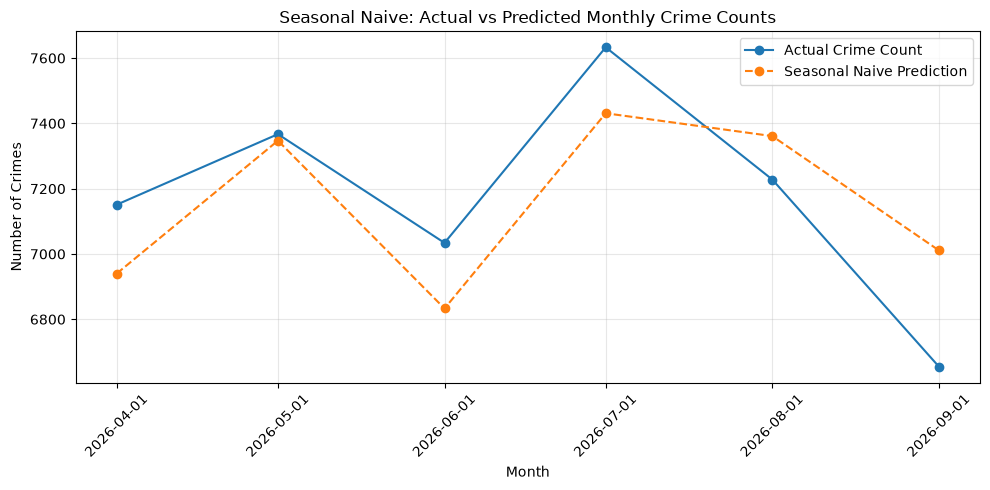

In [140]:
# STEP 8: Plot actual vs predicted monthly crime totals

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_evaluation["Month"],
    monthly_evaluation["Actual"],
    marker="o",
    label="Actual Crime Count"
)

plt.plot(
    monthly_evaluation["Month"],
    monthly_evaluation["Predicted"],
    marker="o",
    linestyle="--",
    label="Seasonal Naive Prediction"
)

plt.title("Seasonal Naive: Actual vs Predicted Monthly Crime Counts")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")
plt.xticks(monthly_evaluation["Month"], rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

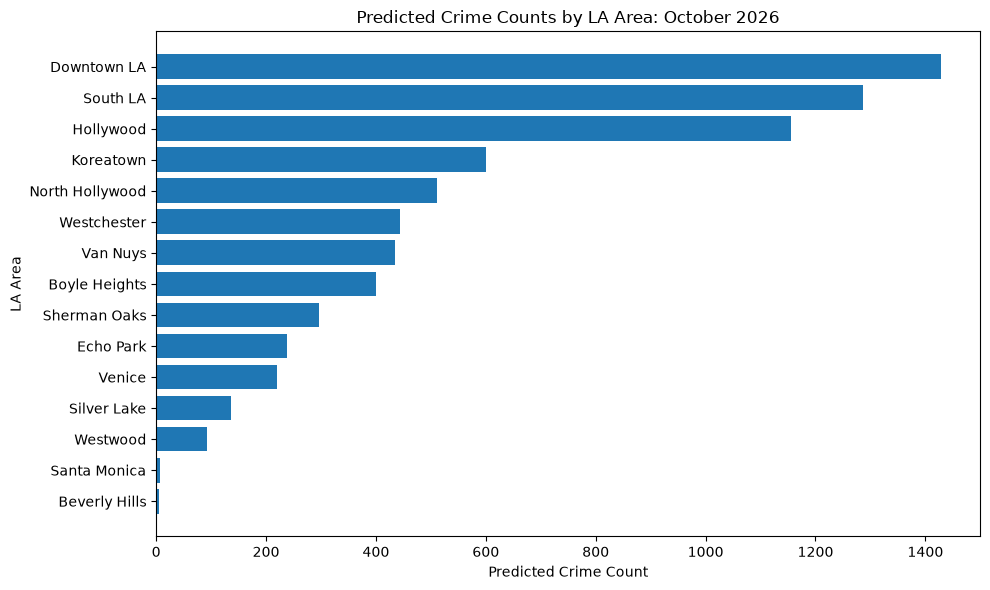

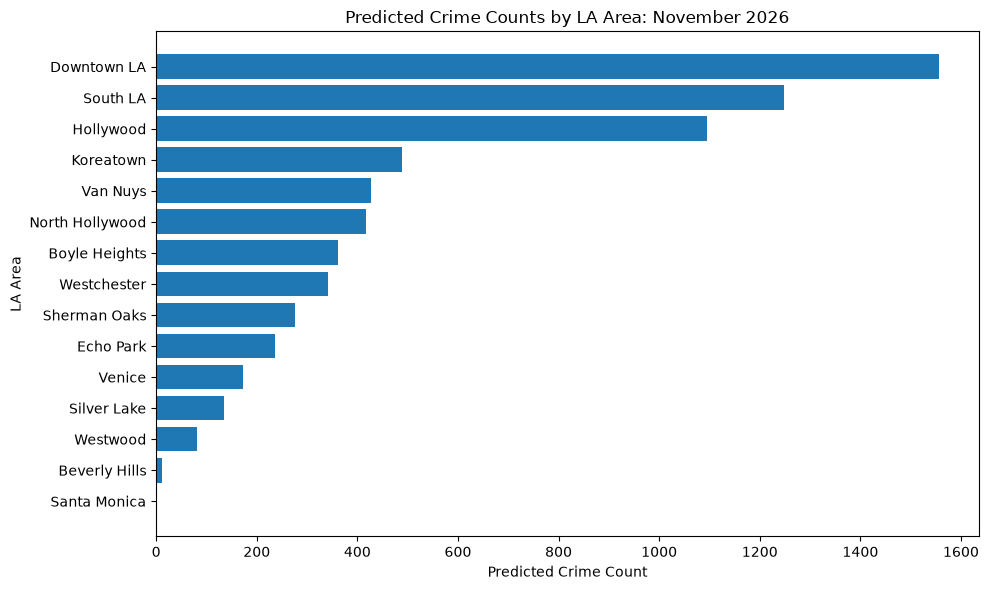

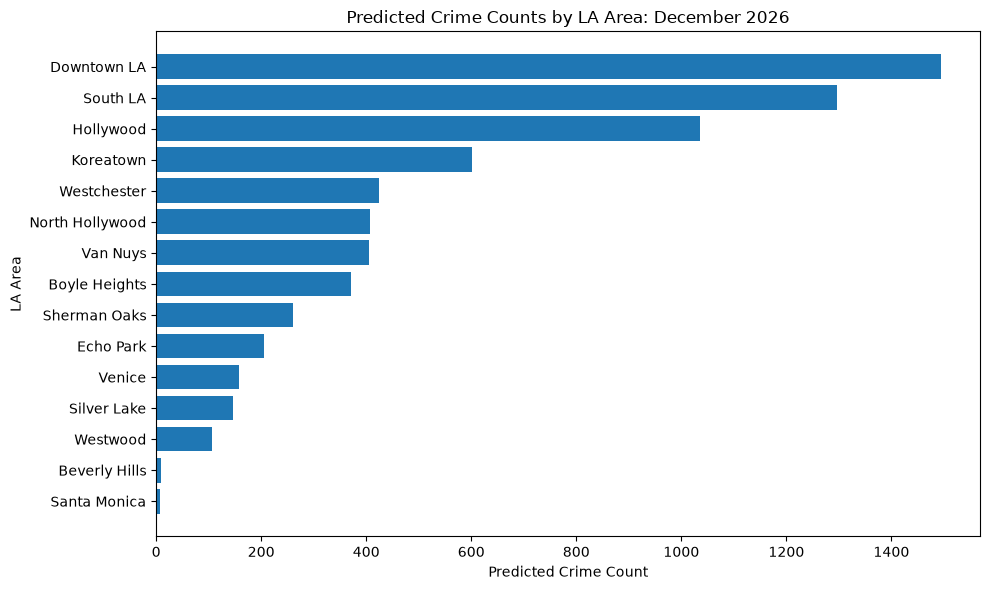

Area forecasts generated for all three months.


In [141]:
# STEP 9: Compare predicted crime counts across LA areas

import matplotlib.pyplot as plt
import pandas as pd

area_forecast = (
    crime_predictions
    .groupby(["Month", "LA Area"])["Predicted Crime Count"]
    .sum()
    .reset_index()
)

for month in sorted(area_forecast["Month"].unique()):
    month_data = (
        area_forecast[area_forecast["Month"] == month]
        .sort_values("Predicted Crime Count", ascending=True)
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        month_data["LA Area"],
        month_data["Predicted Crime Count"]
    )

    plt.title(f"Predicted Crime Counts by LA Area: {month:%B %Y}")
    plt.xlabel("Predicted Crime Count")
    plt.ylabel("LA Area")
    plt.tight_layout()
    plt.show()

print("Area forecasts generated for all three months.")

In [142]:
# STEP 10: Top predicted crime categories for each month

for month in sorted(crime_predictions["Month"].unique()):
    category_totals = (
        crime_predictions[crime_predictions["Month"] == month]
        .groupby("Crime Category")["Predicted Crime Count"]
        .sum()
        .sort_values(ascending=False)
    )

    print(f"\n{'=' * 50}")
    print(f"TOP CRIME CATEGORIES: {month:%B %Y}")
    print("=" * 50)

    display(category_totals.head(10).to_frame())


TOP CRIME CATEGORIES: October 2026


,Predicted Crime Count
Crime Category,
Assault & Battery,1385
Theft & Larceny,1049
Vehicle Theft,968
Burglary,805
Vandalism & Property Damage,745
Other Crimes,632
Fraud & Identity Theft,305
Robbery,251
Drug-Related Offenses,223



TOP CRIME CATEGORIES: November 2026


,Predicted Crime Count
Crime Category,
Assault & Battery,1322
Theft & Larceny,958
Vehicle Theft,904
Burglary,710
Vandalism & Property Damage,681
Other Crimes,660
Trespassing,317
Fraud & Identity Theft,248
Robbery,202



TOP CRIME CATEGORIES: December 2026


,Predicted Crime Count
Crime Category,
Assault & Battery,1248
Theft & Larceny,1011
Vehicle Theft,964
Burglary,778
Other Crimes,655
Vandalism & Property Damage,649
Trespassing,276
Fraud & Identity Theft,255
Robbery,250


In [143]:
# STEP 11: Export October-December 2026 forecasts

from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

forecast_output = crime_predictions.copy()

forecast_output["Month"] = pd.to_datetime(forecast_output["Month"])
forecast_output = forecast_output.sort_values(
    ["Month", "LA Area", "Crime Category"]
)

csv_path = OUTPUT_DIR / "crime_forecasts_oct_dec_2026.csv"
forecast_output.to_csv(csv_path, index=False)

print("Forecasts exported successfully!")
print(f"Saved to: {csv_path.resolve()}")
print(f"Prediction rows: {len(forecast_output):,}")
print(f"Unique areas: {forecast_output['LA Area'].nunique()}")
print(f"Unique categories: {forecast_output['Crime Category'].nunique()}")
print(f"Forecast months: {forecast_output['Month'].dt.strftime('%Y-%m').unique().tolist()}")
print(f"Total predicted crimes: {forecast_output['Predicted Crime Count'].sum():,.0f}")

Forecasts exported successfully!
Saved to: D:\STUDY\TY\DWM\dwml_project\outputs\crime_forecasts_oct_dec_2026.csv
Prediction rows: 810
Unique areas: 15
Unique categories: 18
Forecast months: ['2026-10', '2026-11', '2026-12']
Total predicted crimes: 21,033


In [145]:
# Inspect existing clustering outputs without modifying anything

print("=== CLUSTER SUMMARY ===")
display(cluster_summary.head())
print("Columns:", cluster_summary.columns.tolist())

print("\n=== MONTHLY CLUSTERS ===")
print("Shape:", monthly_clusters.shape)
print("Columns:", monthly_clusters.columns.tolist())

print("\n=== CLUSTERED DATA ===")
print("Shape:", clustered.shape)
print("Columns:", clustered.columns.tolist())

print("\n=== CLUSTER LABELS ===")
print(clustered["Cluster"].value_counts().head(10))

=== CLUSTER SUMMARY ===


,LA Area,Crime Category,Month,Cluster Key,LAT,LON,Records
0,Boyle Heights,Assault & Battery,2024-04,Boyle Heights|Assault & Battery|0,34.041317,-118.210244,86
1,Boyle Heights,Assault & Battery,2024-05,Boyle Heights|Assault & Battery|0,34.040196,-118.208737,96
2,Boyle Heights,Assault & Battery,2024-06,Boyle Heights|Assault & Battery|0,34.040302,-118.210005,105
3,Boyle Heights,Assault & Battery,2024-07,Boyle Heights|Assault & Battery|0,34.041734,-118.210750,94
4,Boyle Heights,Assault & Battery,2024-08,Boyle Heights|Assault & Battery|0,34.040038,-118.208627,99


Columns: ['LA Area', 'Crime Category', 'Month', 'Cluster Key', 'LAT', 'LON', 'Records']

=== MONTHLY CLUSTERS ===
Shape: (182371, 37)
Columns: ['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'TotalVictimCount', 'Victim Shot', 'Domestic Violence Crime', 'Hate Crime', 'Gang-related Crime', 'Transit-related Crime', 'Homeless-Victim Crime', 'Homeless-Suspect Crime', 'Homeless-Arrestee Crime', 'LOCATION', 'LAT', 'LON', 'Crime Category', 'geometry', 'index_right', 'LA Area', 'Cluster', 'Month']

=== CLUSTERED DATA ===
Shape: (185890, 36)
Columns: ['CaseNo', 'UniqueNIBRNo', 'Date Rptd', 'Date OCC', 'Time OCC', 'AREA', 'AREA NAME', 'RPT Dist No', 'TotalOffenseCount', 'Group', 'NIBR Code', 'NIBR Description', 'Crime Against', 'Premise Cd', 'Premise Desc', 'Weapon Used Cd', 'Weap

In [146]:
# STEP 12: Analyze historical hotspot patterns

import pandas as pd

historical_hotspots = cluster_summary.copy()

historical_hotspots["Month"] = pd.to_datetime(
    historical_hotspots["Month"].astype(str),
    format="%Y-%m"
)

print("Historical hotspot records:", len(historical_hotspots))
print("Unique areas:", historical_hotspots["LA Area"].nunique())
print("Unique crime categories:", historical_hotspots["Crime Category"].nunique())
print("Unique cluster keys:", historical_hotspots["Cluster Key"].nunique())
print(
    "Historical period:",
    historical_hotspots["Month"].min().strftime("%Y-%m"),
    "to",
    historical_hotspots["Month"].max().strftime("%Y-%m")
)

print("\nTop 10 most frequently appearing cluster keys:")
display(
    historical_hotspots["Cluster Key"]
    .value_counts()
    .head(10)
    .rename("Months Present")
    .to_frame()
)

print("\nMonthly records per cluster key:")
display(
    historical_hotspots.groupby("Cluster Key").size()
    .describe()
    .to_frame("Statistics")
)

Historical hotspot records: 8856
Unique areas: 13
Unique crime categories: 17
Unique cluster keys: 391
Historical period: 2024-04 to 2026-09

Top 10 most frequently appearing cluster keys:


,Months Present
Cluster Key,
Boyle Heights|Assault & Battery|0,30
Boyle Heights|Burglary|0,30
Boyle Heights|Other Crimes|0,30
Boyle Heights|Robbery|0,30
Boyle Heights|Theft & Larceny|0,30
Boyle Heights|Vandalism & Property Damage|0,30
Boyle Heights|Vehicle Theft|0,30
Boyle Heights|Weapons Offenses|0,30
Downtown LA|Assault & Battery|0,30



Monthly records per cluster key:


,Statistics
count,391.000000
mean,22.649616
std,6.991386
min,1.000000
25%,17.000000
50%,23.000000
75%,30.000000
max,30.000000


In [147]:
# STEP 13: Check forecast coverage against historical hotspots

print("=== FORECAST DATA ===")
print("Columns:", crime_predictions.columns.tolist())
print("Shape:", crime_predictions.shape)

print("\nForecast areas:")
print(sorted(crime_predictions["LA Area"].unique()))

print("\nForecast categories:")
print(sorted(crime_predictions["Crime Category"].unique()))

print("\n=== HOTSPOT COVERAGE ===")

forecast_areas = set(crime_predictions["LA Area"].unique())
hotspot_areas = set(historical_hotspots["LA Area"].unique())

forecast_categories = set(crime_predictions["Crime Category"].unique())
hotspot_categories = set(historical_hotspots["Crime Category"].unique())

print("Areas without historical hotspots:", sorted(forecast_areas - hotspot_areas))
print("Categories without historical hotspots:", sorted(forecast_categories - hotspot_categories))

print("\n=== PREDICTION MONTHS ===")
print(sorted(crime_predictions["Month"].astype(str).unique()))

=== FORECAST DATA ===
Columns: ['Month', 'LA Area', 'Crime Category', 'Predicted Crime Count']
Shape: (810, 4)

Forecast areas:
['Beverly Hills', 'Boyle Heights', 'Downtown LA', 'Echo Park', 'Hollywood', 'Koreatown', 'North Hollywood', 'Santa Monica', 'Sherman Oaks', 'Silver Lake', 'South LA', 'Van Nuys', 'Venice', 'Westchester', 'Westwood']

Forecast categories:
['Arson', 'Assault & Battery', 'Burglary', 'Domestic Violence', 'Drug-Related Offenses', 'Fraud & Identity Theft', 'Homicide', 'Kidnapping & Human Trafficking', 'Other Crimes', 'Robbery', 'Sexual Offenses', 'Theft & Larceny', 'Threats & Harassment', 'Traffic & DUI Offenses', 'Trespassing', 'Vandalism & Property Damage', 'Vehicle Theft', 'Weapons Offenses']

=== HOTSPOT COVERAGE ===
Areas without historical hotspots: ['Beverly Hills', 'Westwood']
Categories without historical hotspots: ['Kidnapping & Human Trafficking']

=== PREDICTION MONTHS ===
['2026-10-01', '2026-11-01', '2026-12-01']


In [149]:
# STEP 15: Consolidate each historical hotspot into one representative location

cluster_patterns = (
    hotspot_history
    .groupby(
        ["LA Area", "Crime Category", "Cluster Key"],
        as_index=False
    )
    .apply(
        lambda group: pd.Series({
            "LAT": np.average(group["LAT"], weights=group["Records"].clip(lower=1)),
            "LON": np.average(group["LON"], weights=group["Records"].clip(lower=1)),
            "Average_Monthly_Records": group["Records"].mean(),
            "Months_Observed": group["Month"].nunique()
        }),
        include_groups=False
    )
    .reset_index(drop=True)
)

print("Consolidated historical hotspots:", len(cluster_patterns))
print("Unique cluster keys:", cluster_patterns["Cluster Key"].nunique())
print("Duplicate area/category/cluster combinations:",
      cluster_patterns.duplicated(
          ["LA Area", "Crime Category", "Cluster Key"]
      ).sum())

display(cluster_patterns.head())

Consolidated historical hotspots: 391
Unique cluster keys: 391
Duplicate area/category/cluster combinations: 0


,LA Area,Crime Category,Cluster Key,LAT,LON,Average_Monthly_Records,Months_Observed
0,Boyle Heights,Assault & Battery,Boyle Heights|Assault & Battery|0,34.040065,-118.209576,89.966667,30.0
1,Boyle Heights,Burglary,Boyle Heights|Burglary|0,34.035672,-118.211037,23.600000,30.0
2,Boyle Heights,Domestic Violence,Boyle Heights|Domestic Violence|0,34.046487,-118.207713,2.520000,25.0
3,Boyle Heights,Drug-Related Offenses,Boyle Heights|Drug-Related Offenses|0,34.045565,-118.212088,3.888889,27.0
4,Boyle Heights,Fraud & Identity Theft,Boyle Heights|Fraud & Identity Theft|0,34.044794,-118.209819,1.880000,25.0


In [150]:
# STEP 16: Allocate forecast counts across historical hotspots

predicted_hotspots = []

# Index historical hotspots by area and category
hotspot_groups = {
    key: group.copy()
    for key, group in cluster_patterns.groupby(["LA Area", "Crime Category"])
}

unmapped_forecasts = []

for _, forecast_row in forecast_data.iterrows():
    area = forecast_row["LA Area"]
    category = forecast_row["Crime Category"]
    month = forecast_row["Month"]
    total_forecast = max(0, float(forecast_row["Predicted Crime Count"]))

    key = (area, category)
    locations = hotspot_groups.get(key)

    # No historical location available for this combination
    if locations is None or locations.empty:
        unmapped_forecasts.append({
            "Month": month,
            "LA Area": area,
            "Crime Category": category,
            "Predicted Crime Count": total_forecast,
            "Status": "No historical hotspot available"
        })
        continue

    weights = locations["Average_Monthly_Records"].clip(lower=0)

    # Equal distribution if all historical weights are zero
    if weights.sum() == 0:
        weights = pd.Series(1.0, index=locations.index)

    shares = weights / weights.sum()

    # Allocate integer counts while preserving the exact forecast total
    raw_counts = shares.to_numpy() * total_forecast
    allocated_counts = np.floor(raw_counts).astype(int)

    remainder = int(round(total_forecast)) - allocated_counts.sum()

    if remainder > 0:
        fractional_parts = raw_counts - allocated_counts
        largest_remainders = np.argsort(-fractional_parts)[:remainder]
        allocated_counts[largest_remainders] += 1

    for (_, hotspot), allocated_count in zip(
        locations.iterrows(), allocated_counts
    ):
        predicted_hotspots.append({
            "Month": month,
            "LA Area": area,
            "Crime Category": category,
            "Cluster Key": hotspot["Cluster Key"],
            "LAT": hotspot["LAT"],
            "LON": hotspot["LON"],
            "Predicted Crime Count": int(allocated_count),
            "Historical Average": hotspot["Average_Monthly_Records"],
            "Months Observed": hotspot["Months_Observed"]
        })

predicted_hotspots = pd.DataFrame(predicted_hotspots)
unmapped_forecasts = pd.DataFrame(unmapped_forecasts)

print("Predicted hotspot rows:", len(predicted_hotspots))
print("Unmapped forecast combinations:", len(unmapped_forecasts))

print("\nPredicted counts by month:")
display(
    predicted_hotspots.groupby("Month")["Predicted Crime Count"]
    .sum()
    .to_frame()
)

print("\nUnmapped combinations:")
display(unmapped_forecasts.head(10))

Predicted hotspot rows: 1173
Unmapped forecast combinations: 327

Predicted counts by month:


,Predicted Crime Count
Month,
2026-10-01,7044
2026-11-01,6641
2026-12-01,6704



Unmapped combinations:


,Month,LA Area,Crime Category,Predicted Crime Count,Status
0,2026-10-01,Beverly Hills,Arson,0.0,No historical hotspot available
1,2026-10-01,Beverly Hills,Assault & Battery,1.0,No historical hotspot available
2,2026-10-01,Beverly Hills,Burglary,0.0,No historical hotspot available
3,2026-10-01,Beverly Hills,Domestic Violence,0.0,No historical hotspot available
4,2026-10-01,Beverly Hills,Drug-Related Offenses,0.0,No historical hotspot available
5,2026-10-01,Beverly Hills,Fraud & Identity Theft,1.0,No historical hotspot available
6,2026-10-01,Beverly Hills,Homicide,0.0,No historical hotspot available
7,2026-10-01,Beverly Hills,Kidnapping & Human Trafficking,0.0,No historical hotspot available
8,2026-10-01,Beverly Hills,Other Crimes,0.0,No historical hotspot available
9,2026-10-01,Beverly Hills,Robbery,0.0,No historical hotspot available


In [151]:
# Inspect forecast combinations that could not be mapped to historical hotspots

print("=== UNMAPPED FORECAST SUMMARY ===")
print("Total unmapped rows:", len(unmapped_forecasts))

print("\nBy LA Area:")
display(
    unmapped_forecasts.groupby("LA Area").agg(
        Combinations=("Crime Category", "size"),
        Predicted_Crimes=("Predicted Crime Count", "sum")
    ).sort_values("Predicted_Crimes", ascending=False)
)

print("\nBy Crime Category:")
display(
    unmapped_forecasts.groupby("Crime Category").agg(
        Combinations=("LA Area", "size"),
        Predicted_Crimes=("Predicted Crime Count", "sum")
    ).sort_values("Predicted_Crimes", ascending=False)
)

print("\nPredictions with nonzero counts but no historical hotspot:")
display(
    unmapped_forecasts[
        unmapped_forecasts["Predicted Crime Count"] > 0
    ].sort_values("Predicted Crime Count", ascending=False).head(20)
)

=== UNMAPPED FORECAST SUMMARY ===
Total unmapped rows: 327

By LA Area:


,Combinations,Predicted_Crimes
LA Area,,
Westwood,54,281.0
Sherman Oaks,30,101.0
Silver Lake,27,37.0
South LA,9,36.0
Van Nuys,15,34.0
Boyle Heights,15,33.0
Beverly Hills,54,26.0
Echo Park,18,23.0
Venice,15,15.0



By Crime Category:


,Combinations,Predicted_Crimes
Crime Category,,
Theft & Larceny,6,77.0
Burglary,6,55.0
Threats & Harassment,15,53.0
Traffic & DUI Offenses,18,52.0
Sexual Offenses,27,47.0
Homicide,42,43.0
Trespassing,21,41.0
Assault & Battery,9,41.0
Vandalism & Property Damage,9,35.0



Predictions with nonzero counts but no historical hotspot:


,Month,LA Area,Crime Category,Predicted Crime Count,Status
320,2026-12-01,Westwood,Theft & Larceny,31.0,No historical hotspot available
311,2026-12-01,Westwood,Burglary,25.0,No historical hotspot available
102,2026-10-01,Westwood,Theft & Larceny,19.0,No historical hotspot available
211,2026-11-01,Westwood,Theft & Larceny,19.0,No historical hotspot available
93,2026-10-01,Westwood,Burglary,15.0,No historical hotspot available
92,2026-10-01,Westwood,Assault & Battery,13.0,No historical hotspot available
96,2026-10-01,Westwood,Fraud & Identity Theft,13.0,No historical hotspot available
201,2026-11-01,Westwood,Assault & Battery,12.0,No historical hotspot available
215,2026-11-01,Westwood,Vandalism & Property Damage,12.0,No historical hotspot available
74,2026-10-01,South LA,Homicide,11.0,No historical hotspot available


In [152]:
# Check historical crime records for unmapped area-category combinations

unmapped_pairs = (
    unmapped_forecasts[["LA Area", "Crime Category"]]
    .drop_duplicates()
)

historical_support = (
    cluster_data.groupby(["LA Area", "Crime Category"])
    .agg(
        Historical_Records=("Date OCC", "size"),
        Latitude=("LAT", "mean"),
        Longitude=("LON", "mean")
    )
    .reset_index()
)

unmapped_diagnosis = unmapped_pairs.merge(
    historical_support,
    on=["LA Area", "Crime Category"],
    how="left"
)

unmapped_diagnosis["Has_Historical_Data"] = (
    unmapped_diagnosis["Historical_Records"].fillna(0) > 0
)

print("Unmapped area-category pairs:", len(unmapped_diagnosis))
print(
    "Pairs with historical crime data:",
    unmapped_diagnosis["Has_Historical_Data"].sum()
)
print(
    "Pairs without historical crime data:",
    (~unmapped_diagnosis["Has_Historical_Data"]).sum()
)

display(
    unmapped_diagnosis.sort_values(
        "Historical_Records", ascending=True
    ).head(20)
)

Unmapped area-category pairs: 109
Pairs with historical crime data: 104
Pairs without historical crime data: 5


,LA Area,Crime Category,Historical_Records,Latitude,Longitude,Has_Historical_Data
14,Beverly Hills,Trespassing,1.0,34.090600,-118.394500,True
44,Santa Monica,Homicide,1.0,34.009700,-118.469500,True
68,Silver Lake,Kidnapping & Human Trafficking,1.0,34.087700,-118.284500,True
45,Santa Monica,Kidnapping & Human Trafficking,2.0,34.006100,-118.485550,True
41,Santa Monica,Domestic Violence,2.0,34.021000,-118.465050,True
4,Beverly Hills,Drug-Related Offenses,3.0,34.062267,-118.381133,True
17,Beverly Hills,Weapons Offenses,3.0,34.060367,-118.384800,True
10,Beverly Hills,Sexual Offenses,3.0,34.068267,-118.395033,True
98,Westwood,Kidnapping & Human Trafficking,3.0,34.058033,-118.438967,True
9,Beverly Hills,Robbery,4.0,34.059125,-118.390875,True


In [153]:
# Assess historical support for each unmapped area-category pair

def classify_support(records):
    if pd.isna(records) or records == 0:
        return "No historical data"
    elif records >= 30:
        return "Stronger support"
    elif records >= 10:
        return "Limited support"
    else:
        return "Weak support"


unmapped_diagnosis["Support Level"] = (
    unmapped_diagnosis["Historical_Records"]
    .apply(classify_support)
)

print("=== HISTORICAL SUPPORT LEVELS ===")
display(
    unmapped_diagnosis["Support Level"]
    .value_counts()
    .rename_axis("Support Level")
    .to_frame("Area-Category Pairs")
)

print("\n=== STRONGER-SUPPORT PAIRS ===")
display(
    unmapped_diagnosis[
        unmapped_diagnosis["Support Level"] == "Stronger support"
    ].sort_values("Historical_Records", ascending=False)
)

print("\n=== PREDICTED CRIMES BY SUPPORT LEVEL ===")
support_forecast = unmapped_forecasts.merge(
    unmapped_diagnosis[
        ["LA Area", "Crime Category", "Historical_Records", "Support Level"]
    ],
    on=["LA Area", "Crime Category"],
    how="left"
)

display(
    support_forecast.groupby("Support Level", dropna=False).agg(
        Combinations=("Crime Category", "size"),
        Predicted_Crimes=("Predicted Crime Count", "sum")
    )
)


=== HISTORICAL SUPPORT LEVELS ===


,Area-Category Pairs
Support Level,
Stronger support,47
Limited support,30
Weak support,27
No historical data,5



=== STRONGER-SUPPORT PAIRS ===


,LA Area,Crime Category,Historical_Records,Latitude,Longitude,Has_Historical_Data,Support Level
102,Westwood,Theft & Larceny,635.0,34.061325,-118.442352,True,Stronger support
93,Westwood,Burglary,467.0,34.061268,-118.438739,True,Stronger support
92,Westwood,Assault & Battery,412.0,34.060651,-118.441085,True,Stronger support
106,Westwood,Vandalism & Property Damage,317.0,34.060516,-118.440598,True,Stronger support
74,South LA,Homicide,261.0,33.968375,-118.282665,True,Stronger support
96,Westwood,Fraud & Identity Theft,235.0,34.061505,-118.439024,True,Stronger support
60,Sherman Oaks,Threats & Harassment,228.0,34.158956,-118.444540,True,Stronger support
107,Westwood,Vehicle Theft,220.0,34.060580,-118.439821,True,Stronger support
61,Sherman Oaks,Traffic & DUI Offenses,141.0,34.159442,-118.441825,True,Stronger support
21,Boyle Heights,Sexual Offenses,136.0,34.041563,-118.210493,True,Stronger support



=== PREDICTED CRIMES BY SUPPORT LEVEL ===


,Combinations,Predicted_Crimes
Support Level,,
Limited support,90,66.0
No historical data,15,0.0
Stronger support,141,567.0
Weak support,81,11.0


In [154]:
# STEP 17: Build fallback locations for missing historical hotspots

# Keep only area-category pairs with sufficient historical records
fallback_locations = unmapped_diagnosis[
    unmapped_diagnosis["Historical_Records"] >= 30
].copy()

fallback_locations = fallback_locations.rename(columns={
    "Latitude": "LAT",
    "Longitude": "LON"
})

fallback_locations["Cluster Key"] = (
    fallback_locations["LA Area"]
    + "|"
    + fallback_locations["Crime Category"]
    + "|ESTIMATED"
)

fallback_locations["Location Type"] = "Estimated from historical crime coordinates"

fallback_locations = fallback_locations[
    [
        "LA Area",
        "Crime Category",
        "Cluster Key",
        "LAT",
        "LON",
        "Historical_Records",
        "Location Type"
    ]
].reset_index(drop=True)

print("Fallback locations created:", len(fallback_locations))
print("Areas covered:", fallback_locations["LA Area"].nunique())
print("Categories covered:", fallback_locations["Crime Category"].nunique())

display(fallback_locations.head(10))

Fallback locations created: 47
Areas covered: 12
Categories covered: 18


,LA Area,Crime Category,Cluster Key,LAT,LON,Historical_Records,Location Type
0,Boyle Heights,Arson,Boyle Heights|Arson|ESTIMATED,34.037100,-118.209145,38.0,Estimated from historical crime coordinates
1,Boyle Heights,Homicide,Boyle Heights|Homicide|ESTIMATED,34.038716,-118.207637,51.0,Estimated from historical crime coordinates
2,Boyle Heights,Sexual Offenses,Boyle Heights|Sexual Offenses|ESTIMATED,34.041563,-118.210493,136.0,Estimated from historical crime coordinates
3,Boyle Heights,Traffic & DUI Offenses,Boyle Heights|Traffic & DUI Offenses|ESTIMATED,34.036460,-118.210845,126.0,Estimated from historical crime coordinates
4,Downtown LA,Kidnapping & Human Trafficking,Downtown LA|Kidnapping & Human Trafficking|EST...,34.042030,-118.252739,71.0,Estimated from historical crime coordinates
5,Echo Park,Domestic Violence,Echo Park|Domestic Violence|ESTIMATED,34.074855,-118.259122,60.0,Estimated from historical crime coordinates
6,Echo Park,Sexual Offenses,Echo Park|Sexual Offenses|ESTIMATED,34.071862,-118.259598,86.0,Estimated from historical crime coordinates
7,Echo Park,Traffic & DUI Offenses,Echo Park|Traffic & DUI Offenses|ESTIMATED,34.073491,-118.257694,67.0,Estimated from historical crime coordinates
8,Hollywood,Arson,Hollywood|Arson|ESTIMATED,34.099939,-118.320169,72.0,Estimated from historical crime coordinates
9,Hollywood,Homicide,Hollywood|Homicide|ESTIMATED,34.096710,-118.320959,83.0,Estimated from historical crime coordinates


In [155]:
# STEP 18: Combine historical and fallback hotspot locations

historical_locations = cluster_patterns.copy()
historical_locations["Location Type"] = "Historical DBSCAN hotspot"

fallback_locations_clean = fallback_locations[
    ["LA Area", "Crime Category", "Cluster Key", "LAT", "LON", "Location Type"]
].copy()

hotspot_locations = pd.concat(
    [
        historical_locations[
            ["LA Area", "Crime Category", "Cluster Key", "LAT", "LON", "Location Type"]
        ],
        fallback_locations_clean
    ],
    ignore_index=True
)

print("Historical DBSCAN hotspots:", len(historical_locations))
print("Fallback estimated locations:", len(fallback_locations_clean))
print("Total available locations:", len(hotspot_locations))
print("Missing coordinates:", hotspot_locations[["LAT", "LON"]].isna().any(axis=1).sum())

display(hotspot_locations.head(10))

Historical DBSCAN hotspots: 391
Fallback estimated locations: 47
Total available locations: 438
Missing coordinates: 0


,LA Area,Crime Category,Cluster Key,LAT,LON,Location Type
0,Boyle Heights,Assault & Battery,Boyle Heights|Assault & Battery|0,34.040065,-118.209576,Historical DBSCAN hotspot
1,Boyle Heights,Burglary,Boyle Heights|Burglary|0,34.035672,-118.211037,Historical DBSCAN hotspot
2,Boyle Heights,Domestic Violence,Boyle Heights|Domestic Violence|0,34.046487,-118.207713,Historical DBSCAN hotspot
3,Boyle Heights,Drug-Related Offenses,Boyle Heights|Drug-Related Offenses|0,34.045565,-118.212088,Historical DBSCAN hotspot
4,Boyle Heights,Fraud & Identity Theft,Boyle Heights|Fraud & Identity Theft|0,34.044794,-118.209819,Historical DBSCAN hotspot
5,Boyle Heights,Other Crimes,Boyle Heights|Other Crimes|0,34.042869,-118.212598,Historical DBSCAN hotspot
6,Boyle Heights,Other Crimes,Boyle Heights|Other Crimes|1,34.024748,-118.201265,Historical DBSCAN hotspot
7,Boyle Heights,Other Crimes,Boyle Heights|Other Crimes|2,34.059709,-118.214291,Historical DBSCAN hotspot
8,Boyle Heights,Robbery,Boyle Heights|Robbery|0,34.045335,-118.209831,Historical DBSCAN hotspot
9,Boyle Heights,Robbery,Boyle Heights|Robbery|1,34.023906,-118.217640,Historical DBSCAN hotspot


In [156]:
# STEP 19: Assign forecast counts to hotspot locations

location_groups = {
    key: group.copy()
    for key, group in hotspot_locations.groupby(["LA Area", "Crime Category"])
}

predicted_hotspots_final = []

for _, row in forecast_data.iterrows():
    key = (row["LA Area"], row["Crime Category"])
    count = row["Predicted Crime Count"]

    if count <= 0 or key not in location_groups:
        continue

    locations = location_groups[key]

    # Prefer actual historical DBSCAN hotspots
    historical = locations[
        locations["Location Type"] == "Historical DBSCAN hotspot"
    ]

    if not historical.empty:
        locations = historical
    else:
        locations = locations[
            locations["Location Type"] != "Historical DBSCAN hotspot"
        ]

    if locations.empty:
        continue

    # Allocate forecast proportionally to historical hotspot records
    weights = (
        cluster_patterns[
            (cluster_patterns["LA Area"] == key[0]) &
        (cluster_patterns["Crime Category"] == key[1])
        ]["Average_Monthly_Records"]
    )

    if len(weights) == len(locations) and weights.sum() > 0:
        weights = weights.to_numpy() / weights.sum()
    else:
        weights = np.ones(len(locations)) / len(locations)

    for (_, loc), weight in zip(locations.iterrows(), weights):
        predicted_hotspots_final.append({
            "Month": row["Month"],
            "LA Area": row["LA Area"],
            "Crime Category": row["Crime Category"],
            "Cluster Key": loc["Cluster Key"],
            "LAT": loc["LAT"],
            "LON": loc["LON"],
            "Predicted Crime Count": count * weight,
            "Location Type": loc["Location Type"]
        })

predicted_hotspots_final = pd.DataFrame(predicted_hotspots_final)

print("Predicted hotspot rows:", len(predicted_hotspots_final))
print("\nPredicted counts by month:")
display(
    predicted_hotspots_final.groupby("Month")["Predicted Crime Count"]
    .sum()
    .round(1)
    .to_frame()
)

print("\nLocation types:")
display(predicted_hotspots_final["Location Type"].value_counts())

Predicted hotspot rows: 1286

Predicted counts by month:


,Predicted Crime Count
Month,
2026-10-01,7234.0
2026-11-01,6826.0
2026-12-01,6896.0



Location types:


Location Type
Historical DBSCAN hotspot                      1164
Estimated from historical crime coordinates     122
Name: count, dtype: int64

In [157]:
# STEP 20: Check how much of the forecast has been mapped

forecast_totals = (
    forecast_data.groupby("Month")["Predicted Crime Count"]
    .sum()
    .rename("Original Forecast")
)

mapped_totals = (
    predicted_hotspots_final.groupby("Month")["Predicted Crime Count"]
    .sum()
    .rename("Mapped Forecast")
)

coverage_check = pd.concat(
    [forecast_totals, mapped_totals], axis=1
).fillna(0)

coverage_check["Unmapped Forecast"] = (
    coverage_check["Original Forecast"] -
    coverage_check["Mapped Forecast"]
)

coverage_check["Coverage %"] = (
    coverage_check["Mapped Forecast"] /
    coverage_check["Original Forecast"] * 100
).round(2)

display(coverage_check.round(1))


,Original Forecast,Mapped Forecast,Unmapped Forecast,Coverage %
Month,,,,
2026-10-01,7256,7234.0,22.0,99.7
2026-11-01,6850,6826.0,24.0,99.6
2026-12-01,6927,6896.0,31.0,99.6


In [158]:
# STEP 21: Prepare predicted hotspots for mapping

predicted_hotspots_final["Month"] = pd.to_datetime(
    predicted_hotspots_final["Month"]
)

predicted_hotspots_gdf = gpd.GeoDataFrame(
    predicted_hotspots_final.copy(),
    geometry=gpd.points_from_xy(
        predicted_hotspots_final["LON"],
        predicted_hotspots_final["LAT"]
    ),
    crs="EPSG:4326"
)

# Create readable month labels for map filters
predicted_hotspots_gdf["Forecast Month"] = (
    predicted_hotspots_gdf["Month"].dt.strftime("%B %Y")
)

# Assign marker colors by forecast month
month_colors = {
    "October 2026": "orange",
    "November 2026": "red",
    "December 2026": "purple"
}

predicted_hotspots_gdf["Map Color"] = (
    predicted_hotspots_gdf["Forecast Month"].map(month_colors)
)

print("Prediction map layer prepared!")
print("Rows:", len(predicted_hotspots_gdf))
print("Months:", predicted_hotspots_gdf["Forecast Month"].unique())
print("Invalid coordinates:",
      (~predicted_hotspots_gdf.geometry.is_valid).sum())

display(
    predicted_hotspots_gdf[
        ["Forecast Month", "LA Area", "Crime Category",
         "Predicted Crime Count", "Location Type", "geometry"]
    ].head()
)

Prediction map layer prepared!
Rows: 1286
Months: <StringArray>
['October 2026', 'November 2026', 'December 2026']
Length: 3, dtype: str
Invalid coordinates: 0


,Forecast Month,LA Area,Crime Category,Predicted Crime Count,Location Type,geometry
0,October 2026,Boyle Heights,Assault & Battery,95.0,Historical DBSCAN hotspot,POINT (-118.20958 34.04007)
1,October 2026,Boyle Heights,Burglary,30.0,Historical DBSCAN hotspot,POINT (-118.21104 34.03567)
2,October 2026,Boyle Heights,Domestic Violence,3.0,Historical DBSCAN hotspot,POINT (-118.20771 34.04649)
3,October 2026,Boyle Heights,Drug-Related Offenses,13.0,Historical DBSCAN hotspot,POINT (-118.21209 34.04556)
4,October 2026,Boyle Heights,Fraud & Identity Theft,12.0,Historical DBSCAN hotspot,POINT (-118.20982 34.04479)


In [159]:
# Find existing Folium maps in the notebook

[
    name for name, obj in globals().items()
    if isinstance(obj, folium.Map)
]

['crime_map', 'map_obj', 'm']

In [160]:
# STEP 23: Add predicted hotspots to the existing crime map

from folium.plugins import FeatureGroupSubGroup

prediction_layer = folium.FeatureGroup(
    name="🔮 Predicted Hotspots (Oct-Dec 2026)",
    show=True
)

for _, row in predicted_hotspots_gdf.iterrows():

    color = row["Map Color"]

    location_label = (
        "Estimated location"
        if row["Location Type"] == "Estimated from historical crime coordinates"
        else "Historical DBSCAN hotspot"
    )

    popup_html = f"""
    <div style="width:250px">
        <h4>Predicted Crime Hotspot</h4>
        <b>Forecast Month:</b> {row['Forecast Month']}<br>
        <b>LA Area:</b> {row['LA Area']}<br>
        <b>Crime Category:</b> {row['Crime Category']}<br>
        <b>Predicted Crime Count:</b> {row['Predicted Crime Count']:.1f}<br>
        <b>Location Type:</b> {location_label}<br>
        <hr>
        <small>Model-based estimate, not a confirmed future crime location.</small>
    </div>
    """

    folium.CircleMarker(
        location=[row["LAT"], row["LON"]],
        radius=5 + min(row["Predicted Crime Count"] ** 0.5, 10),
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.75,
        weight=1,
        popup=folium.Popup(popup_html, max_width=300),
        tooltip=(
            f"{row['Forecast Month']} | {row['LA Area']} | "
            f"{row['Crime Category']}: {row['Predicted Crime Count']:.1f}"
        )
    ).add_to(prediction_layer)

prediction_layer.add_to(crime_map)

folium.LayerControl(collapsed=False).add_to(crime_map)

crime_map.save("interactive_crime_map_with_predictions.html")

print("Prediction layer added!")
print("Saved as interactive_crime_map_with_predictions.html")

Prediction layer added!
Saved as interactive_crime_map_with_predictions.html
